# Deuterium Lamp Analysis Code

* Different analysis code for analyising light data recorded by a SiPM from a Deuterium Lamp Source.

## Compare Stability - 03/11/2026

* Wanted to compare stability measurements taken over all three holes/ windows with previous stability data
    * Observed decreasing stability over a 50min period, unseen before now
* Process the data, at the time of data collection routines weren't in place to make data output and use simple
* Plot and fit the data to compare the relative slope in stability 

### Define Functions for Sorting and Processing Raw Files

In [ ]:
# Definining functions needed to load data files and the combine them into one
# Essentially process the data for easy-use later

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

def load_single_file(file_path: Path):
    """
    Load a single .txt file and return the angle, photocurrent, and std arrays.
    Raises an exception if the file cannot be read or lacks required columns.
    """
    df = pd.read_csv(file_path)
    # Assumed format: angle_deg, epos, current_mean_A, current_std_A, n_samples
    angle = df["angle_deg"]
    photocurrent = df["current_mean_A"]
    # Standard error of the mean for this file
    photocurrent_std = (df["current_std_A"] / np.sqrt(df["n_samples"]))
    return angle, photocurrent, photocurrent_std


def putitin(file_name, num, times_df=None):
    if times_df is None:
        times_df = new_time_df

    files = sorted(Path(file_name).glob("*.txt"))

    # Select the 'Time' column only, as a plain array
    sel = times_df[times_df['rank'] == num]
    times = pd.to_datetime(sel['Date'].astype(str) + ' ' + sel['Time'].astype(str)).to_numpy()

    if len(files) != len(times):
        print(f"Warning: {len(files)} files but {len(times)} times for rank {num}")

    rows = []
    for target, t in zip(files, times):
        try:
            angle, photocurrent, photocurrent_std = load_single_file(target)
        except Exception as e:
            print(f"  Skipping {target.name}: failed to load/process ({e})")
            continue
        rows.append({
            "timestamp": t,
            "angle": angle[0],
            "photocurrent": photocurrent[0],
            "photocurrent_std": photocurrent_std[0],
        })

    return pd.DataFrame(rows, columns=["timestamp", "angle", "photocurrent", "photocurrent_std"])


### Load Files

In [45]:
# First I am going to merge the files as they weren't taken together...
time_data_path = r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-03)_Spectrum_calibration_data\dates.txt"

first_pos_dir_path = r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-03)_Spectrum_calibration_data\Peak_intensity_first_pos"
second_pos_dir_path = r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-03)_Spectrum_calibration_data\Peak_intensity_second_pos"
third_pos_dir_path = r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-03)_Spectrum_calibration_data\Peak_intensity_third_pos"

time_df = pd.read_csv(time_data_path)

### Sorting & Processing

In [46]:
# Sort the time data into ranks
repeat_arr = [1, 2, 3]
ranked_arr = pd.DataFrame(repeat_arr * (int((len(time_df))/len(repeat_arr))), columns=['rank'])
new_time_df = ranked_arr.join(time_df)
new_time_df.head()

,rank,Date,Time
0,1,2026-11-03,13:01:24
1,2,2026-11-03,13:02:50
2,3,2026-11-03,13:04:18
3,1,2026-11-03,13:06:22
4,2,2026-11-03,13:07:58


### Outputted Data

In [47]:
first_hole_data = putitin(first_pos_dir_path, num=1, times_df=new_time_df)
second_hole_data = putitin(second_pos_dir_path, num=2, times_df=new_time_df)
third_hole_data = putitin(third_pos_dir_path, num=3, times_df=new_time_df)

In [103]:
first_hole_data.head()

,timestamp,angle,photocurrent,photocurrent_std
0,2026-11-03 13:01:24,7.8,6.509413330000001e-05,2.582466630957884e-08
1,2026-11-03 13:06:22,7.8,6.419439420000001e-05,2.0091565992813984e-08
2,2026-11-03 13:11:24,7.8,6.39840002e-05,1.758339846046829e-08
3,2026-11-03 13:16:34,7.8,6.385249760000001e-05,1.984809386571921e-08
4,2026-11-03 13:21:24,7.8,6.39206201e-05,1.710488132755967e-08


### Define Analysis Functions & Run Them

Hole 1: slope = -1.645e-08 A/min, intercept = 6.434e-05 A, drift = -1.542% / hr
Hole 2: slope = -1.055e-08 A/min, intercept = 6.388e-05 A, drift = -0.995% / hr
Hole 3: slope = -3.090e-09 A/min, intercept = 6.261e-05 A, drift = -0.296% / hr


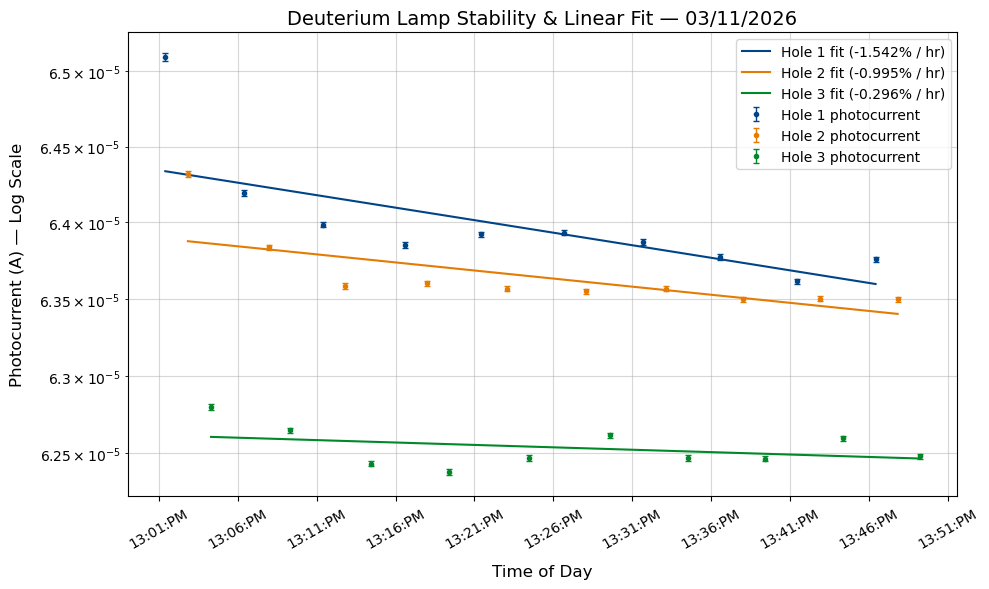

In [92]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


def linear_fit(time_min, y, yerr):
    """Weighted linear fit. Returns slope, intercept, fitted line."""
    m, c = np.polyfit(time_min, y, 1, w=1 / yerr)   # w = 1/sigma
    return m, c, m * time_min + c


def prepare(df):
    """Drop bad rows and add elapsed minutes since the first point."""
    df = df.dropna(subset=['timestamp', 'photocurrent', 'photocurrent_std']).copy()
    df = df[df['photocurrent_std'] > 0]              # avoid divide-by-zero weights
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df = df.sort_values('timestamp').reset_index(drop=True)
    df['t_min'] = (df['timestamp'] - df['timestamp'].iloc[0]).dt.total_seconds() / 60
    return df


datasets = [
    ("Hole 1", first_hole_data,  '#004488'),
    ("Hole 2", second_hole_data, "#E47B03"),
    ("Hole 3", third_hole_data,  '#008829'),
]

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_yscale('log')

for label, raw, colour in datasets:
    df = prepare(raw)
    if len(df) < 2:
        print(f"{label}: not enough valid points to fit ({len(df)})")
        continue
        
    slope, intercept, fit_line = linear_fit(
        df['t_min'].to_numpy(),
        df['photocurrent'],
        df['photocurrent_std'],
    )

    # Drift relative to the fitted value at the start, in % per hour
    slope_pct_per_hour = 100 * slope * 60 / np.mean(df['photocurrent'])

    ax.errorbar(df['timestamp'], df['photocurrent'], yerr=df['photocurrent_std'],
                fmt='o', color=colour, markersize=3, elinewidth=1, capsize=2,
                label=f'{label} photocurrent')
    ax.plot(df['timestamp'], fit_line, color=colour, linestyle='-', linewidth=1.5,
            label=f'{label} fit ({slope_pct_per_hour:+.3f}% / hr)')

    print(f"{label}: slope = {slope:.3e} A/min, intercept = {intercept:.3e} A, "
          f"drift = {slope_pct_per_hour:+.3f}% / hr")

ax.set_title('Deuterium Lamp Stability & Linear Fit — 03/11/2026', fontsize=14)
ax.set_xlabel('Time of Day', fontsize=12, labelpad=10)
ax.set_ylabel('Photocurrent (A) — Log Scale', fontsize=12, labelpad=10)
ax.grid(True, which='both', alpha=0.5)

# One tick every 10 minutes, 24-hour format to match your timestamps
ax.xaxis.set_major_locator(mdates.MinuteLocator(interval=5))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%p'))
ax.tick_params(axis='x', rotation=30)

ax.legend(loc='upper right')
fig.tight_layout()

#plt.savefig("test3.png", dpi=600, bbox_inches='tight')

plt.show()

## Calibrating Hole Position for the Peak Intensity - 05/11/2026

* Performed meaurements at 7.8 deg (160nm) for a range of linear actuator positions (corresponds with different positions of the plate with the windows)
* Take these measurements for photocurrent and look at how they change as we scan across the plate, over the windows and the blind bits
* From the data we can then confirm/determine the positions at which to take data for the maximum intensity of light
* This will be written up to be part of a calibration script to make sure the most optimal positions are the same/ so we can then select them if they changed

**NOTE**: Be worth adding peak finding to then output the peaks... so they can be used when taking data

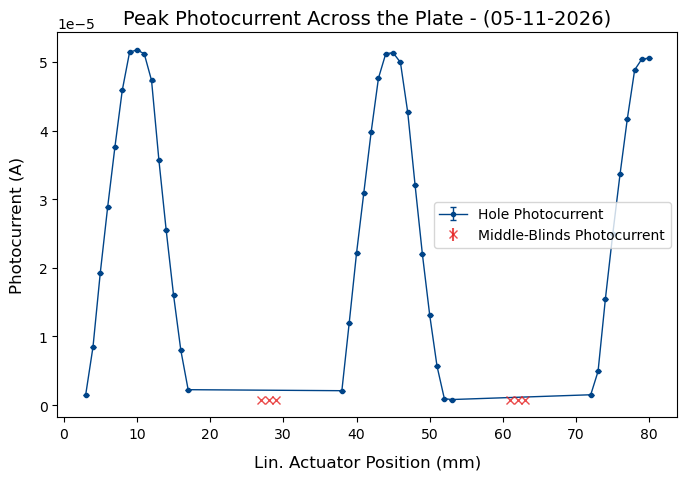

In [ ]:
# 05/11/2026 - Windows and Middle Blinds

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# First I am going to merge the files as they weren't taken together...
pos_windows_data_path = r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-05)_Data\positions_each_window_160nm_not_spectrum.txt"
pos_blinds_data_path = r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-05)_Data\positions_each_middle_blind_160nm_not_spectrum.txt"
photocurrent_windows_data_path = r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-05)_Data\scan_across_each_window_160nm_not_spectrum.txt"
photocurrent_blinds_data_path = r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-05)_Data\scan_across_each_middle_blind_160nm_not_spectrum.txt"

pos_windows_df = pd.read_csv(pos_windows_data_path)
photocurrent_windows_df = pd. read_csv(photocurrent_windows_data_path)
pos_blinds_df = pd.read_csv(pos_blinds_data_path)
photocurrent_blinds_df = pd. read_csv(photocurrent_blinds_data_path)


fig, ax = plt.subplots(figsize=(8, 5))

ax.errorbar(pos_windows_df['pos'], photocurrent_windows_df['current_mean_A'], photocurrent_windows_df['current_std_A'] / np.sqrt(photocurrent_windows_df['n_samples']), 
            color='#004488', linestyle='-', linewidth=1, fmt='o', markersize=3, elinewidth=1, capsize=2, label=f'Hole Photocurrent')

ax.errorbar(pos_blinds_df['pos'], photocurrent_blinds_df['current_mean_A'], photocurrent_blinds_df['current_std_A'] / np.sqrt(photocurrent_blinds_df['n_samples']), color="#E62424D1", fmt='x', label=f'Middle-Blinds Photocurrent')

ax.set_title(f'Peak Photocurrent Across the Plate - (05-11-2026)', fontsize=14)
ax.set_xlabel('Lin. Actuator Position (mm)', fontsize=12, labelpad=10)
ax.set_ylabel('Photocurrent (A)', fontsize=12, labelpad=10)
#ax.set_yscale('log')

plt.legend(loc='center right')
plt.show()



## Comparing Stability Ratios for the Alignment (19/11/2026)
* Wanting to compare ratios of stability and how they change each time we re-align the system (also check it after we have left the system over night or after just opening it)
* Re-use some of the code from the current_dashboard.py in the monochromator repo

* Load files
* Get the ratios of 10/45 and 79/45... interpolated ones
* Take average and std then plot together...

* Take the weighted mean as the points are correlated following interpolation and they should be the same value and not drift... (otherwise would use the standard deviation)

origin                    2026-11-18 16:28:42
after_opening             2026-11-18 18:29:53
repeat                    2026-11-19 11:05:14


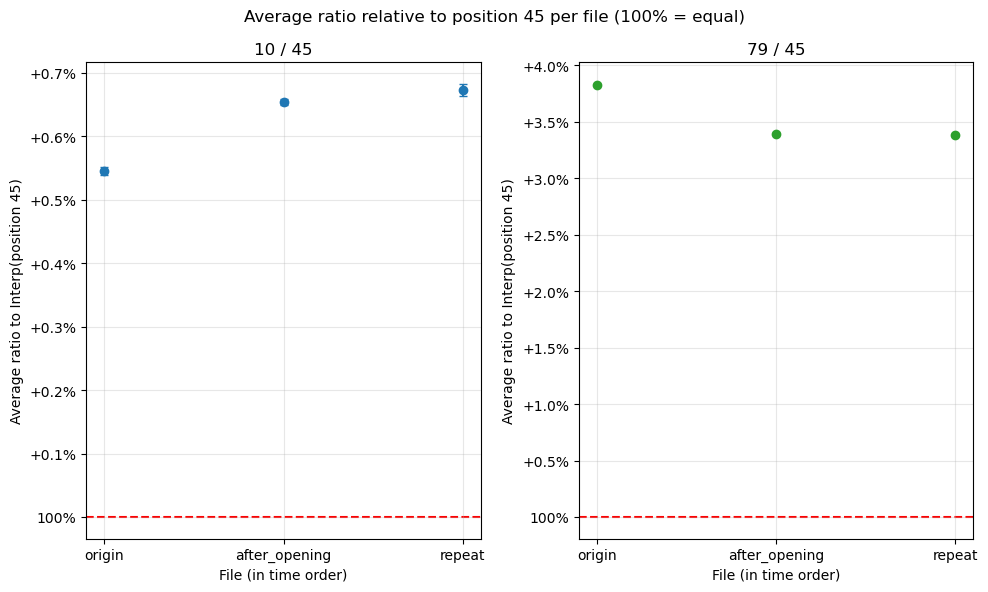

           label  position  mean_ratio_%     err_%
0         origin        10    100.545438  0.005698
1  after_opening        10    100.653925  0.005150
2         repeat        10    100.673481  0.009113
3         origin        79    103.830725  0.005294
4  after_opening        79    103.393849  0.004896
5         repeat        79    103.381322  0.009101


In [58]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

def _load(file):
    """
    Loads file, adds t_min column and converts standard deviation to
    standard error on the mean.
    """
    df = file.copy() if isinstance(file, pd.DataFrame) else pd.read_csv(file)
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df = df.sort_values("timestamp").reset_index(drop=True)
    df["t_min"] = (df["timestamp"] - df["timestamp"].iloc[0]).dt.total_seconds() / 60
    df["err"] = df["current_std_A"] / df["n_samples"] ** 0.5
    return df

def get_label(file):
    """Strip the common prefix/suffix from the file stem to leave the unique label."""
    return (Path(file).stem
            .removeprefix("no_windows_improve_tilt_")
            .removesuffix("_30mins_spectrum"))

def _first_timestamp(file):
    """Earliest timestamp in a file (reads only the timestamp column)."""
    s = pd.read_csv(file, usecols=["timestamp"])["timestamp"]
    return pd.to_datetime(s).min()

def _reorder(files):
    """Return the same files (paths), sorted by their first timestamp."""
    return sorted(files, key=_first_timestamp)

def _ratio_err(r, i_num, e_num, i_den, e_den):
    """Relative-error propagation for r = num/den."""
    return np.abs(r) * np.sqrt((e_num / i_num) ** 2 + (e_den / i_den) ** 2)

def _adjacent_pairs(df, ref_pos, pos):
    """
    For every ref_pos row k, find the row of `pos` directly next to it in the
    measurement sequence (row k-1 or k+1). If both neighbours are `pos`, take the
    one closest in time. Returns a list of (k, j) row-index pairs.
    """
    pairs = []
    for k in df.index[df["position"] == ref_pos]:
        cands = [j for j in (k - 1, k + 1)
                 if 0 <= j < len(df) and df.at[j, "position"] == pos]
        if not cands:
            continue
        j = min(cands, key=lambda j: abs(df.at[j, "t_min"] - df.at[k, "t_min"]))
        pairs.append((k, j))
    return pairs

def _weighted_mean(r, r_err):
    """Inverse-variance weighted mean and its uncertainty."""
    w = 1.0 / r_err ** 2
    mean = np.sum(w * r) / np.sum(w)
    err = 1.0 / np.sqrt(np.sum(w))
    return mean, err

def _file_ratios(df, ref_pos):
    """
    For one loaded file, return {pos: (mean_ratio, err)} where the ratio is each
    other position's adjacent point divided by ref_pos interpolated to that
    point's own time, averaged over the whole file (inverse-variance weighted).
    Ratios are fractions (1.0 = 100%).
    """
    out = {}

    ref_s = df[df["position"] == ref_pos].sort_values("t_min")
    t_ref = ref_s["t_min"].to_numpy()
    i_ref_all = ref_s["current_mean_A"].to_numpy()
    e_ref_all = ref_s["err"].to_numpy()

    if len(t_ref) < 2:
        return out

    others = [p for p in sorted(df["position"].unique()) if p != ref_pos]
    for pos in others:
        j_idx = sorted({j for _, j in _adjacent_pairs(df, ref_pos, pos)})
        oth = df.loc[j_idx]
        oth = oth[(oth["t_min"] >= t_ref.min()) & (oth["t_min"] <= t_ref.max())]
        if oth.empty:
            continue

        t = oth["t_min"].to_numpy()
        idx = np.clip(np.searchsorted(t_ref, t, side="right"), 1, len(t_ref) - 1)
        t0, t1 = t_ref[idx - 1], t_ref[idx]
        w1 = (t - t0) / (t1 - t0)
        w0 = 1 - w1
        i_interp = w0 * i_ref_all[idx - 1] + w1 * i_ref_all[idx]
        e_interp = np.sqrt((w0 * e_ref_all[idx - 1]) ** 2 + (w1 * e_ref_all[idx]) ** 2)

        i_oth = oth["current_mean_A"].to_numpy()
        e_oth = oth["err"].to_numpy()
        r = i_oth / i_interp
        r_err = _ratio_err(r, i_oth, e_oth, i_interp, e_interp)

        good = np.isfinite(r) & np.isfinite(r_err) & (r_err > 0)
        if not good.any():
            continue
        out[pos] = _weighted_mean(r[good], r_err[good])

    return out

# Plotting 
def _pct_tick_label(x, _pos):
    """100 -> '100%'; anything else -> signed offset from 100% (e.g. '+0.5%')."""
    d = x - 100.0
    if abs(d) < 1e-9:
        return "100%"
    return f"{d:+.1f}%"

def _style_pct_axis(ax):
    ax.axhline(100, color="red", linestyle="--", linewidth=1.5, zorder=1)
    ax.yaxis.set_major_formatter(FuncFormatter(_pct_tick_label))
    ax.grid(alpha=0.3)

def plot_ratios(source, ref_pos=45, labels=None, colors=None, save_path=None, show=True,
                figsize=None, dpi=600):
    """
    One panel per non-reference position (e.g. 10/45, 79/45). In each panel the
    x-axis is the file (in the order given) and the y-axis is that file's average
    ratio (%), with the weighted uncertainty as the error bar.

    source : list of file paths (or DataFrames), already in the order you want
    labels : x-axis labels, one per file; defaults to get_label(file)

    Returns (fig, axes, summary) where summary is a DataFrame of the plotted values.
    """
    n = len(source)
    if colors is None:
        colors = {10: "C0", 79: "C2"}   # position -> matplotlib colour    
    if labels is None:
        labels = [get_label(f) if not isinstance(f, pd.DataFrame) else f"file {i + 1}"
                  for i, f in enumerate(source)]

    # Average ratio per position for every file
    # List of all unique positions measured 
    # (we only really care for pos 10, 79 where 45v is our reference)
    results = [_file_ratios(_load(f), ref_pos) for f in source]
    others = sorted({p for res in results for p in res}) 

    # If there are no other positions except the reference
    if not others:
        raise ValueError(f"No ratios could be computed for ref_pos={ref_pos}")

    if figsize is None:
        figsize = (max(5, 0.8 * n) * len(others), 6)

    fig, axes = plt.subplots(1, len(others), figsize=figsize, squeeze=False)
    axes = axes[0]
    color_idx = 0
    rows = []
    for k, (ax, pos) in enumerate(zip(axes, others)):
        color = colors.get(pos, f"C{k}")   # fallback for positions not in the dict
        xs, ys, es = [], [], []
        for i, (res, lab) in enumerate(zip(results, labels)):
            if pos not in res:
                continue
            mean, err = res[pos]
            xs.append(i)
            ys.append(mean * 100)
            es.append(err * 100)
            rows.append({"label": lab, "position": pos, "mean_ratio_%": mean * 100, "err_%": err * 100})

        ax.errorbar(xs, ys, yerr=es, marker="o", linestyle="None", capsize=3,
                    color=color)
        color_idx += 2
        _style_pct_axis(ax)
        ax.set_xticks(range(n))
        # ax.set_xticklabels(labels, rotation=45, ha="right")
        ax.set_xticklabels(labels)
        ax.set_xlabel("File (in time order)")
        ax.set_ylabel(f"Average ratio to Interp(position {ref_pos})")
        ax.set_title(f"{pos} / {ref_pos}")

    fig.suptitle(f"Average ratio relative to position {ref_pos} per file "
                 "(100% = equal)")
    fig.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=dpi)
    if show:
        plt.show()
    return fig, axes, pd.DataFrame(rows)


# Main

# Directory with all the files to compare
dir_name = r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\Data\(2026-11-19)_Data"

# Defing colours so consistent with other plots
colors = {10: "C0", 79: "C2"}

# Collect all the relevant files and sort them by first timestamp (names may have changed so the ordering changes)
files = sorted(Path(dir_name).glob("*.txt"))
files_sorted = _reorder(files)
labels = [get_label(f) for f in files_sorted]

# Validate the order: timestamps should be ascending
for f, lab in zip(files_sorted, labels):
    print(f"{lab:25s} {_first_timestamp(f)}")

fig, axes, summary = plot_ratios(files_sorted, ref_pos=45, labels=labels, colors={10: "C0", 79: "C2"}, save_path=None, show=True, dpi=600)
print(summary)

array([ 5, 10, 15])

In [39]:
#Path(files[0]).stem
Path(files[0]).stem.lstrip("no_windows_improve_tilt_").rstrip("_30mins_spectrum")

'after_opening'

## Same Sorting & Processing as Before but with Saving Functionality - 09/11/2026 

* resuse some of the code.
* !! rewrite to sort based on the position number... use the code to create an array of unique positions then sort based on that

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

#file_path = Path(r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-09)_Data\hour_1_spectrum.txt")
#file_path = Path(r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-09)_Data\hour_2_spectrum.txt")
file_path = Path(r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\Data\(2026-10-11)_Stability_data\D2lamp_128nm_stability.txt")

df = pd.read_csv(file_path)
#df.drop(columns=['position'], axis=1, inplace=True)
#df = pd.DataFrame([45] * len(df), columns=['position']).join(df)
df.head()
#df.to_csv(file_path, index=False)

In [30]:
# Sort the time data into ranks
repeat_arr = [1, 2, 3, 2]
ranked_arr = pd.DataFrame(repeat_arr * (int((len(df))/len(repeat_arr))), columns=['hole_num'])
ranked_df = ranked_arr.join(df)

ranked_df.head()

,hole_num,timestamp,position,angle_deg,epos,current_mean_A,current_std_A,n_samples
0,1,2026-11-09T11:56:21,10,7.8,7.795,0.000064,9.998833e-08,100
1,2,2026-11-09T11:57:36,45,7.8,7.795,0.000064,8.343818e-08,100
2,3,2026-11-09T11:58:49,79,7.8,7.795,0.000063,1.139433e-07,100
3,2,2026-11-09T12:00:03,45,7.8,7.795,0.000064,1.042235e-07,100
4,1,2026-11-09T12:01:18,10,7.8,7.795,0.000064,1.019054e-07,100


In [31]:
# Select the sorted data and then output/ save as txt file
for num in repeat_arr:
    print(num)
    sel = ranked_df[ranked_df['hole_num'] == num]
    sel.drop(columns=['hole_num'], axis=1, inplace=True)
    print(sel[:10])
    sel.to_csv(f"hour_3to4_spectrum_hole_num_{num}.txt", index=False)
    

1
              timestamp  position  angle_deg   epos  current_mean_A  \
0   2026-11-09T11:56:21        10        7.8  7.795        0.000064   
4   2026-11-09T12:01:18        10        7.8  7.795        0.000064   
8   2026-11-09T12:06:15        10        7.8  7.795        0.000064   
12  2026-11-09T12:11:12        10        7.8  7.795        0.000064   
16  2026-11-09T12:16:09        10        7.8  7.795        0.000064   
20  2026-11-09T12:21:06        10        7.8  7.795        0.000064   
24  2026-11-09T12:26:03        10        7.8  7.795        0.000064   
28  2026-11-09T12:31:00        10        7.8  7.795        0.000064   
32  2026-11-09T12:35:57        10        7.8  7.795        0.000064   
36  2026-11-09T12:40:54        10        7.8  7.795        0.000064   

    current_std_A  n_samples  
0    9.998833e-08        100  
4    1.019054e-07        100  
8    1.225336e-07        100  
12   1.097715e-07        100  
16   9.436665e-08        100  
20   1.259135e-07        100  

C:\Users\laugh\AppData\Local\Temp\ipykernel_15284\3622504915.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sel.drop(columns=['hole_num'], axis=1, inplace=True)
C:\Users\laugh\AppData\Local\Temp\ipykernel_15284\3622504915.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sel.drop(columns=['hole_num'], axis=1, inplace=True)
C:\Users\laugh\AppData\Local\Temp\ipykernel_15284\3622504915.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-c

## Done before me - DATA TAKEN WITHOUT VACUUM

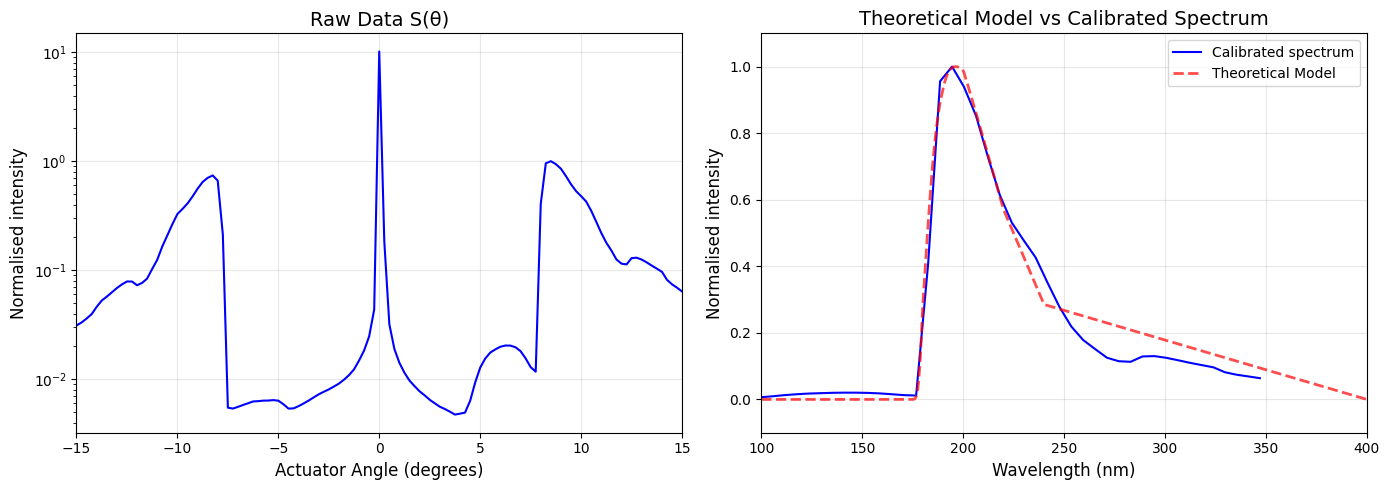

In [ ]:
""" # DATA TAKEN WITHOUT VACUUM - DATA AND THEORETICAL MODEL COMPARISON

import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks


def actuator_angle_to_wavelength(theta_deg):
    # Equation 20 of Max's report: m * lambda = 2 * d * cos(phi) * sin(gamma * (theta - theta0))

    d = 835.5          # nm (1 / 1200 lines/mm)
    phi = 35           # degrees (half deviation angle)
    gamma = 1.0028     # actuator scaling factor, Max's : 1.0028
    theta0 = 0.35      # degrees (angular offset), Max's : 1.502
    m = 1              # first diffraction order

    theta_rad = np.radians(theta_deg)
    theta0_rad = np.radians(theta0)
    phi_rad = np.radians(phi)

    C = 2 * d * np.cos(phi_rad)  # ≈ 1365 nm

    wavelength = (C * np.sin(gamma * (theta_rad - theta0_rad))) / m

    return wavelength

# Spectrum from Deuterium Lamp Datasheet
deuterium_wavelengths = np.array([114, 120, 122, 124, 126, 130, 132, 136, 140, 144, 148, 150, 156, 158, 161, 165, 170, 180, 200, 220, 240, 400])
deuterium_intensities = np.array([0, 42, 50, 35, 56, 25, 34, 22, 28, 26, 36, 32, 50, 155, 200, 40, 10, 8, 7, 4, 2, 0])

# Air lenght attenuation as a fonction of wavelenght
attenuation_wavelengths = np.array([50, 100, 150, 160, 170, 180, 190, 200, 210, 220, 230, 240, 250, 260, 270, 280, 290, 300, 310, 320, 330, 340, 350, 360, 370, 380, 390, 400])
attenuation_lengths_m = np.array([1e-6, 10e-6, 0.1e-3, 1e-3, 0.01, 0.5, 5, 75, 750, 5000, 20000, 50000, 100000, 200000, 500000, 1000000, 2000000, 5000000, 10000000, 20000000, 50000000, 100000000, 200000000, 300000000, 500000000, 700000000, 1000000000, 1000000000])

def attenuation_length(lambda_nm):
    log_lengths = np.log10(attenuation_lengths_m)
    log_interp = np.interp(lambda_nm, attenuation_wavelengths, log_lengths, left=np.log10(1e-9), right=np.log10(1e12))
    return 10 ** log_interp

def air_transmission(lambda_nm, PATH_LENGTH=0.7):
    L_atten = attenuation_length(lambda_nm)
    L_atten_safe = np.where(L_atten < 1e-15, 1e-15, L_atten)
    return np.exp(-PATH_LENGTH / L_atten_safe)

PDE_CONSTANT = 0.24
PATH_LENGTH = 0.7 # Distance between

def model_spectrum(lambda_nm):
    D = np.interp(lambda_nm, deuterium_wavelengths, deuterium_intensities, left=0, right=0)
    T = air_transmission(lambda_nm, PATH_LENGTH)
    return D * PDE_CONSTANT * T

lambda_range = np.linspace(100, 400, 500)
S_lambda = model_spectrum(lambda_range)
S_lambda_norm = S_lambda / np.max(S_lambda)

# Calibration of the measured data
file_path = r"C:/Users/leaga/OneDrive - USherbrooke/Internship UoM/VUV Monochromator/2. Deuterium Lamp/No vacuum/deuterium_test2.txt"
data = np.loadtxt(file_path, delimiter=',', usecols=(0, 1))

angle = data[:, 0]
photocurrent = data[:, 1]

wavelength_calibrated = actuator_angle_to_wavelength(angle)

# Normalization only within the 100–400 nm range for calibrated data
mask = (wavelength_calibrated >= 100) & (wavelength_calibrated <= 400)
photocurrent_norm = photocurrent / np.max(photocurrent[mask])

# Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1 : Raw data
axes[0].plot(angle, photocurrent_norm, 'b-', linewidth=1.5)
axes[0].set_xlabel('Actuator Angle (degrees)', fontsize=12)
axes[0].set_ylabel('Normalised intensity', fontsize=12)
axes[0].set_title('Raw Data S(θ)', fontsize=14)
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim(-15, 15)
axes[0].set_yscale('log')

# Plot 2 : Calibrated data vs theoretical model
axes[1].plot(wavelength_calibrated, photocurrent_norm, 'b-', linewidth=1.5, label='Calibrated spectrum')
axes[1].plot(lambda_range, S_lambda_norm, 'r--', linewidth=2, alpha=0.7, label='Theoretical Model')
axes[1].set_xlabel('Wavelength (nm)', fontsize=12)
axes[1].set_ylabel('Normalised intensity', fontsize=12)
axes[1].set_title('Theoretical Model vs Calibrated Spectrum', fontsize=14)
axes[1].grid(True, alpha=0.3)
axes[1].legend()
axes[1].set_xlim(100, 400)
axes[1].set_ylim(-0.1,1.1)

plt.tight_layout()

save_path = "C:/Users/leaga/OneDrive - USherbrooke/Internship UoM/VUV Monochromator/2. Deuterium Lamp/No vacuum"
plt.savefig(save_path, dpi=300, bbox_inches='tight')

plt.show() """

## Done before me - FULL CALIBRATED SPECTRUM

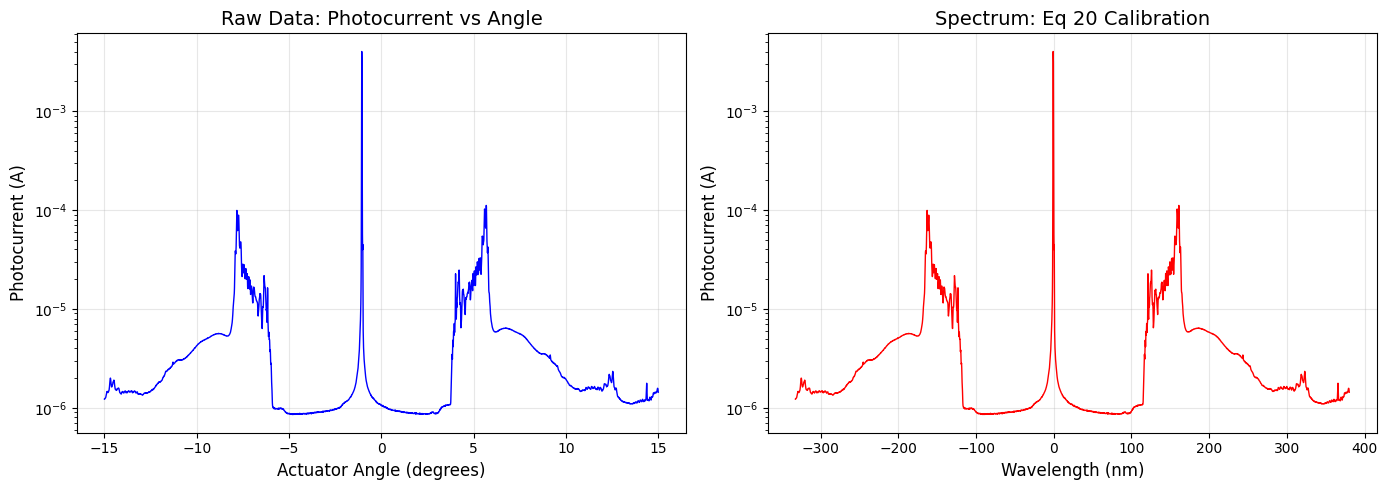

In [ ]:
""" # FULL CALIBRATED SPECTRUM (with gamma and theta0 values found in the following cells)

import matplotlib.pyplot as plt
import numpy as np

def actuator_angle_to_wavelength(theta_deg):
    # Equation 20 of Max's report: m * lambda = 2 * d * cos(phi) * sin(gamma * (theta - theta0))

    d = 835.5           # nm (1 / 1200 lines/mm)
    phi = 35            # degrees (half deviation angle)
    gamma = 1.00694     # NEW actuator scaling factor, Max's : 1.0028
    theta0 = -1.02898   # NEW degrees (angular offset), max's : 1.502
    m = 1               # first diffraction order

    theta_rad = np.radians(theta_deg)
    theta0_rad = np.radians(theta0)
    phi_rad = np.radians(phi)

    C = 2 * d * np.cos(phi_rad)  # ≈ 1365 nm

    wavelength = (C * np.sin(gamma * (theta_rad - theta0_rad))) / m

    return wavelength

data = np.loadtxt(r"C:/Users/leaga/OneDrive - USherbrooke/Internship UoM/VUV Monochromator/2. Deuterium Lamp/Calibration/long_run_20260717_-15_15_0.01.txt",delimiter=',', usecols=(0, 1))

angle = data[:, 0]
photocurrent = data[:, 1]

wavelength_calibrated = actuator_angle_to_wavelength(angle)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1 : Raw Data (angles)
ax1.plot(angle, photocurrent, 'b-', linewidth=1)
ax1.set_xlabel('Actuator Angle (degrees)', fontsize=12)
ax1.set_ylabel('Photocurrent (A)', fontsize=12)
ax1.set_title('Raw Data: Photocurrent vs Angle', fontsize=14)
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3)

# Plot 2 : Calibrated Spectrum
ax2.plot(wavelength_calibrated, photocurrent, 'r-', linewidth=1)
ax2.set_xlabel('Wavelength (nm)', fontsize=12)
ax2.set_ylabel('Photocurrent (A)', fontsize=12)
ax2.set_title('Spectrum: Eq 20 Calibration', fontsize=14)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)

plt.tight_layout()

calibrated_spectrum_data = np.column_stack((wavelength_calibrated, photocurrent))

save_path = r"C:\Users\leaga\OneDrive - USherbrooke\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Calibration\deuterium_lamp_full_detailed_spectrum.png"
plt.savefig(save_path, dpi=300, bbox_inches='tight')

plt.show() """

## Done before me - PLOT OF EXPERIMENTAL DATA VS REFERENCE DATA, NORMALIZED (Not fitted)

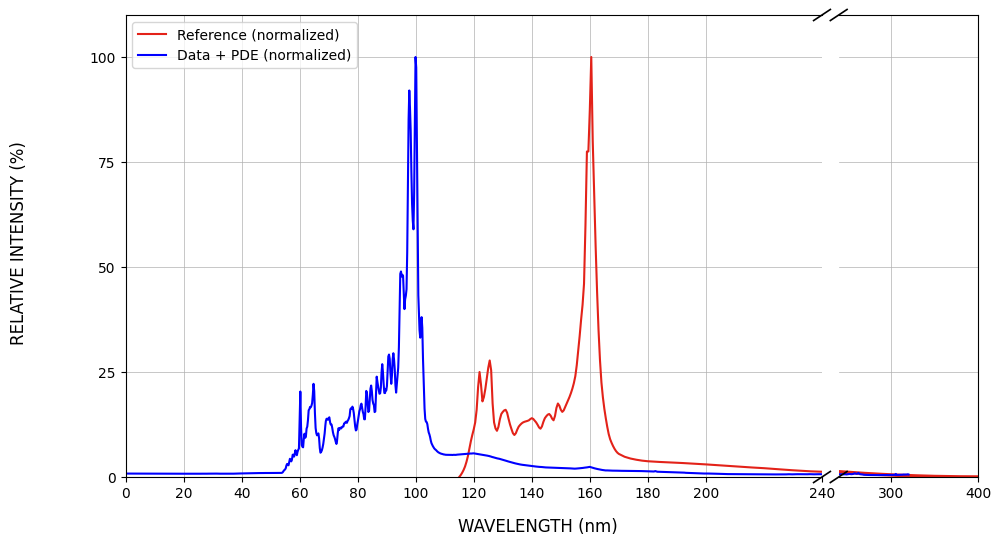

In [ ]:
""" # PLOT OF EXPERIMENTAL DATA VS REFERENCE DATA, NORMALIZED

import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks

# REFERENCE DATA
x_ref = np.array([
    115.0, 115.5, 116.0, 116.5, 117.0, 117.5, 118.0, 118.5, 119.0, 119.5, 120.0, 120.5, 121.0, 121.5, 122.0,
    122.5, 123.0, 123.5, 124.0, 124.5, 125.0, 125.5, 126.0, 126.5, 127.0, 127.5, 128.0, 128.5, 129.0, 129.5,
    130.0, 130.5, 131.0, 131.5, 132.0, 132.5, 133.0, 133.5, 134.0, 134.5, 135.0, 135.5, 136.0, 136.5, 137.0,
    137.5, 138.0, 138.5, 139.0, 139.5, 140.0, 140.5, 141.0, 141.5, 142.0, 142.5, 143.0, 143.5, 144.0, 144.5,
    145.0, 145.5, 146.0, 146.5, 147.0, 147.5, 148.0, 148.5, 149.0, 149.5, 150.0, 150.5, 151.0, 151.5, 152.0,
    152.5, 153.0, 153.5, 154.0, 154.5, 155.0, 155.5, 156.0, 156.5, 157.0, 157.5, 158.0, 158.5, 159.0, 159.5,
    160.0, 160.5, 161.0, 161.5, 162.0, 162.5, 163.0, 163.5, 164.0, 164.5, 165.0, 165.5, 166.0, 166.5, 167.0,
    167.5, 168.0, 168.5, 169.0, 169.5, 170.0,
    172.0, 174.0, 176.0, 178.0, 180.0, 182.0, 184.0, 186.0, 188.0, 190.0, 192.0, 194.0, 196.0, 198.0, 200.0,
    202.0, 204.0, 206.0, 208.0, 210.0, 212.0, 214.0, 216.0, 218.0, 220.0, 222.0, 224.0, 226.0, 228.0, 230.0,
    232.0, 234.0, 236.0, 238.0, 240.0,
    250.0, 260.0, 270.0, 280.0, 290.0, 300.0, 310.0, 320.0, 330.0, 340.0, 350.0, 360.0, 370.0, 380.0, 390.0, 400.0
])
y_ref = np.array([
    0.0, 0.89, 2.0, 3.33, 5.0, 7.24, 10.0, 13.43, 17.0, 20.0, 22.71, 26.0, 32.0, 42.76, 50.0,
    44.0, 36.0, 38.06, 42.0, 47.04, 52.0, 55.5, 50.84, 35.0, 26.0, 23.12, 22.0, 23.84, 27.45, 30.0,
    30.99, 31.72, 32.0, 30.62, 27.68, 25.0, 22.84, 20.86, 20.0, 20.84, 22.57, 24.0, 24.83, 25.51, 26.0,
    26.3, 26.51, 26.72, 27.0, 27.59, 28.0, 27.66, 26.87, 26.0, 24.87, 23.6, 23.0, 24.08, 26.28, 28.0,
    28.94, 29.69, 30.0, 29.22, 27.78, 27.0, 29.07, 32.93, 35.0, 33.96, 32.04, 31.0, 31.71, 33.3, 35.0,
    36.5, 38.12, 40.0, 42.14, 44.7, 48.0, 53.28, 60.0, 67.17, 75.0, 82.03, 92.0, 120.0, 155.0, 155.0,
    175.0, 200.0, 160.0, 135.0, 110.0, 88.22, 70.0, 55.65, 45.0, 37.97, 32.5, 28.0, 23.95, 20.47, 18.0,
    16.27, 14.76, 13.46, 12.39, 11.57, 11.0, 9.63, 8.8, 8.23, 7.79, 7.5, 7.31, 7.17, 7.05, 6.93,
    6.8, 6.65, 6.5, 6.34, 6.17, 6.0, 5.81, 5.61, 5.39, 5.19, 5.0, 4.83, 4.68, 4.52, 4.37,
    4.2, 4.01, 3.8, 3.59, 3.38, 3.2, 3.03, 2.87, 2.71, 2.59, 2.5, 2.2, 1.91, 1.65, 1.4,
    1.18, 0.97, 0.79, 0.62, 0.48, 0.35, 0.24, 0.16, 0.09, 0.04, 0.01, 0.0
])

# PDE DATA
wl_pde = np.array([120, 125, 130, 135, 140, 145, 150, 155, 160, 165, 170, 175, 180, 185, 190, 195, 200])
vals_pde = np.array([11, 12.5, 15.0, 19.0, 22.0, 24, 23.5, 23, 17, 23.5, 23.5, 24.0, 24.0, 24.0, 24.0, 24.0, 24.0])

# RAW EXPERIMENTAL DATA
path = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Calibration\long_run_260717_-15_15_0.01.txt"
data = np.loadtxt(path, delimiter=',', usecols=(0, 1))
angle = data[:, 0]
photocurrent = data[:, 1]

# CONVERSION TO WAVELENGTH
d = 835.5
phi = 35
gamma = 1.0028
theta0 = 1.502
C = 2 * d * np.cos(np.radians(phi))
wavelength_final = C * np.sin(gamma * (np.radians(angle) - np.radians(theta0)))

# PDE CORRECTION
pde_final = np.interp(wavelength_final, wl_pde, vals_pde, left=vals_pde[0], right=vals_pde[-1])
photocurrent_corrected = photocurrent / pde_final

# STANDARDIZATION (100 base, proportional to the 2nd experimental peak)
peaks, _ = find_peaks(photocurrent_corrected, distance=20)
sorted_peaks = sorted(peaks, key=lambda idx: photocurrent_corrected[idx], reverse=True)
val_2nd_peak_exp = photocurrent_corrected[sorted_peaks[1]]

scale_factor = 100.0 / val_2nd_peak_exp
photocurrent_normalise = photocurrent_corrected * scale_factor

y_ref_normalise = y_ref * (100.0 / np.max(y_ref))

# PLOTTING
fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(11, 6), gridspec_kw={'width_ratios': [5, 1]})
fig.subplots_adjust(wspace=0.04)

ax1.plot(x_ref, y_ref_normalise, color='#e32219', linewidth=1.5, label='Reference (normalized)')
ax1.plot(wavelength_final, photocurrent_normalise, color='blue', linestyle='-', linewidth=1.5, label='Data + PDE (normalized)')

ax2.plot(x_ref, y_ref_normalise, color='#e32219', linewidth=2.5)
ax2.plot(wavelength_final, photocurrent_normalise, color='blue', linestyle='-', linewidth=1.5)

ax1.set_xlim(0, 240)
ax2.set_xlim(240, 400)
ax1.set_ylim(0.1, 110)

ax1.set_xticks([0, 20, 40, 60, 80, 100, 120, 140, 160, 180, 200, 240])
ax2.set_xticks([300, 400])
ax1.set_yticks([0, 25, 50, 75, 100])

ax1.grid(True, color='#b0b0b0', linestyle='-', linewidth=0.5)
ax2.grid(True, color='#b0b0b0', linestyle='-', linewidth=0.5)

ax1.spines['right'].set_visible(False)
ax2.spines['left'].set_visible(False)
ax2.tick_params(left=False, labelleft=False)

d_tick = .012
kwargs = dict(transform=ax1.transAxes, color='black', clip_on=False, linewidth=1.2)
ax1.plot((1 - d_tick, 1 + d_tick), (-d_tick, +d_tick), **kwargs)
ax1.plot((1 - d_tick, 1 + d_tick), (1 - d_tick, 1 + d_tick), **kwargs)
kwargs.update(transform=ax2.transAxes)
ax2.plot((-d_tick * 5, +d_tick * 5), (-d_tick, +d_tick), **kwargs)
ax2.plot((-d_tick * 5, +d_tick * 5), (1 - d_tick, 1 + d_tick), **kwargs)

ax1.legend(loc='upper left')
fig.text(0.5, 0.02, 'WAVELENGTH (nm)', ha='center', fontsize=12)
fig.text(0.02, 0.5, 'RELATIVE INTENSITY (%)', va='center', rotation='vertical', fontsize=12)

plt.show() """

## CALIBRATION A - fixing gamma (commented bit is the fixing gamma code)

C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\Spectrum_calibration_data_(30-10-2026)_1\fine_cali_first_pos_spectrum.txt
file read successfully
Angle array: 0      -1.0
1      -0.9
2      -0.8
3      -0.7
4      -0.6
       ... 
106     9.6
107     9.7
108     9.8
109     9.9
110    10.0
Name: angle_deg, Length: 111, dtype: float64


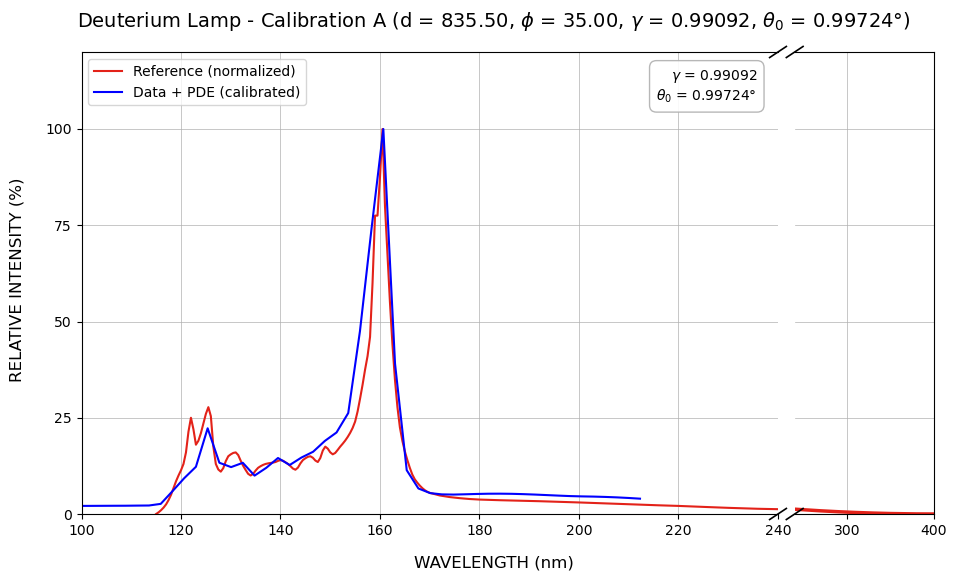

In [ ]:
# CALIBRATION A - fixing gamma (commented bit is the fixing gamma code)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from pathlib import Path

# REFERENCE DATA
x_ref = np.array([
    115.0, 115.5, 116.0, 116.5, 117.0, 117.5, 118.0, 118.5, 119.0, 119.5, 120.0, 120.5, 121.0, 121.5, 122.0,
    122.5, 123.0, 123.5, 124.0, 124.5, 125.0, 125.5, 126.0, 126.5, 127.0, 127.5, 128.0, 128.5, 129.0, 129.5,
    130.0, 130.5, 131.0, 131.5, 132.0, 132.5, 133.0, 133.5, 134.0, 134.5, 135.0, 135.5, 136.0, 136.5, 137.0,
    137.5, 138.0, 138.5, 139.0, 139.5, 140.0, 140.5, 141.0, 141.5, 142.0, 142.5, 143.0, 143.5, 144.0, 144.5,
    145.0, 145.5, 146.0, 146.5, 147.0, 147.5, 148.0, 148.5, 149.0, 149.5, 150.0, 150.5, 151.0, 151.5, 152.0,
    152.5, 153.0, 153.5, 154.0, 154.5, 155.0, 155.5, 156.0, 156.5, 157.0, 157.5, 158.0, 158.5, 159.0, 159.5,
    160.0, 160.5, 161.0, 161.5, 162.0, 162.5, 163.0, 163.5, 164.0, 164.5, 165.0, 165.5, 166.0, 166.5, 167.0,
    167.5, 168.0, 168.5, 169.0, 169.5, 170.0,
    172.0, 174.0, 176.0, 178.0, 180.0, 182.0, 184.0, 186.0, 188.0, 190.0, 192.0, 194.0, 196.0, 198.0, 200.0,
    202.0, 204.0, 206.0, 208.0, 210.0, 212.0, 214.0, 216.0, 218.0, 220.0, 222.0, 224.0, 226.0, 228.0, 230.0,
    232.0, 234.0, 236.0, 238.0, 240.0,
    250.0, 260.0, 270.0, 280.0, 290.0, 300.0, 310.0, 320.0, 330.0, 340.0, 350.0, 360.0, 370.0, 380.0, 390.0, 400.0
])
y_ref = np.array([
    0.0, 0.89, 2.0, 3.33, 5.0, 7.24, 10.0, 13.43, 17.0, 20.0, 22.71, 26.0, 32.0, 42.76, 50.0,
    44.0, 36.0, 38.06, 42.0, 47.04, 52.0, 55.5, 50.84, 35.0, 26.0, 23.12, 22.0, 23.84, 27.45, 30.0,
    30.99, 31.72, 32.0, 30.62, 27.68, 25.0, 22.84, 20.86, 20.0, 20.84, 22.57, 24.0, 24.83, 25.51, 26.0,
    26.3, 26.51, 26.72, 27.0, 27.59, 28.0, 27.66, 26.87, 26.0, 24.87, 23.6, 23.0, 24.08, 26.28, 28.0,
    28.94, 29.69, 30.0, 29.22, 27.78, 27.0, 29.07, 32.93, 35.0, 33.96, 32.04, 31.0, 31.71, 33.3, 35.0,
    36.5, 38.12, 40.0, 42.14, 44.7, 48.0, 53.28, 60.0, 67.17, 75.0, 82.03, 92.0, 120.0, 155.0, 155.0,
    175.0, 200.0, 160.0, 135.0, 110.0, 88.22, 70.0, 55.65, 45.0, 37.97, 32.5, 28.0, 23.95, 20.47, 18.0,
    16.27, 14.76, 13.46, 12.39, 11.57, 11.0, 9.63, 8.8, 8.23, 7.79, 7.5, 7.31, 7.17, 7.05, 6.93,
    6.8, 6.65, 6.5, 6.34, 6.17, 6.0, 5.81, 5.61, 5.39, 5.19, 5.0, 4.83, 4.68, 4.52, 4.37,
    4.2, 4.01, 3.8, 3.59, 3.38, 3.2, 3.03, 2.87, 2.71, 2.59, 2.5, 2.2, 1.91, 1.65, 1.4,
    1.18, 0.97, 0.79, 0.62, 0.48, 0.35, 0.24, 0.16, 0.09, 0.04, 0.01, 0.0
])

y_ref_norm = y_ref * (100.0 / np.max(y_ref)) # Normalization of reference

# PDE DATA (PDE - Photon Detection Efficiency - from Max's report, Fig. 3.2)
wl_pde = np.array([120, 125, 130, 135, 140, 145, 150, 155, 160, 165, 170, 175, 180, 185, 190, 195, 200])
vals_pde = np.array([11, 12.5, 15.0, 19.0, 22.0, 24, 23.5, 23, 17, 23.5, 23.5, 24.0, 24.0, 24.0, 24.0, 24.0, 24.0])


# Counter is used to determine if the total_sum_photocurrent variable has been added to yet
counter = 0
# total_sum_photocurrent is used to calculate the average of all the files processed
total_sum_photocurrent = []
total_sum_variance = []
# num_files is used to determine how many files were processed, so that the average can be calculated
num_files = 0

# Define the directory path where the spectrum data files are located. Use pathlib to handle file paths.

path = Path(r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\Spectrum_calibration_data_(30-10-2026)_1")  # Replace with the actual path to your data files
path_prefix = path
path_suffix = ".txt"

#fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

try:
    # Iterates over all .txt files in the specified directory and processes them
    for target in path.glob("*.txt"):
        
        print(str(target))
        try:

            df = pd.read_csv(str(target))
            print("file read successfully")

        except:
            print(f"File {target} failed to load.")  

        try:
            #print(f"File {target} failed to load.")             
            trimmed_path_file = target.stem
            #print(f"Trimmed name: {trimmed_path_file}")

            # Assume file format as follows: angle_deg, epos, current_mean_A, current_std_A, n_samples
            angle = df["angle_deg"]
            print(f"Angle array: {angle}")
            photocurrent = df["current_mean_A"]
            photocurrent_std = df["current_std_A"] / np.sqrt(df["n_samples"]) # errors are negligible

            # wavelength_calibrated = actuator_angle_to_wavelength(angle)

            if counter == 0:
                total_sum_photocurrent = photocurrent
                total_sum_variance = photocurrent_std ** 2
                temp_angle = angle

                counter += 1
            else:
                total_sum_photocurrent += photocurrent
                total_sum_variance += photocurrent_std ** 2 # combinging the variances of the individual files to get the total variance to then get the std later on
                try:
                    if not np.array_equal(temp_angle, angle):
                        print(f"Warning: Angle arrays do not match for file {target}.") # I assume the data used will be taken over the same angle range, so if they don't match, it will be a problem. This is just a warning for now.
                except Exception as e:
                    print(f"Error comparing angle arrays for file {target}: {e}")
        except:
            print(f"File {target} failed to be processed.")        

        num_files += 1

except:
    print(f"Error occurred while trying to glob files.")

# Plot the average spectrum of all the files processed
if num_files == 0:
    raise ValueError(f"No .txt files found in directory: {path}")


photocurrent_avg = total_sum_photocurrent / num_files
photocurrent_std = np.sqrt((total_sum_variance) / num_files)

new_df = pd.DataFrame()

new_df = new_df.assign(
     angle_deg=angle,
     photocurrent_avg=photocurrent_avg,
     photocurrent_std=photocurrent_std,
 )

angle = new_df["angle_deg"]
photocurrent_avg = new_df["photocurrent_avg"]
photocurrent_std = new_df["photocurrent_std"]

# Very rough, need to rewrite so if there are multiple files, it can average them all together. For now, just use one file...
#path = r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\Spectrum_calibration_data_(30-10-2026)\fine_cali_first_pos_spectrum.txt"
#df = pd.read_csv(path)
#angle1 = df["angle_deg"] # angle1 used so it works with the rest of the code
#photocurrent_avg = df["current_mean_A"]

# PHYSICAL CONVERSION FUNCTION - EQ 20 OF MAX'S REPORT
def get_wavelength(theta_deg, gamma, theta0):
    global d, phi
    d = 835.5
    phi = 35
    C = 2 * d * np.cos(np.radians(phi))
    return C * np.sin(gamma * (np.radians(theta_deg) - np.radians(theta0)))

# OBJECTIVE FUNCTION FOR X-AXIS ALIGNMENT
def objective_function(params):
    gamma, theta0 = params
    w_calib = get_wavelength(angle, gamma, theta0)

    # Apply dynamic PDE correction
    pde_interp = np.interp(w_calib, wl_pde, vals_pde, left=vals_pde[0], right=vals_pde[-1])
    y_corrected = photocurrent_avg / pde_interp

    # Focus optimization strictly on the primary peak features region
    mask_fit = (w_calib >= 115) & (w_calib <= 200)
    if np.sum(mask_fit) < 10:
        return 1e10

    w_fit = w_calib[mask_fit]
    y_fit = y_corrected[mask_fit]

    # Map reference onto current data wavelength array
    y_ref_lookup = np.interp(w_fit, x_ref, y_ref_norm)
    y_fit_scaled = y_fit * (100.0 / np.max(y_fit))

    # Minimize residual sum of squares
    return np.sum((y_fit_scaled - y_ref_lookup) ** 2)

# OPTIMIZATION RUN WITH FIXED PHYSICAL ALIGNMENT OVERRIDE
init_guess = [1.00694, 1.0] # gamma and theta0
bounds = [(0.9, 1.1), (-2.0, 2.0)] # angles

result = minimize(objective_function, init_guess, bounds=bounds, method='L-BFGS-B')
gamma_opt, theta0_opt = result.x

# FINAL VALUE CORRECTION & TARGETED INTENSITY NORMALIZATION
wavelength_final = get_wavelength(angle, gamma_opt, theta0_opt)
pde_final = np.interp(wavelength_final, wl_pde, vals_pde, left=vals_pde[0], right=vals_pde[-1])
photocurrent_corrected = photocurrent_avg / pde_final

mask_peaks = (wavelength_final >= 115) & (wavelength_final <= 200)
val_doublet_max = np.max(photocurrent_corrected[mask_peaks])

photocurrent_normalise = photocurrent_corrected * (100.0 / val_doublet_max)
y_ref_normalise = y_ref * (100.0 / np.max(y_ref))

""" GAMMA = 1.00 # fixing the gamma value to 1.00 as spoken about

# Fixed-mask in angle space, only fixing theta0
w_ref_cal = get_wavelength(angle, 1.0, 0.0) # converting the angle to the wavelength using the initial guess
idx = np.where((w_ref_cal >= 110) & (w_ref_cal <= 170))[0]
ang_fit = angle[idx]
pc_fit = photocurrent_avg[idx]

def objective_theta(theta0):
    w = get_wavelength(ang_fit, GAMMA, theta0)
    pde = np.interp(w, wl_pde, vals_pde, left=vals_pde[0], right=vals_pde[-1])
    y = pc_fit / pde
    r = np.interp(w, x_ref, y_ref)
    a = np.sum(y * r) / np.sum(y ** 2)       # analytic amplitude
    return np.mean((a * y - r) ** 2)         # mean, fixed points

# Scan over theta0 to find a good starting point
# Note: I restricted the range to -0.5 to 0.5 degrees as we assume we are wanting theta around 0 degrees here
thetas = np.linspace(-0.5, 0.5, 1501)
costs = np.array([objective_theta(t) for t in thetas])
t_best = thetas[np.argmin(costs)]
print("Best theta0 from scan:", t_best)

# Plots the scan
plt.plot(thetas, costs); plt.axvline(t_best, color='r')
plt.xlabel('theta0 (deg)'); plt.ylabel('cost'); plt.show()

# Perform another optimisation around the best theta0 we came up with
from scipy.optimize import minimize_scalar
res = minimize_scalar(objective_theta, bounds=(t_best - 0.02, t_best + 0.02),
                      method='bounded', options={'xatol': 1e-7})
theta0_opt = res.x
gamma_opt = GAMMA

# FINAL VALUE CORRECTION & TARGETED INTENSITY NORMALIZATION
wavelength_final = get_wavelength(angle, gamma_opt, theta0_opt)
pde_final = np.interp(wavelength_final, wl_pde, vals_pde, left=vals_pde[0], right=vals_pde[-1])
photocurrent_corrected = photocurrent_avg / pde_final

mask_peaks = (wavelength_final >= 110) & (wavelength_final <= 170)
val_doublet_max = np.max(photocurrent_corrected[mask_peaks])

photocurrent_normalise = photocurrent_corrected * (100.0 / val_doublet_max)
y_ref_normalise = y_ref * (100.0 / np.max(y_ref)) """

#hhh

# PLOTTING
fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(11, 6), gridspec_kw={'width_ratios': [5, 1]})
fig.subplots_adjust(wspace=0.04)

ax1.plot(x_ref, y_ref_normalise, color='#e32219', linewidth=1.5, label='Reference (normalized)')
ax1.plot(wavelength_final, photocurrent_normalise, color='blue', linestyle='-', linewidth=1.5, label='Data + PDE (calibrated)')

ax2.plot(x_ref, y_ref_normalise, color='#e32219', linewidth=2.5)
ax2.plot(wavelength_final, photocurrent_normalise, color='blue', linestyle='-', linewidth=1.5)

ax1.set_xlim(100, 240)
ax2.set_xlim(240, 400)
ax1.set_ylim(0.1, 120)

ax1.set_xticks([100, 120, 140, 160, 180, 200, 220, 240])
ax2.set_xticks([300, 400])
ax1.set_yticks([0, 25, 50, 75, 100])

ax1.grid(True, color='#b0b0b0', linestyle='-', linewidth=0.5)
ax2.grid(True, color='#b0b0b0', linestyle='-', linewidth=0.5)

ax1.spines['right'].set_visible(False)
ax2.spines['left'].set_visible(False)
ax2.tick_params(left=False, labelleft=False)
#ax1.set_title(f"Deuterium Lamp - Calibration A (d = {d:.2f}, $\\phi$ = {phi:.2f}, $\\gamma$ = {gamma_opt:.5f}, $\\theta_0$ = {theta0_opt:.5f}°)", fontsize=14, loc='center', pad=10)
fig.suptitle(f"Deuterium Lamp - Calibration A (d = {d:.2f}, $\\phi$ = {phi:.2f}, $\\gamma$ = {gamma_opt:.5f}, $\\theta_0$ = {theta0_opt:.5f}°)", fontsize=14, y=0.95)


d_tick = .012
kwargs = dict(transform=ax1.transAxes, color='black', clip_on=False, linewidth=1.2)
ax1.plot((1 - d_tick, 1 + d_tick), (-d_tick, +d_tick), **kwargs)
ax1.plot((1 - d_tick, 1 + d_tick), (1 - d_tick, 1 + d_tick), **kwargs)
kwargs.update(transform=ax2.transAxes)
ax2.plot((-d_tick * 5, +d_tick * 5), (-d_tick, +d_tick), **kwargs)
ax2.plot((-d_tick * 5, +d_tick * 5), (1 - d_tick, 1 + d_tick), **kwargs)

info_text = f"$\\gamma$ = {gamma_opt:.5f}\n$\\theta_0$ = {theta0_opt:.5f}°"
ax1.text(0.97, 0.965, info_text, transform=ax1.transAxes, fontsize=10,
         verticalalignment='top', horizontalalignment='right',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#b0b0b0', alpha=0.9))

ax1.legend(loc='upper left')
fig.text(0.5, 0.02, 'WAVELENGTH (nm)', ha='center', fontsize=12)
fig.text(0.06, 0.5, 'RELATIVE INTENSITY (%)', va='center', rotation='vertical', fontsize=12)

#save_path = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Calibration\data_pde_corrected_vs_reference_calibrationA.png"
#plt.savefig('Figures\\fine_cali_first_pos_spectrum_vs_reference_calibrationA_(30-10-2026).png', dpi=300, bbox_inches='tight')

plt.show()

## Done before me - CALIBRATION B

In [ ]:
""" 
# CALIBRATION B

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize
from scipy.signal import find_peaks

# REFERENCE DATA
x_ref = np.array([
    115.0, 115.5, 116.0, 116.5, 117.0, 117.5, 118.0, 118.5, 119.0, 119.5, 120.0, 120.5, 121.0, 121.5, 122.0,
    122.5, 123.0, 123.5, 124.0, 124.5, 125.0, 125.5, 126.0, 126.5, 127.0, 127.5, 128.0, 128.5, 129.0, 129.5,
    130.0, 130.5, 131.0, 131.5, 132.0, 132.5, 133.0, 133.5, 134.0, 134.5, 135.0, 135.5, 136.0, 136.5, 137.0,
    137.5, 138.0, 138.5, 139.0, 139.5, 140.0, 140.5, 141.0, 141.5, 142.0, 142.5, 143.0, 143.5, 144.0, 144.5,
    145.0, 145.5, 146.0, 146.5, 147.0, 147.5, 148.0, 148.5, 149.0, 149.5, 150.0, 150.5, 151.0, 151.5, 152.0,
    152.5, 153.0, 153.5, 154.0, 154.5, 155.0, 155.5, 156.0, 156.5, 157.0, 157.5, 158.0, 158.5, 159.0, 159.5,
    160.0, 160.5, 161.0, 161.5, 162.0, 162.5, 163.0, 163.5, 164.0, 164.5, 165.0, 165.5, 166.0, 166.5, 167.0,
    167.5, 168.0, 168.5, 169.0, 169.5, 170.0,
    172.0, 174.0, 176.0, 178.0, 180.0, 182.0, 184.0, 186.0, 188.0, 190.0, 192.0, 194.0, 196.0, 198.0, 200.0,
    202.0, 204.0, 206.0, 208.0, 210.0, 212.0, 214.0, 216.0, 218.0, 220.0, 222.0, 224.0, 226.0, 228.0, 230.0,
    232.0, 234.0, 236.0, 238.0, 240.0,
    250.0, 260.0, 270.0, 280.0, 290.0, 300.0, 310.0, 320.0, 330.0, 340.0, 350.0, 360.0, 370.0, 380.0, 390.0, 400.0
])
y_ref = np.array([
    0.0, 0.89, 2.0, 3.33, 5.0, 7.24, 10.0, 13.43, 17.0, 20.0, 22.71, 26.0, 32.0, 42.76, 50.0,
    44.0, 36.0, 38.06, 42.0, 47.04, 52.0, 55.5, 50.84, 35.0, 26.0, 23.12, 22.0, 23.84, 27.45, 30.0,
    30.99, 31.72, 32.0, 30.62, 27.68, 25.0, 22.84, 20.86, 20.0, 20.84, 22.57, 24.0, 24.83, 25.51, 26.0,
    26.3, 26.51, 26.72, 27.0, 27.59, 28.0, 27.66, 26.87, 26.0, 24.87, 23.6, 23.0, 24.08, 26.28, 28.0,
    28.94, 29.69, 30.0, 29.22, 27.78, 27.0, 29.07, 32.93, 35.0, 33.96, 32.04, 31.0, 31.71, 33.3, 35.0,
    36.5, 38.12, 40.0, 42.14, 44.7, 48.0, 53.28, 60.0, 67.17, 75.0, 82.03, 92.0, 120.0, 155.0, 155.0,
    175.0, 200.0, 160.0, 135.0, 110.0, 88.22, 70.0, 55.65, 45.0, 37.97, 32.5, 28.0, 23.95, 20.47, 18.0,
    16.27, 14.76, 13.46, 12.39, 11.57, 11.0, 9.63, 8.8, 8.23, 7.79, 7.5, 7.31, 7.17, 7.05, 6.93,
    6.8, 6.65, 6.5, 6.34, 6.17, 6.0, 5.81, 5.61, 5.39, 5.19, 5.0, 4.83, 4.68, 4.52, 4.37,
    4.2, 4.01, 3.8, 3.59, 3.38, 3.2, 3.03, 2.87, 2.71, 2.59, 2.5, 2.2, 1.91, 1.65, 1.4,
    1.18, 0.97, 0.79, 0.62, 0.48, 0.35, 0.24, 0.16, 0.09, 0.04, 0.01, 0.0
])
y_ref_norm = y_ref * (100.0 / np.max(y_ref))

# PDE DATA
wl_pde = np.array([120, 125, 130, 135, 140, 145, 150, 155, 160, 165, 170, 175, 180, 185, 190, 195, 200])
vals_pde = np.array([11, 12.5, 15.0, 19.0, 22.0, 24, 23.5, 23, 17, 23.5, 23.5, 24.0, 24.0, 24.0, 24.0, 24.0, 24.0])

# RAW EXPERIMENTAL DATA
path = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Calibration\long_run_260717_-15_15_0.01.txt"
data = np.loadtxt(path, delimiter=',', usecols=(0, 1))
angle = data[:, 0]
photocurrent = data[:, 1]

# PHYSICAL CONVERSION FUNCTION
def get_wavelength(theta_deg, gamma, theta0):
    d = 835.5
    phi = 35
    C = 2 * d * np.cos(np.radians(phi))
    return C * np.sin(gamma * (np.radians(theta_deg) - np.radians(theta0)))

# OBJECTIVE FUNCTION FOR X-AXIS ALIGNMENT
def objective_function(params):
    gamma, theta0 = params
    w_calib = get_wavelength(angle, gamma, theta0)

    pde_interp = np.interp(w_calib, wl_pde, vals_pde, left=vals_pde[0], right=vals_pde[-1])
    y_corrected = photocurrent / pde_interp

    # Target strictly the core of the 160 nm peak
    mask_fit = (w_calib >= 155) & (w_calib <= 165)
    if np.sum(mask_fit) < 10:
        return 1e10

    w_fit = w_calib[mask_fit]
    y_fit = y_corrected[mask_fit]

    y_ref_lookup = np.interp(w_fit, x_ref, y_ref_norm)
    y_fit_scaled = y_fit * (100.0 / np.max(y_fit))

    return np.sum((y_fit_scaled - y_ref_lookup) ** 2)

# OPTIMIZATION RUN WITH FIXED PHYSICAL ALIGNMENT OVERRIDE
init_guess = [1.00694, -1.03520]
bounds = [(0.98, 1.05), (-2.0, -0.5)]

result = minimize(objective_function, init_guess, bounds=bounds, method='L-BFGS-B')
gamma_opt, theta0_raw = result.x

# Manual override according to visual spectral alignment:
theta0_opt = theta0_raw + 0.025

# FINAL VALUE CORRECTION & TARGETED INTENSITY NORMALIZATION
wavelength_final = get_wavelength(angle, gamma_opt, theta0_opt)
pde_final = np.interp(wavelength_final, wl_pde, vals_pde, left=vals_pde[0], right=vals_pde[-1])
photocurrent_corrected = photocurrent / pde_final

mask_peaks = (wavelength_final >= 115) & (wavelength_final <= 200)
peaks_in_zone, _ = find_peaks(photocurrent_corrected[mask_peaks], distance=10)
peaks_global_indices = np.where(mask_peaks)[0][peaks_in_zone]

highest_peak_idx = max(peaks_global_indices, key=lambda idx: photocurrent_corrected[idx])
val_doublet_max = photocurrent_corrected[highest_peak_idx]

scale_factor = 100.0 / val_doublet_max
photocurrent_normalise = photocurrent_corrected * scale_factor
y_ref_normalise = y_ref * (100.0 / np.max(y_ref))

# PLOTTING
fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(11, 6), gridspec_kw={'width_ratios': [5, 1]})
fig.subplots_adjust(wspace=0.04)

ax1.plot(x_ref, y_ref_normalise, color='#e32219', linewidth=1.5, label='Reference (normalized)')
ax1.plot(wavelength_final, photocurrent_normalise, color='blue', linestyle='-', linewidth=1.5, label='Data + PDE (calibrated)')

ax2.plot(x_ref, y_ref_normalise, color='#e32219', linewidth=2.5)
ax2.plot(wavelength_final, photocurrent_normalise, color='blue', linestyle='-', linewidth=1.5)

ax1.set_xlim(100, 240)
ax2.set_xlim(240, 400)
ax1.set_ylim(0.1, 120)

ax1.set_xticks([100, 120, 140, 160, 180, 200, 220, 240])
ax2.set_xticks([300, 400])
ax1.set_yticks([0, 25, 50, 75, 100])

ax1.grid(True, color='#b0b0b0', linestyle='-', linewidth=0.5)
ax2.grid(True, color='#b0b0b0', linestyle='-', linewidth=0.5)

ax1.spines['right'].set_visible(False)
ax2.spines['left'].set_visible(False)
ax2.tick_params(left=False, labelleft=False)
ax1.set_title('Deuterium Lamp - Calibration B', fontsize=14, loc='center', pad=10)

d_tick = .012
kwargs = dict(transform=ax1.transAxes, color='black', clip_on=False, linewidth=1.2)
ax1.plot((1 - d_tick, 1 + d_tick), (-d_tick, +d_tick), **kwargs)
ax1.plot((1 - d_tick, 1 + d_tick), (1 - d_tick, 1 + d_tick), **kwargs)
kwargs.update(transform=ax2.transAxes)
ax2.plot((-d_tick * 5, +d_tick * 5), (-d_tick, +d_tick), **kwargs)
ax2.plot((-d_tick * 5, +d_tick * 5), (1 - d_tick, 1 + d_tick), **kwargs)

info_text = f"$\\gamma$ = {gamma_opt:.5f}\n$\\theta_0$ = {theta0_opt:.5f}°"
ax1.text(0.97, 0.965, info_text, transform=ax1.transAxes, fontsize=10,
         verticalalignment='top', horizontalalignment='right',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#b0b0b0', alpha=0.9))

ax1.legend(loc='upper left')

fig.text(0.5, 0.02, 'WAVELENGTH (nm)', ha='center', fontsize=12)
fig.text(0.06, 0.5, 'RELATIVE INTENSITY (%)', va='center', rotation='vertical', fontsize=12)

save_path = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Calibration\data_pde_corrected_vs_reference_calibrationB.png"
plt.savefig(save_path, dpi=300, bbox_inches='tight')

plt.show() 
"""

SyntaxError: (unicode error) 'unicodeescape' codec can't decode bytes in position 2757-2758: truncated \UXXXXXXXX escape (619096571.py, line 1)

## Done before me - Compare CALIBRATION A and Calibration B

In [ ]:
""" # CALIBRATION A AND B COMPARISON

import numpy as np

# Constant optical coefficients from the setup
d, phi = 835.5, 35
C_OPTICAL = 2 * d * np.cos(np.radians(phi))

# SET PARAMETERS FOR BOTH CALIBRATIONS
# Calibration A: Global fit results
gamma_A = 1.00694
theta0_A = -1.02898

# Calibration B: Targeted peak fit + manual override results
gamma_B = 1.00408
theta0_B = -1.02898 # raw + manual offset (0.025)

# DEFINE DIRECT AND INVERSE TRANSFORMATION FUNCTIONS
def get_wavelength(theta_deg, gamma, theta0):
    return C_OPTICAL * np.sin(gamma * (np.radians(theta_deg) - np.radians(theta0)))

def get_angle_inverse(wavelength_nm, gamma, theta0):
    alpha = np.arcsin(wavelength_nm / C_OPTICAL)
    theta_rad = (alpha / gamma) + np.radians(theta0)
    return np.degrees(theta_rad)

# CHOSEN TARGET WAVELENGTHS FOR COMPARISON
target_wavelengths = [128.0, 178.0]

print("CALIBRATION COMPARISON")
for wl_start in target_wavelengths:
    # Step A: Find the mechanical angle corresponding to wl_start using Calibration A
    angle_calc = get_angle_inverse(wl_start, gamma_A, theta0_A)

    # Step B: Pass this calculated angle into Calibration B to see the new wavelength
    wl_end = get_wavelength(angle_calc, gamma_B, theta0_B)

    # Step C: Calculate the delta shift
    delta_wl = wl_end - wl_start

    # Display the results
    print(f"\nTarget Wavelength: {wl_start} nm")
    print(f" -> Equivalent Angle (Calib A): {angle_calc:.5f}°")
    print(f" -> Resulting Wavelength (Calib B): {wl_end:.3f} nm")
    print(f" -> Shift (Delta Lambda): {delta_wl:.3f} nm") """

CALIBRATION COMPARISON

Target Wavelength: 128.0 nm
 -> Equivalent Angle (Calib A): 4.29974°
 -> Resulting Wavelength (Calib B): 127.638 nm
 -> Shift (Delta Lambda): -0.362 nm

Target Wavelength: 178.0 nm
 -> Equivalent Angle (Calib A): 6.39146°
 -> Resulting Wavelength (Calib B): 177.497 nm
 -> Shift (Delta Lambda): -0.503 nm


## Done before me - 1ST STABILITY TEST - FEW MEASUREMENRS SCANNING A SELECTED RANGE OF ANGLES OVER A DAY - 2026/07/20

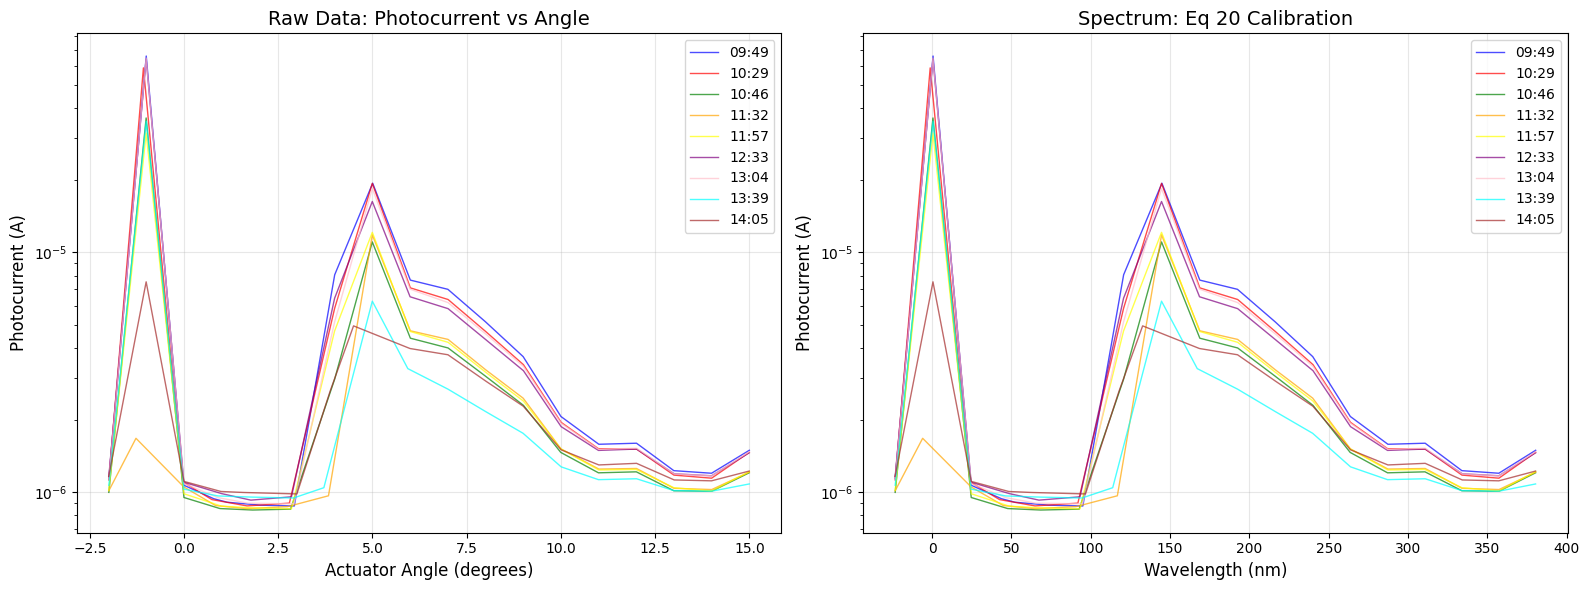

In [ ]:
""" # 1ST STABILITY TEST - FEW MEASUREMENRS SCANNING A SELECTED RANGE OF ANGLES OVER A DAY - 2026/07/20

import matplotlib.pyplot as plt
import numpy as np
import os

def actuator_angle_to_wavelength(theta_deg):
    # Equation 20 of Max's report: m * lambda = 2 * d * cos(phi) * sin(gamma * (theta - theta0))

    d = 835.5          # nm (1 / 1200 lines/mm)
    phi = 35           # degrees (half deviation angle)
    gamma = 1.00694    # actuator scaling factor
    theta0 = -1.02898  # degrees (angular offset)
    m = 1              # first diffraction order

    theta_rad = np.radians(theta_deg)
    theta0_rad = np.radians(theta0)
    phi_rad = np.radians(phi)

    C = 2 * d * np.cos(phi_rad)  # ≈ 1365 nm
    wavelength = (C * np.sin(gamma * (theta_rad - theta0_rad))) / m

    return wavelength

# EXPERIMENTAL DATA
base_path = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Stability"

file_configs = [
    ("stability_20260720_no1_-2_15_1.txt", "09:49", 'blue'),
    ("stability_20260720_no2_-2_15_1.txt", "10:29", 'red'),
    ("stability_20260720_no3_-2_15_1.txt", "10:46", 'green'),
    ("stability_20260720_no4_-2_15_1.txt", "11:32", 'orange'),
    ("stability_20260720_no5_-2_15_1.txt", "11:57", 'yellow'),
    ("stability_20260720_no6_-2_15_1.txt", "12:33", 'purple'),
    ("stability_20260720_no7_-2_15_1.txt", "13:04", 'pink'),
    ("stability_20260720_no8_-2_15_1.txt", "13:39", 'cyan'),
    ("stability_20260720_no9_-2_15_1.txt", "14:05", 'brown')
]

# PLOTTING
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

calibrated_data_list = []

for filename, label, color in file_configs:
    filepath = os.path.join(base_path, filename)

    try:
        data = np.loadtxt(filepath, delimiter=',', usecols=(0, 1))
        angle = data[:, 0]
        photocurrent = data[:, 1]

        wavelength_calibrated = actuator_angle_to_wavelength(angle)

        calibrated_data_list.append((wavelength_calibrated, photocurrent, label))

        # Plot 1: Raw Data (angles) - stacked
        ax1.plot(angle, photocurrent, color=color, linewidth=1, label=label, alpha=0.7)

        # Plot 2: Calibrated Spectrum - stacked
        ax2.plot(wavelength_calibrated, photocurrent, color=color, linewidth=1, label=label, alpha=0.7)

    except FileNotFoundError:
        print(f"File not found: {filename}")
    except Exception as e:
        print(f"Error loading {filename}: {e}")

# Plot 1 config
ax1.set_xlabel('Actuator Angle (degrees)', fontsize=12)
ax1.set_ylabel('Photocurrent (A)', fontsize=12)
ax1.set_title('Raw Data: Photocurrent vs Angle', fontsize=14)
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='best', fontsize=10)

# Plot 2 config
ax2.set_xlabel('Wavelength (nm)', fontsize=12)
ax2.set_ylabel('Photocurrent (A)', fontsize=12)
ax2.set_title('Spectrum: Eq 20 Calibration', fontsize=14)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)
ax2.legend(loc='best', fontsize=10)

plt.tight_layout()

save_path = os.path.join(base_path, "stability_overlay_comparison_1-9.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')

plt.show() """

## Done before me - PLOT TO VISUALISE THE VARIATION IN INTENSITY OVER TIME AT A SELECTED ANGLE

09:49: 0.0 min, photocurrent=7.0091e-06 A
10:29: 40.0 min, photocurrent=6.3567e-06 A
10:46: 57.0 min, photocurrent=3.9923e-06 A
11:32: 103.0 min, photocurrent=4.3335e-06 A
11:57: 128.0 min, photocurrent=4.2153e-06 A
12:33: 164.0 min, photocurrent=5.8224e-06 A
13:04: 195.0 min, photocurrent=6.1707e-06 A
13:39: 230.0 min, photocurrent=2.6875e-06 A
14:05: 256.0 min, photocurrent=3.7397e-06 A


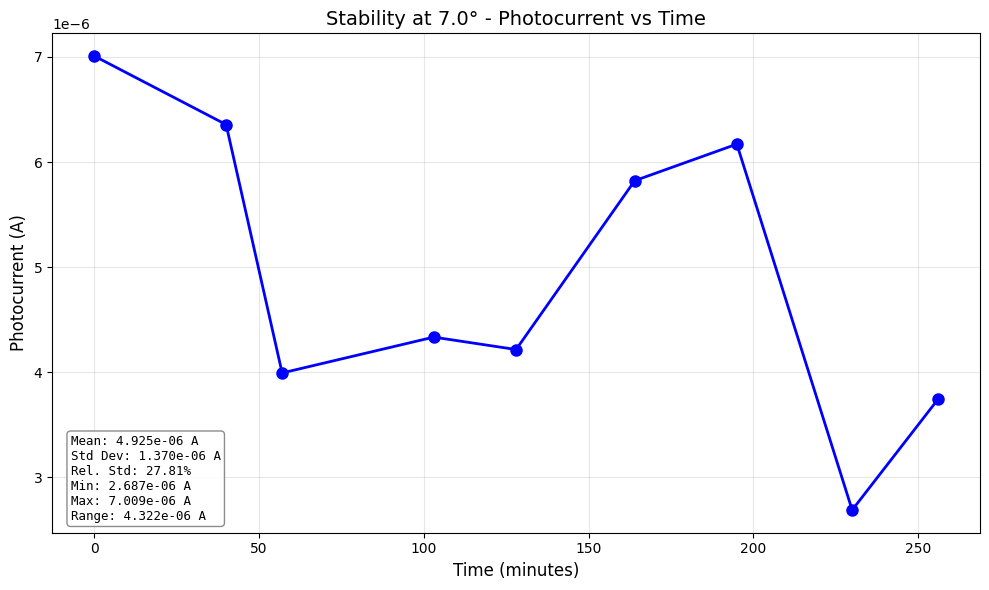

In [ ]:
""" # PLOT TO VISUALISE THE VARIATION IN INTENSITY OVER TIME AT A SELECTED ANGLE

import matplotlib.pyplot as plt
import numpy as np
import os
from datetime import datetime

def actuator_angle_to_wavelength(theta_deg):
    # Equation 20: m * lambda = 2 * d * cos(phi) * sin(gamma * (theta - theta0))

    d = 835.5          # nm (1 / 1200 lines/mm)
    phi = 35           # degrees (half deviation angle)
    gamma = 1.00694    # actuator scaling factor
    theta0 = -1.02898  # degrees (angular offset)
    m = 1              # first diffraction order

    theta_rad = np.radians(theta_deg)
    theta0_rad = np.radians(theta0)
    phi_rad = np.radians(phi)

    C = 2 * d * np.cos(phi_rad)  # ≈ 1365 nm
    wavelength = (C * np.sin(gamma * (theta_rad - theta0_rad))) / m

    return wavelength

# EXPERIMENTAL DATA
base_path = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Stability"

file_configs = [
    ("stability_20260720_no1_-2_15_1.txt", "09:49"),
    ("stability_20260720_no2_-2_15_1.txt", "10:29"),
    ("stability_20260720_no3_-2_15_1.txt", "10:46"),
    ("stability_20260720_no4_-2_15_1.txt", "11:32"),
    ("stability_20260720_no5_-2_15_1.txt", "11:57"),
    ("stability_20260720_no6_-2_15_1.txt", "12:33"),
    ("stability_20260720_no7_-2_15_1.txt", "13:04"),
    ("stability_20260720_no8_-2_15_1.txt", "13:39"),
    ("stability_20260720_no9_-2_15_1.txt", "14:05")
]

# Target angle
target_angle = 7.0

# Time reference
first_time = datetime.strptime(file_configs[0][1], "%H:%M")

# Store data
time_minutes = []
photocurrent_values = []

for filename, time_str in file_configs:
    filepath = os.path.join(base_path, filename)

    try:
        data = np.loadtxt(filepath, delimiter=',', usecols=(0, 1))
        angle = data[:, 0]
        photocurrent = data[:, 1]

        # Find the index closest to the target angle
        idx = np.argmin(np.abs(angle - target_angle))
        pc_value = photocurrent[idx]

        # Calculate the time in minutes since the first measurement
        current_time = datetime.strptime(time_str, "%H:%M")
        minutes = (current_time - first_time).total_seconds() / 60.0

        time_minutes.append(minutes)
        photocurrent_values.append(pc_value)

        print(f"{time_str}: {minutes:.1f} min, photocurrent={pc_value:.4e} A")

    except Exception as e:
        print(f"Error for {filename}: {e}")

# PLOTTING
ax.text(0.02, 0.02, stats_text, transform=ax.transAxes,
        verticalalignment='bottom',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray'),
        fontsize=9, family='monospace')


fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(time_minutes, photocurrent_values, 'bo-', linewidth=2, markersize=8)

ax.set_xlabel('Time (minutes)', fontsize=12)
ax.set_ylabel('Photocurrent (A)', fontsize=12)
ax.set_title(f'Stability at {target_angle}° - Photocurrent vs Time', fontsize=14)
ax.grid(True, alpha=0.3)

# Calculation of statistics
mean_pc = np.mean(photocurrent_values)
std_pc = np.std(photocurrent_values)
min_pc = np.min(photocurrent_values)
max_pc = np.max(photocurrent_values)
range_pc = max_pc - min_pc
rel_std = (std_pc / mean_pc) * 100  # écart-type relatif en %

# Printing statistics
stats_text = (
    f'Mean: {mean_pc:.3e} A\n'
    f'Std Dev: {std_pc:.3e} A\n'
    f'Rel. Std: {rel_std:.2f}%\n'
    f'Min: {min_pc:.3e} A\n'
    f'Max: {max_pc:.3e} A\n'
    f'Range: {range_pc:.3e} A'
)

ax.text(0.02, 0.02, stats_text, transform=ax.transAxes,
        verticalalignment='bottom',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray'),
        fontsize=9, family='monospace')

plt.tight_layout()

#save_path = os.path.join(base_path, f"stability_at_{target_angle}deg_analysis.png")
#plt.savefig(save_path, dpi=300, bbox_inches='tight')

plt.show() """

## STABILITY ANALYSIS - No window/ Full 

* Used to ...

STABILITY REPORT
Total Duration: 1.94 hours
Global Mean Photocurrent: 6.436188e-05 A


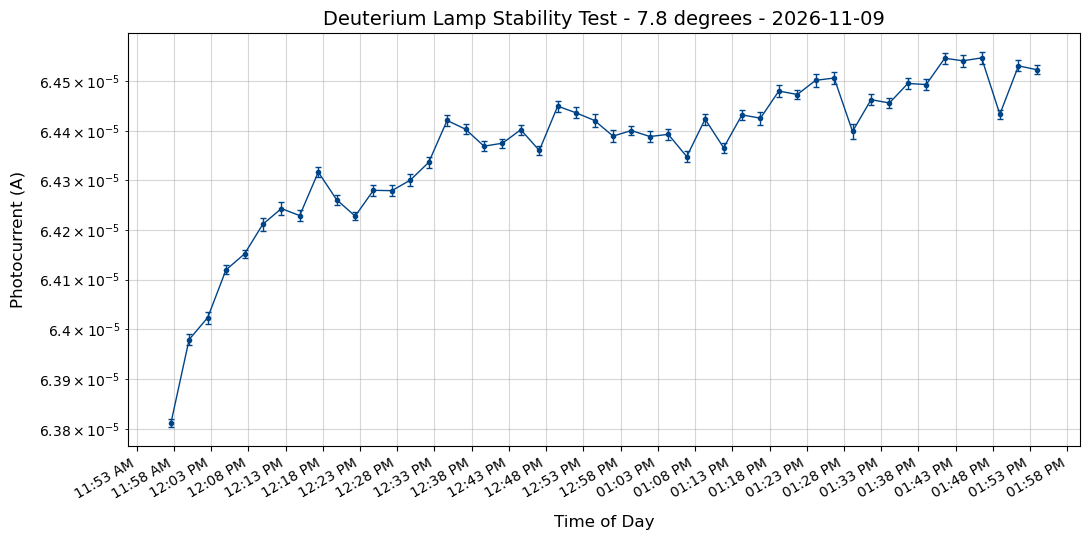

In [35]:
# 2nd Stability Test

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import numpy as np
import os

# LOAD DATA
#path_file = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Stability\test_stability_20260721.txt"
path_file = r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-09)_Data\hour_3to4_spectrum_hole_num_2.txt"
df = pd.read_csv(path_file)

# Convert timestamps to datetime objects
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['t_min'] = (df['timestamp'] - df['timestamp'].iloc[0]).dt.total_seconds() / 60

# EXTRACT STATS & DATE FOR THE TITLE
experiment_date = df['timestamp'].iloc[0].strftime('%Y-%m-%d')

duration_hours = df['t_min'].max() / 60
current_mean_total = df['current_mean_A'].mean()

print("STABILITY REPORT")
print(f"Total Duration: {duration_hours:.2f} hours")
print(f"Global Mean Photocurrent: {current_mean_total:.6e} A")

# PLOTTING
fig, ax = plt.subplots(figsize=(11, 5.5))

ax.errorbar(df['timestamp'], df['current_mean_A'], yerr=df['current_std_A'] / np.sqrt(df['n_samples']), color='#004488', linestyle='-', linewidth=1, fmt='o', markersize=3, elinewidth=1, capsize=2, label='Photocurrent (mean ± std)')

ax.set_title(f'Deuterium Lamp Stability Test - 7.8 degrees - {experiment_date}', fontsize=14)
ax.set_xlabel('Time of Day', fontsize=12, labelpad=10)
ax.set_ylabel('Photocurrent (A)', fontsize=12, labelpad=10)
ax.set_yscale('log')

ax.grid(True, which='Both', linestyle='-', alpha=0.5, color='#b0b0b0')

# TIME AXIS FORMATTING (12-hour system, hour & half-hour ticks)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%I:%M %p'))
#ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=[0, 30]))
ax.xaxis.set_major_locator(mdates.MinuteLocator(interval=5))
fig.autofmt_xdate(rotation=30, ha='right')

#save_path = os.path.join(r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Stability\stability_at_5.65deg_plot_data_5min_intervals_20260721.png")
#plt.savefig(save_path, dpi=300, bbox_inches='tight')
#plt.savefig("stability_report_hour_3to4_hole_3_(09-11-2026).png", dpi=600, bbox_inches='tight')

plt.tight_layout()
plt.show()

## Fitting the stability - (10/11/2026) 

* Proposed start point $y(t) = At^{m}$, where $0 < m < 1$
* The add sinusoidal behaviour $y(t) = At^{m} + Be^{-nt}cos(\omega t + \phi)$, where $0 < m < 1$
* Need to take the values to more useful orders e.g. take the 10^-5 out.

### One Cosine

    C =  1.023 ± 0.00034
    A =  5.779e-05 ± 2.1e-06
   B1 =  0.0006235 ± 0.00022
   w1 =  0.04787 ± 0.0053
 phi1 = -3.142 ± 0.82
Periods: 131.25 ± 14.44 min
Oscillation model: chi2_red = 6.49, BIC = 344.5
Linear only: chi2_red = 7.13, BIC = 386.1
Warmup only: chi2_red = 3.36, BIC = 186.5


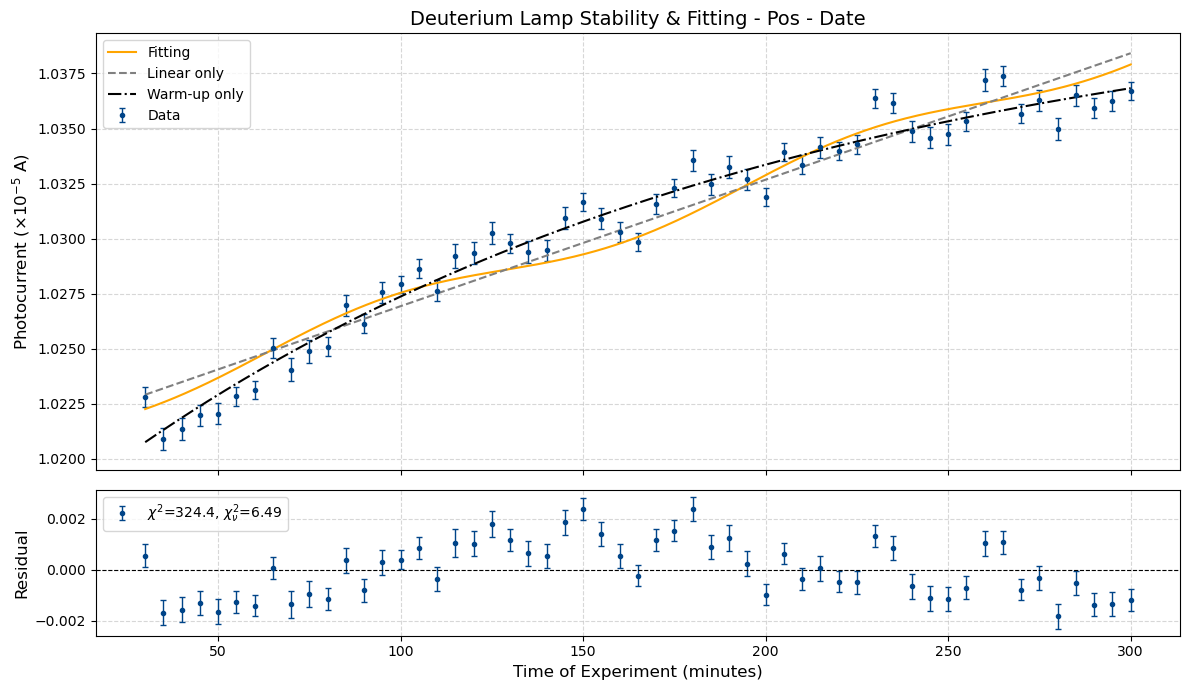

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Config
DATA_FILE = Path(r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\Data\(2026-10-11)_Stability_data\D2lamp_128nm_stability.txt")
WARMUP_MIN = 30.0 # Get rid of data before this time
LIMIT_MAX = 300.0
SCALE = 1e6 # May need to change after running once
N_STARTS = 20 # Random starting points for the fit

# Load and process the data
df = pd.read_csv(DATA_FILE)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)
df['t_min'] = (df['timestamp'] - df['timestamp'].iloc[0]).dt.total_seconds() / 60
df['y'] = df['current_mean_A'] * SCALE
df['yerr'] = df['current_std_A'] / np.sqrt(df['n_samples']) * SCALE

df = df.dropna(subset=['t_min', 'y', 'yerr'])
df = df[(df['yerr'] > 0) & (df['t_min'] >= WARMUP_MIN) & (df['t_min'] <= LIMIT_MAX)]

t_abs = df['t_min'].to_numpy()
t = t_abs - t_abs[0] # time since start of fit window
y = df['y'].to_numpy()
yerr = df['yerr'].to_numpy()

# Models
def linear_model(t, C, A):
    return C + A * t

def stability_model(t, C, A, B1, w1, phi1):
    """Linear drift + two independent sinusoids.
    C: level at start of window
    A: drift per min
    B1: amplitudes
    w1: angular frequencies (rad/min, period = 2*pi/w), phi1: phases.
    """
    return (C + A * t
            + B1 * np.cos(w1 * t + phi1))

def warmup_model(t, C, A, tau):
    """
    Warm-up
    C: starting level (at t = 0, ignoring the oscillation)
    A: total warm-up rise
    tau: warm-up time constant (min)
    B: initial oscillation amplitude
    n: oscillation damping rate (1/min)
    omega: angular frequency (rad/min), period = 2*pi/omega
    phi: phase (rad)
    """
    return C + A * (1 - np.exp(-t / tau))

def fit_stats(y, yerr, y_fit, n_params):
    resid = y - y_fit
    chi2 = np.sum((resid / yerr) ** 2)
    dof = len(y) - n_params
    bic = chi2 + n_params * np.log(len(y))
    return resid, chi2, chi2 / dof, bic

# Define the bounds
T = t.max()
dt = np.median(np.diff(t))
w_min, w_max = 2 * np.pi / T, np.pi / dt        # window length .. Nyquist
span = np.ptp(y)

#         C            A     B1      w1     phi1
lower = [y.min()-span, -1,   0,    w_min, -np.pi]
upper = [y.max()+span,  1,   span, w_max,  np.pi]

# Scan for the best start parameters
A0, C0 = np.polyfit(t, y, 1)
B0 = 0.5 * np.std(y - (C0 + A0 * t))
rng = np.random.default_rng(0)

best = None
for _ in range(N_STARTS):
    w1 = rng.uniform(w_min, w_max)
    p0 = [C0, A0, B0, w1, rng.uniform(-np.pi, np.pi)]
    try:
        p, cov = curve_fit(stability_model, t, y, p0=p0, sigma=yerr, absolute_sigma=False, bounds=(lower, upper), max_nfev=20000)
    except RuntimeError:
        continue
    chi2 = np.sum(((y - stability_model(t, *p)) / yerr) ** 2)
    if best is None or chi2 < best[0]:
        best = (chi2, p, cov)

if best is None:
    raise RuntimeError("No fit converged. Check the data and bounds.")
_, popt, pcov = best
perr = np.sqrt(np.diag(pcov))

# Statistics for the oscillation model
res, chi2, red_chi2, bic = fit_stats(y, yerr, stability_model(t, *popt), len(popt))

# Compare against the linear fit
plin, _ = curve_fit(linear_model, t, y, sigma=yerr)
_, chi2_lin, red_lin, bic_lin = fit_stats(y, yerr, linear_model(t, *plin), 2)

# Compare against the warm-up fit
pwarm, _ = curve_fit(warmup_model, t, y, sigma=yerr)
_, chi2_warm, red_warm, bic_warm = fit_stats(y, yerr, warmup_model(t, *pwarm), 3)

names = ["C", "A", "B1", "w1", "phi1"]
for n, v, e in zip(names, popt, perr):
    print(f"{n:>5} = {v: .4g} ± {e:.2g}")
print(f"Periods: {2*np.pi/popt[3]:.2f} ± {2*np.pi/popt[3] * perr[3]/popt[3]:.2f} min")
print(f"Oscillation model: chi2_red = {red_chi2:.2f}, BIC = {bic:.1f}")
print(f"Linear only: chi2_red = {red_lin:.2f}, BIC = {bic_lin:.1f}")
print(f"Warmup only: chi2_red = {red_warm:.2f}, BIC = {bic_warm:.1f}")

# Plot
t_fine = np.linspace(0, T, 500)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

ax1.errorbar(t_abs, y, yerr, fmt='o', ms=3, elinewidth=1, capsize=2,
             color='#004488', label='Data')
ax1.plot(t_fine + t_abs[0] , stability_model(t_fine, *popt), color='orange', label='Fitting')
ax1.plot(t_fine + t_abs[0], linear_model(t_fine, *plin), '--', color='gray', label='Linear only')
ax1.plot(t_fine + t_abs[0], warmup_model(t_fine, *pwarm), '-.', color='gray', label='Warm-up only')
ax1.set_title('Deuterium Lamp Stability & Fitting - Pos - Date', fontsize=14)
ax1.set_ylabel(r'Photocurrent ($\times10^{-5}$ A)', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

ax2.errorbar(t_abs, res, yerr, fmt='o', ms=3, elinewidth=1, capsize=2, color='#004488', label=rf'$\chi^2$={chi2:.1f}, $\chi^2_\nu$={red_chi2:.2f}')
ax2.axhline(0, lw=0.8, ls='--', color='k')
ax2.set_xlabel('Time of Experiment (minutes)', fontsize=12)
ax2.set_ylabel('Residual', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

fig.tight_layout()
plt.show()

### Two Cosines...

    C =  1.023 ± 0.00044
    A =  5.749e-05 ± 2.5e-06
   B1 =  0.001138 ± 0.00022
   w1 =  0.02327 ± 0.0051
 phi1 =  3.142 ± 0.73
   B2 =  0.0001421 ± 0.00019
   w2 =  0.1043 ± 0.016
 phi2 =  1.388 ± 2.6
Periods: 270.0 ± 58.72 min and 60.23 ± 42.69 min
Oscillation model: chi2_red = 4.22, BIC = 230.4
Linear only: chi2_red = 7.13, BIC = 386.1
Warmup only: chi2_red = 3.36, BIC = 186.5


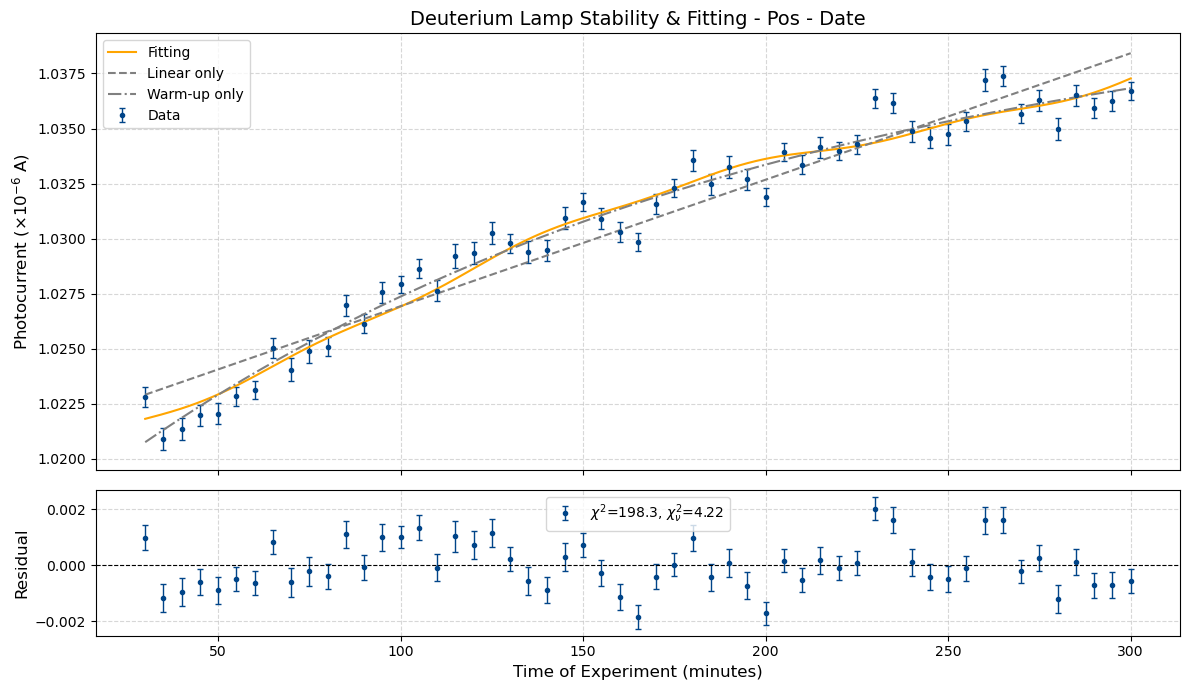

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ---------- Config ----------
DATA_FILE = Path(r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\Data\(2026-10-11)_Stability_data\D2lamp_128nm_stability.txt")
WARMUP_MIN = 30.0      # discard data before this (minutes)
LIMIT_MAX = 300.0
SCALE = 1e6            # plot/fit in units of 1e-5 A
N_STARTS = 10         # random starting points for the fit

# ---------- Load and clean ----------
df = pd.read_csv(DATA_FILE)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)
df['t_min'] = (df['timestamp'] - df['timestamp'].iloc[0]).dt.total_seconds() / 60
df['y'] = df['current_mean_A'] * SCALE
df['yerr'] = df['current_std_A'] / np.sqrt(df['n_samples']) * SCALE

df = df.dropna(subset=['t_min', 'y', 'yerr'])
df = df[(df['yerr'] > 0) & (df['t_min'] >= WARMUP_MIN) & (df['t_min'] <= LIMIT_MAX)]

t_abs = df['t_min'].to_numpy()
t = t_abs - t_abs[0]               # time since start of fit window
y = df['y'].to_numpy()
yerr = df['yerr'].to_numpy()

# ---------- Models ----------
def linear_model(t, C, A):
    return C + A * t

def stability_model(t, C, A, B1, w1, phi1, B2, w2, phi2):
    """Linear drift + two independent sinusoids.
    C: level at start of window, A: drift per min,
    Bi: amplitudes, wi: angular frequencies (rad/min, period = 2*pi/w), phii: phases."""
    return (C + A * t
            + B1 * np.cos(w1 * t + phi1)
            + B2 * np.cos(w2 * t + phi2))

def warmup_model(t, C, A, tau):
    """
    Warm-up
    C: starting level (at t = 0, ignoring the oscillation)
    A: total warm-up rise
    tau: warm-up time constant (min)
    B: initial oscillation amplitude
    n: oscillation damping rate (1/min)
    omega: angular frequency (rad/min), period = 2*pi/omega
    phi: phase (rad)
    """
    return C + A * (1 - np.exp(-t / tau))

def fit_stats(y, yerr, y_fit, n_params):
    resid = y - y_fit
    chi2 = np.sum((resid / yerr) ** 2)
    dof = len(y) - n_params
    bic = chi2 + n_params * np.log(len(y))
    return resid, chi2, chi2 / dof, bic

# Define the bounds
T = t.max()
dt = np.median(np.diff(t))
w_min, w_max = 2 * np.pi / T, np.pi / dt        # window length .. Nyquist
span = 2*np.ptp(y)

#         C            A     B1    w1     phi1   B2    w2     phi2
lower = [y.min()-span, -1,   0,    w_min, -np.pi, 0,    w_min, -np.pi]
upper = [y.max()+span,  1,   span, w_max,  np.pi, span, w_max,  np.pi]

# Scan for the best start parameters
A0, C0 = np.polyfit(t, y, 1)
B0 = 0.5 * np.std(y - (C0 + A0 * t))
rng = np.random.default_rng(0)

best = None
for _ in range(N_STARTS):
    w1, w2 = rng.uniform(w_min, w_max, 2)
    p0 = [C0, A0, B0, w1, rng.uniform(-np.pi, np.pi), B0, w2, rng.uniform(-np.pi, np.pi)]
    try:
        p, cov = curve_fit(stability_model, t, y, p0=p0, sigma=yerr, absolute_sigma=False, bounds=(lower, upper), max_nfev=20000)
    except RuntimeError:
        continue
    chi2 = np.sum(((y - stability_model(t, *p)) / yerr) ** 2)
    if best is None or chi2 < best[0]:
        best = (chi2, p, cov)

if best is None:
    raise RuntimeError("No fit converged. Check the data and bounds.")
_, popt, pcov = best
perr = np.sqrt(np.diag(pcov))

# Statistics for the oscillation model
res, chi2, red_chi2, bic = fit_stats(y, yerr, stability_model(t, *popt), len(popt))

# Compare against the linear fit
plin, _ = curve_fit(linear_model, t, y, sigma=yerr)
_, chi2_lin, red_lin, bic_lin = fit_stats(y, yerr, linear_model(t, *plin), 2)

# Compare against the warm-up fit
pwarm, _ = curve_fit(warmup_model, t, y, sigma=yerr)
_, chi2_warm, red_warm, bic_warm = fit_stats(y, yerr, warmup_model(t, *pwarm), 3)

names = ["C", "A", "B1", "w1", "phi1", "B2", "w2", "phi2"]
for n, v, e in zip(names, popt, perr):
    print(f"{n:>5} = {v: .4g} ± {e:.2g}")
    
print(f"Periods: {2*np.pi/popt[3]:.1f} ± {2*np.pi/popt[3] * perr[3]/popt[3]:.2f} min and {2*np.pi/popt[6]:.2f} ± {2*np.pi/popt[3] * perr[6]/popt[6]:.2f} min")
print(f"Oscillation model: chi2_red = {red_chi2:.2f}, BIC = {bic:.1f}")
print(f"Linear only: chi2_red = {red_lin:.2f}, BIC = {bic_lin:.1f}")
print(f"Warmup only: chi2_red = {red_warm:.2f}, BIC = {bic_warm:.1f}")

# Plot
t_fine = np.linspace(0, T, 500)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

ax1.errorbar(t_abs, y, yerr, fmt='o', ms=3, elinewidth=1, capsize=2,
             color='#004488', label='Data')
ax1.plot(t_fine + t_abs[0], stability_model(t_fine, *popt), color='orange', label='Fitting')
ax1.plot(t_fine + t_abs[0], linear_model(t_fine, *plin), '--', color='gray', label='Linear only')
ax1.plot(t_fine + t_abs[0], warmup_model(t_fine, *pwarm), '-.', color='gray', label='Warm-up only')
ax1.set_title('Deuterium Lamp Stability & Fitting - Pos - Date', fontsize=14)
ax1.set_ylabel(r'Photocurrent ($\times10^{-6}$ A)', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

ax2.errorbar(t_abs, res, yerr, fmt='o', ms=3, elinewidth=1, capsize=2, color='#004488', label=rf'$\chi^2$={chi2:.1f}, $\chi^2_\nu$={red_chi2:.2f}')
ax2.axhline(0, lw=0.8, ls='--', color='k')
ax2.set_xlabel('Time of Experiment (minutes)', fontsize=12)
ax2.set_ylabel('Residual', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

fig.tight_layout()
plt.show()

    C =  1.021 ± 0.00034
    A =  0.02068 ± 0.001
  tau =  178.3 ± 21
   B1 =  0.0004892 ± 0.00014
   w1 =  0.222 ± 0.0035
 phi1 = -1.394 ± 0.56
   B2 =  0.0004642 ± 0.00014
   w2 =  0.1571 ± 0.0038
 phi2 =  0.5705 ± 0.61
Periods: 28.30 ± 0.45 min and 39.99 ± 0.97 min
Oscillation model: chi2_red = 2.43, BIC = 148.0
Linear only: chi2_red = 7.13, BIC = 386.1
Warmup only: chi2_red = 3.36, BIC = 186.5


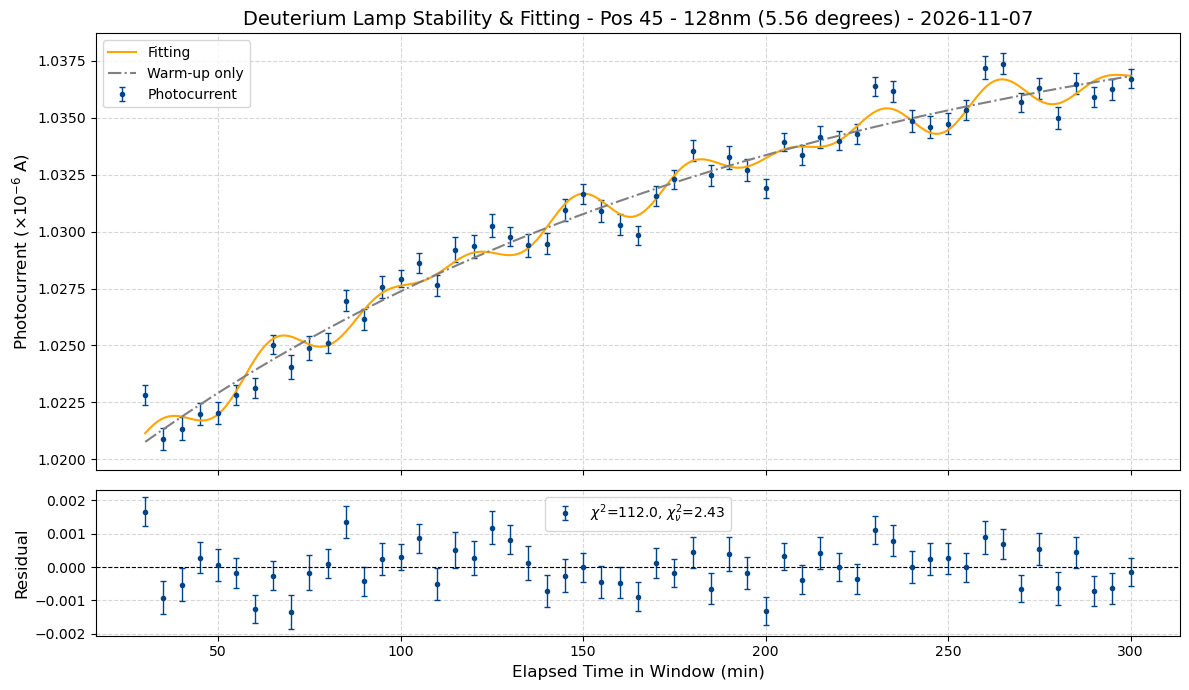

In [5]:
# Two cosines with warmup not linear
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ---------- Config ----------
DATA_FILE = Path(r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\Data\(2026-10-11)_Stability_data\D2lamp_128nm_stability.txt")
WARMUP_MIN = 30.0      # discard data before this (minutes)
LIMIT_MAX = 300.0
SCALE = 1e6            # plot/fit in units of 1e-5 A
N_STARTS = 100         # random starting points for the fit

# ---------- Load and clean ----------
df = pd.read_csv(DATA_FILE)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)
df['t_min'] = (df['timestamp'] - df['timestamp'].iloc[0]).dt.total_seconds() / 60
df['y'] = df['current_mean_A'] * SCALE
df['yerr'] = df['current_std_A'] / np.sqrt(df['n_samples']) * SCALE

df = df.dropna(subset=['t_min', 'y', 'yerr'])
df = df[(df['yerr'] > 0) & (df['t_min'] >= WARMUP_MIN) & (df['t_min'] <= LIMIT_MAX)]

t_abs = df['t_min'].to_numpy()
t = t_abs - t_abs[0]               # time since start of fit window
y = df['y'].to_numpy()
yerr = df['yerr'].to_numpy()

# ---------- Models ----------
def linear_model(t, C, A):
    return C + A * t

def stability_model(t, C, A, tau, B1, w1, phi1, B2, w2, phi2):
    """Linear drift + two independent sinusoids.
    C: level at start of window, A: drift per min,
    Bi: amplitudes, wi: angular frequencies (rad/min, period = 2*pi/w), phii: phases."""
    return (C + A * (1 - np.exp(-t / tau))
            + B1 * np.cos(w1 * t + phi1)
            + B2 * np.cos(w2 * t + phi2))

def warmup_model(t, C, A, tau):
    """
    Warm-up
    C: starting level (at t = 0, ignoring the oscillation)
    A: total warm-up rise
    tau: warm-up time constant (min)
    B: initial oscillation amplitude
    n: oscillation damping rate (1/min)
    omega: angular frequency (rad/min), period = 2*pi/omega
    phi: phase (rad)
    """
    return C + A * (1 - np.exp(-t / tau))

def fit_stats(y, yerr, y_fit, n_params):
    resid = y - y_fit
    chi2 = np.sum((resid / yerr) ** 2)
    dof = len(y) - n_params
    bic = chi2 + n_params * np.log(len(y))
    return resid, chi2, chi2 / dof, bic

# Define the bounds
T = t.max()
dt = np.median(np.diff(t))
w_min, w_max = 2 * np.pi / T, np.pi / dt        # window length .. Nyquist
span = 2*np.ptp(y)

#         C            A  tau   B1    w1     phi1   B2    w2     phi2
lower = [y.min()-span, -1, 100,  0,    w_min, -np.pi, 0,    w_min, -np.pi]
upper = [y.max()+span,  1, 300,  span, w_max,  np.pi, span, w_max,  np.pi]

# Scan for the best start parameters
A0, C0 = np.polyfit(t, y, 1)
B0 = 0.5 * np.std(y - (C0 + A0 * t))
rng = np.random.default_rng(0)

best = None
for _ in range(N_STARTS):
    w1, w2 = rng.uniform(w_min, w_max, 2)
    p0 = [C0, A0,  150, B0, w1, rng.uniform(-np.pi, np.pi), B0, w2, rng.uniform(-np.pi, np.pi)]
    try:
        p, cov = curve_fit(stability_model, t, y, p0=p0, sigma=yerr, absolute_sigma=False, bounds=(lower, upper), max_nfev=20000)
    except RuntimeError:
        continue
    chi2 = np.sum(((y - stability_model(t, *p)) / yerr) ** 2)
    if best is None or chi2 < best[0]:
        best = (chi2, p, cov)

if best is None:
    raise RuntimeError("No fit converged. Check the data and bounds.")
_, popt, pcov = best
perr = np.sqrt(np.diag(pcov))

# Statistics for the oscillation model
res, chi2, red_chi2, bic = fit_stats(y, yerr, stability_model(t, *popt), len(popt))

# Compare against the linear fit
plin, _ = curve_fit(linear_model, t, y, sigma=yerr)
_, chi2_lin, red_lin, bic_lin = fit_stats(y, yerr, linear_model(t, *plin), 2)

# Compare against the warm-up fit
pwarm, _ = curve_fit(warmup_model, t, y, sigma=yerr)
_, chi2_warm, red_warm, bic_warm = fit_stats(y, yerr, warmup_model(t, *pwarm), 3)

names = ["C", "A", "tau", "B1", "w1", "phi1", "B2", "w2", "phi2"]
for n, v, e in zip(names, popt, perr):
    print(f"{n:>5} = {v: .4g} ± {e:.2g}")
    
print(f"Periods: {2*np.pi/popt[4]:.2f} ± {2*np.pi/popt[4] * perr[4]/popt[4]:.2f} min and {2*np.pi/popt[7]:.2f} ± {2*np.pi/popt[7] * perr[7]/popt[7]:.2f} min")
print(f"Oscillation model: chi2_red = {red_chi2:.2f}, BIC = {bic:.1f}")
print(f"Linear only: chi2_red = {red_lin:.2f}, BIC = {bic_lin:.1f}")
print(f"Warmup only: chi2_red = {red_warm:.2f}, BIC = {bic_warm:.1f}")

# Plot
t_fine = np.linspace(0, T, 500)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

ax1.errorbar(t_abs, y, yerr, fmt='o', ms=3, elinewidth=1, capsize=2, color='#004488', label='Photocurrent')
ax1.plot(t_fine + t_abs[0], stability_model(t_fine, *popt), color='orange', label='Fitting')
#ax1.plot(t_fine + t_abs[0], linear_model(t_fine, *plin), '--', color='gray', label='Linear only')
ax1.plot(t_fine + t_abs[0], warmup_model(t_fine, *pwarm), '-.', color='gray', label='Warm-up only')
ax1.set_title('Deuterium Lamp Stability & Fitting - Pos 45 - 128nm (5.56 degrees) - 2026-11-07', fontsize=14)
ax1.set_ylabel(r'Photocurrent ($\times10^{-6}$ A)', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

ax2.errorbar(t_abs, res, yerr, fmt='o', ms=3, elinewidth=1, capsize=2, color='#004488', label=rf'$\chi^2$={chi2:.1f}, $\chi^2_\nu$={red_chi2:.2f}')
ax2.axhline(0, lw=0.8, ls='--', color='k')
ax2.set_xlabel('Elapsed Time in Window (min)', fontsize=12)
ax2.set_ylabel('Residual', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

fig.tight_layout()
plt.show()

In [28]:
2*np.pi/w_min

270.0

### Three cosines!!

    C =  1.023 ± 0.00095
    A =  5.509e-05 ± 3.9e-06
   B1 =  0.0004256 ± 0.00014
   w1 =  0.2311 ± 0.0045
 phi1 =  3.142 ± 0.7
   B2 =  0.001299 ± 0.0076
   w2 =  0.0432 ± 0.033
 phi2 =  3.142 ± 5.2
   B3 =  0.001503 ± 0.0072
   w3 =  0.0314 ± 0.04
 phi3 =  1.85 ± 6.3
Periods: 27.19 ± 0.53 min and 145.45 ± 112.36 min and and 200.10 ± 254.29 min
Oscillation model: chi2_red = 2.63, BIC = 159.9
Linear only: chi2_red = 7.13, BIC = 386.1
Warmup only: chi2_red = 3.36, BIC = 186.5


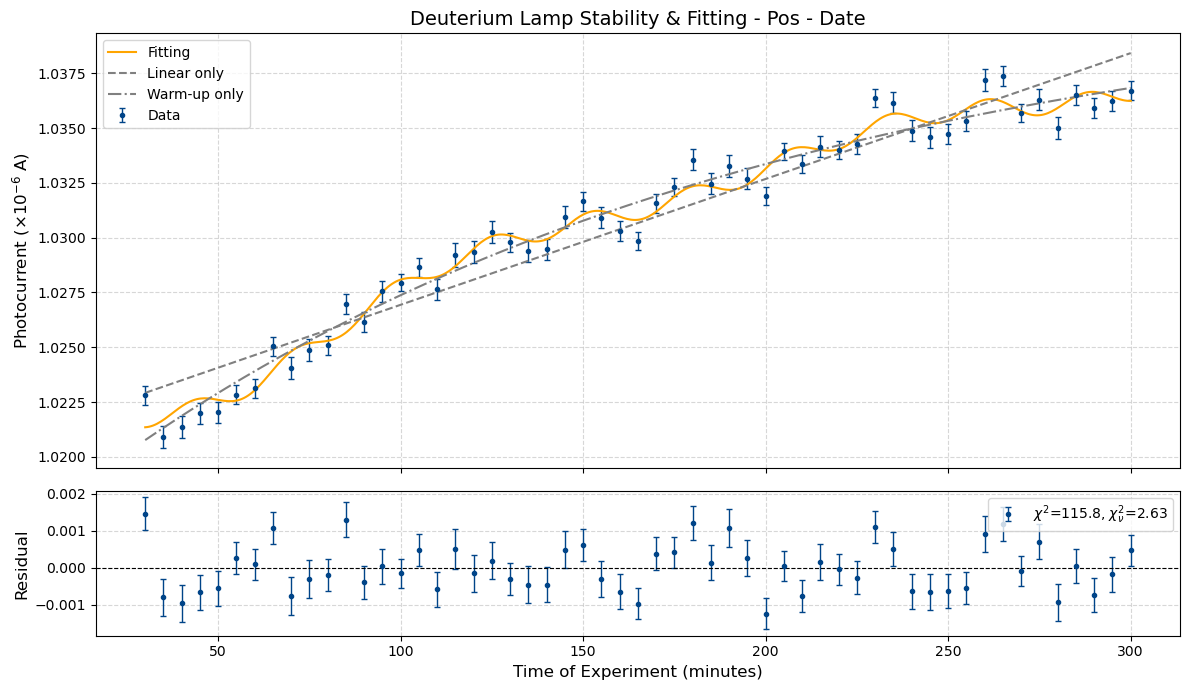

In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ---------- Config ----------
DATA_FILE = Path(r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\Data\(2026-10-11)_Stability_data\D2lamp_128nm_stability.txt")
WARMUP_MIN = 30.0      # discard data before this (minutes)
LIMIT_MAX = 300.0
SCALE = 1e6            # plot/fit in units of 1e-5 A
N_STARTS = 100         # random starting points for the fit

# ---------- Load and clean ----------
df = pd.read_csv(DATA_FILE)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)
df['t_min'] = (df['timestamp'] - df['timestamp'].iloc[0]).dt.total_seconds() / 60
df['y'] = df['current_mean_A'] * SCALE
df['yerr'] = df['current_std_A'] / np.sqrt(df['n_samples']) * SCALE

df = df.dropna(subset=['t_min', 'y', 'yerr'])
df = df[(df['yerr'] > 0) & (df['t_min'] >= WARMUP_MIN) & (df['t_min'] <= LIMIT_MAX)]

t_abs = df['t_min'].to_numpy()
t = t_abs - t_abs[0]               # time since start of fit window
y = df['y'].to_numpy()
yerr = df['yerr'].to_numpy()

# ---------- Models ----------
def linear_model(t, C, A):
    return C + A * t

def stability_model(t, C, A, B1, w1, phi1, B2, w2, phi2, B3, w3, phi3):
    """Linear drift + two independent sinusoids.
    C: level at start of window, A: drift per min,
    Bi: amplitudes, wi: angular frequencies (rad/min, period = 2*pi/w), phii: phases."""
    return (C + A * t
            + B1 * np.cos(w1 * t + phi1)
            + B2 * np.cos(w2 * t + phi2)
            + B3 * np.cos(w3 * t + phi3))

def warmup_model(t, C, A, tau):
    """
    Warm-up
    C: starting level (at t = 0, ignoring the oscillation)
    A: total warm-up rise
    tau: warm-up time constant (min)
    B: initial oscillation amplitude
    n: oscillation damping rate (1/min)
    omega: angular frequency (rad/min), period = 2*pi/omega
    phi: phase (rad)
    """
    return C + A * (1 - np.exp(-t / tau))

def fit_stats(y, yerr, y_fit, n_params):
    resid = y - y_fit
    chi2 = np.sum((resid / yerr) ** 2)
    dof = len(y) - n_params
    bic = chi2 + n_params * np.log(len(y))
    return resid, chi2, chi2 / dof, bic

# Define the bounds
T = t.max()
dt = np.median(np.diff(t))
w_min, w_max = 2 * np.pi / T, np.pi / dt        # window length .. Nyquist
span = 2*np.ptp(y)

#         C            A     B1    w1     phi1   B2    w2     phi2
lower = [y.min()-span, -1,   0,    w_min, -np.pi, 0,    w_min, -np.pi, 0,    w_min, -np.pi]
upper = [y.max()+span,  1,   span, w_max,  np.pi, span, w_max,  np.pi, span, w_max,  np.pi]

# Scan for the best start parameters
A0, C0 = np.polyfit(t, y, 1)
B0 = 0.5 * np.std(y - (C0 + A0 * t))
rng = np.random.default_rng(0)

best = None
for _ in range(N_STARTS):
    w1, w2 = rng.uniform(w_min, w_max, 2)
    p0 = [C0, A0, B0, w1, rng.uniform(-np.pi, np.pi), B0, w2, rng.uniform(-np.pi, np.pi), B0, w2, rng.uniform(-np.pi, np.pi)]
    try:
        p, cov = curve_fit(stability_model, t, y, p0=p0, sigma=yerr, absolute_sigma=False, bounds=(lower, upper), max_nfev=20000)
    except RuntimeError:
        continue
    chi2 = np.sum(((y - stability_model(t, *p)) / yerr) ** 2)
    if best is None or chi2 < best[0]:
        best = (chi2, p, cov)

if best is None:
    raise RuntimeError("No fit converged. Check the data and bounds.")
_, popt, pcov = best
perr = np.sqrt(np.diag(pcov))

# Statistics for the oscillation model
res, chi2, red_chi2, bic = fit_stats(y, yerr, stability_model(t, *popt), len(popt))

# Compare against the linear fit
plin, _ = curve_fit(linear_model, t, y, sigma=yerr)
_, chi2_lin, red_lin, bic_lin = fit_stats(y, yerr, linear_model(t, *plin), 2)

# Compare against the warm-up fit
pwarm, _ = curve_fit(warmup_model, t, y, sigma=yerr)
_, chi2_warm, red_warm, bic_warm = fit_stats(y, yerr, warmup_model(t, *pwarm), 3)

names = ["C", "A", "B1", "w1", "phi1", "B2", "w2", "phi2", "B3", "w3", "phi3"]
for n, v, e in zip(names, popt, perr):
    print(f"{n:>5} = {v: .4g} ± {e:.2g}")
    
print(f"Periods: {2*np.pi/popt[3]:.2f} ± {2*np.pi/popt[3] * perr[3]/popt[3]:.2f} min and {2*np.pi/popt[6]:.2f} ± {2*np.pi/popt[6] * perr[6]/popt[6]:.2f} min and and {2*np.pi/popt[9]:.2f} ± {2*np.pi/popt[9] * perr[9]/popt[9]:.2f} min")
print(f"Oscillation model: chi2_red = {red_chi2:.2f}, BIC = {bic:.1f}")
print(f"Linear only: chi2_red = {red_lin:.2f}, BIC = {bic_lin:.1f}")
print(f"Warmup only: chi2_red = {red_warm:.2f}, BIC = {bic_warm:.1f}")

# Plot
t_fine = np.linspace(0, T, 500)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

ax1.errorbar(t_abs, y, yerr, fmt='o', ms=3, elinewidth=1, capsize=2,
             color='#004488', label='Data')
ax1.plot(t_fine + t_abs[0], stability_model(t_fine, *popt), color='orange', label='Fitting')
ax1.plot(t_fine + t_abs[0], linear_model(t_fine, *plin), '--', color='gray', label='Linear only')
ax1.plot(t_fine + t_abs[0], warmup_model(t_fine, *pwarm), '-.', color='gray', label='Warm-up only')
ax1.set_title('Deuterium Lamp Stability & Fitting - Pos - Date', fontsize=14)
ax1.set_ylabel(r'Photocurrent ($\times10^{-6}$ A)', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

ax2.errorbar(t_abs, res, yerr, fmt='o', ms=3, elinewidth=1, capsize=2, color='#004488', label=rf'$\chi^2$={chi2:.1f}, $\chi^2_\nu$={red_chi2:.2f}')
ax2.axhline(0, lw=0.8, ls='--', color='k')
ax2.set_xlabel('Time of Experiment (minutes)', fontsize=12)
ax2.set_ylabel('Residual', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

fig.tight_layout()
plt.show()

    C =  1.021 ± 0.00035
    A =  0.02079 ± 0.0011
   B1 =  181.1 ± 22
  tau =  0.0004919 ± 0.00015
   w1 =  0.2238 ± 0.0042
 phi1 = -1.664 ± 0.64
   B2 =  0.002135 ± 0.63
   w2 =  0.1639 ± 0.22
 phi2 =  3.142 ± 19
   B3 =  0.002514 ± 0.63
   w3 =  0.1624 ± 0.19
 phi3 =  0.1281 ± 16
Periods: 28.07 ± 0.53 min and 38.34 ± 51.67 min and and 38.69 ± 44.64 min
Oscillation model: chi2_red = 2.56, BIC = 158.3
Linear only: chi2_red = 7.13, BIC = 386.1
Warmup only: chi2_red = 3.36, BIC = 186.5


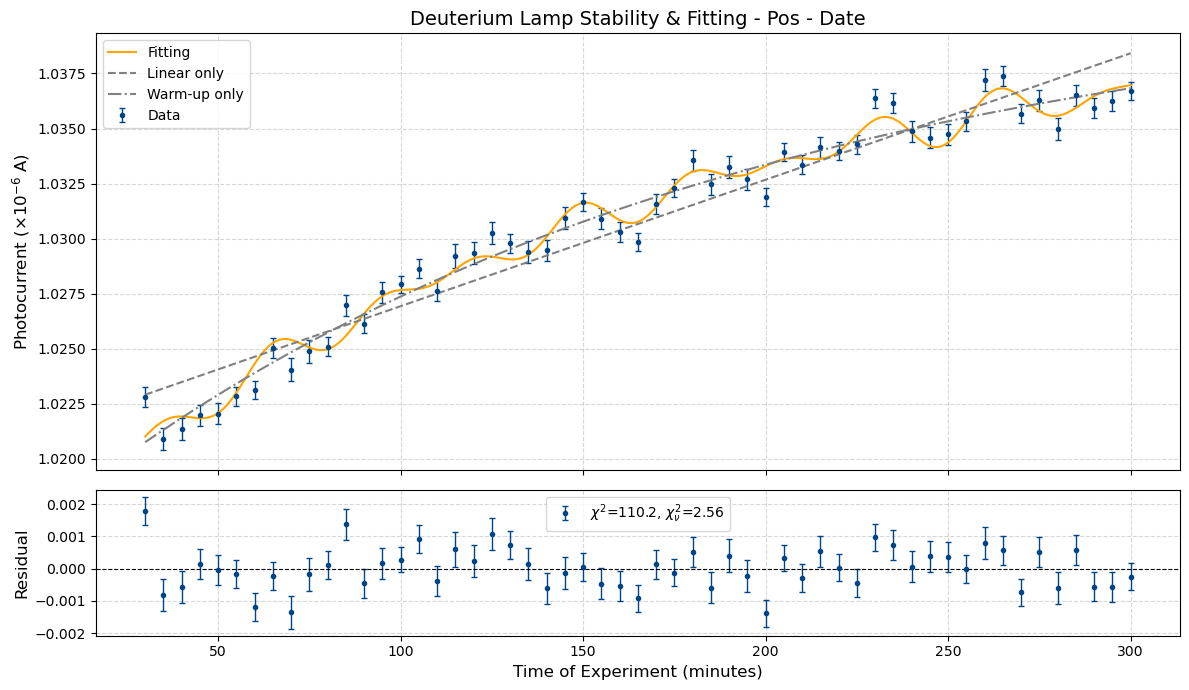

In [24]:
# Three cosines with warmup not linear
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ---------- Config ----------
DATA_FILE = Path(r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\Data\(2026-10-11)_Stability_data\D2lamp_128nm_stability.txt")
WARMUP_MIN = 30.0      # discard data before this (minutes)
LIMIT_MAX = 300.0
SCALE = 1e6            # plot/fit in units of 1e-5 A
N_STARTS = 100         # random starting points for the fit

# ---------- Load and clean ----------
df = pd.read_csv(DATA_FILE)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)
df['t_min'] = (df['timestamp'] - df['timestamp'].iloc[0]).dt.total_seconds() / 60
df['y'] = df['current_mean_A'] * SCALE
df['yerr'] = df['current_std_A'] / np.sqrt(df['n_samples']) * SCALE

df = df.dropna(subset=['t_min', 'y', 'yerr'])
df = df[(df['yerr'] > 0) & (df['t_min'] >= WARMUP_MIN) & (df['t_min'] <= LIMIT_MAX)]

t_abs = df['t_min'].to_numpy()
t = t_abs - t_abs[0]               # time since start of fit window
y = df['y'].to_numpy()
yerr = df['yerr'].to_numpy()

# ---------- Models ----------
def linear_model(t, C, A):
    return C + A * t

def stability_model(t, C, A, tau, B1, w1, phi1, B2, w2, phi2, B3, w3, phi3):
    """Linear drift + two independent sinusoids.
    C: level at start of window, A: drift per min,
    Bi: amplitudes, wi: angular frequencies (rad/min, period = 2*pi/w), phii: phases."""
    return (C + A * (1 - np.exp(-t / tau))
            + B1 * np.cos(w1 * t + phi1)
            + B2 * np.cos(w2 * t + phi2)
            + B3 * np.cos(w3 * t + phi3))

def warmup_model(t, C, A, tau):
    """
    Warm-up
    C: starting level (at t = 0, ignoring the oscillation)
    A: total warm-up rise
    tau: warm-up time constant (min)
    B: initial oscillation amplitude
    n: oscillation damping rate (1/min)
    omega: angular frequency (rad/min), period = 2*pi/omega
    phi: phase (rad)
    """
    return C + A * (1 - np.exp(-t / tau))

def fit_stats(y, yerr, y_fit, n_params):
    resid = y - y_fit
    chi2 = np.sum((resid / yerr) ** 2)
    dof = len(y) - n_params
    bic = chi2 + n_params * np.log(len(y))
    return resid, chi2, chi2 / dof, bic

# Define the bounds
T = t.max()
dt = np.median(np.diff(t))
w_min, w_max = 2 * np.pi / T, np.pi / dt        # window length .. Nyquist
span = 2*np.ptp(y)

#         C            A   tau     B1    w1     phi1   B2    w2     phi2
lower = [y.min()-span, -1, 100.0,  0,    w_min, -np.pi, 0,    w_min, -np.pi, 0,    w_min, -np.pi]
upper = [y.max()+span,  1, 300.0,  span, w_max,  np.pi, span, w_max,  np.pi, span, w_max,  np.pi]

# Scan for the best start parameters
A0, C0 = np.polyfit(t, y, 1)
B0 = 0.5 * np.std(y - (C0 + A0 * t))
rng = np.random.default_rng(0)

best = None
for _ in range(N_STARTS):
    w1, w2 = rng.uniform(w_min, w_max, 2)
    p0 = [C0, A0,  rng.uniform(100.0, 300.0), B0, w1, rng.uniform(-np.pi, np.pi), B0, w2, rng.uniform(-np.pi, np.pi), B0, w2, rng.uniform(-np.pi, np.pi)]
    try:
        p, cov = curve_fit(stability_model, t, y, p0=p0, sigma=yerr, absolute_sigma=False, bounds=(lower, upper), max_nfev=20000)
    except RuntimeError:
        continue
    chi2 = np.sum(((y - stability_model(t, *p)) / yerr) ** 2)
    if best is None or chi2 < best[0]:
        best = (chi2, p, cov)

if best is None:
    raise RuntimeError("No fit converged. Check the data and bounds.")
_, popt, pcov = best
perr = np.sqrt(np.diag(pcov))

# Statistics for the oscillation model
res, chi2, red_chi2, bic = fit_stats(y, yerr, stability_model(t, *popt), len(popt))

# Compare against the linear fit
plin, _ = curve_fit(linear_model, t, y, sigma=yerr)
_, chi2_lin, red_lin, bic_lin = fit_stats(y, yerr, linear_model(t, *plin), 2)

# Compare against the warm-up fit
pwarm, _ = curve_fit(warmup_model, t, y, sigma=yerr)
_, chi2_warm, red_warm, bic_warm = fit_stats(y, yerr, warmup_model(t, *pwarm), 3)

names = ["C", "A", "B1", "tau", "w1", "phi1", "B2", "w2", "phi2", "B3", "w3", "phi3"]
for n, v, e in zip(names, popt, perr):
    print(f"{n:>5} = {v: .4g} ± {e:.2g}")
    
print(f"Periods: {2*np.pi/popt[4]:.2f} ± {2*np.pi/popt[4] * perr[4]/popt[4]:.2f} min and {2*np.pi/popt[7]:.2f} ± {2*np.pi/popt[7] * perr[7]/popt[7]:.2f} min and and {2*np.pi/popt[10]:.2f} ± {2*np.pi/popt[10] * perr[10]/popt[10]:.2f} min")
print(f"Oscillation model: chi2_red = {red_chi2:.2f}, BIC = {bic:.1f}")
print(f"Linear only: chi2_red = {red_lin:.2f}, BIC = {bic_lin:.1f}")
print(f"Warmup only: chi2_red = {red_warm:.2f}, BIC = {bic_warm:.1f}")

# Plot
t_fine = np.linspace(0, T, 500)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

ax1.errorbar(t_abs, y, yerr, fmt='o', ms=3, elinewidth=1, capsize=2,
             color='#004488', label='Data')
ax1.plot(t_fine + t_abs[0], stability_model(t_fine, *popt), color='orange', label='Fitting')
ax1.plot(t_fine + t_abs[0], linear_model(t_fine, *plin), '--', color='gray', label='Linear only')
ax1.plot(t_fine + t_abs[0], warmup_model(t_fine, *pwarm), '-.', color='gray', label='Warm-up only')
ax1.set_title('Deuterium Lamp Stability & Fitting - Pos - Date', fontsize=14)
ax1.set_ylabel(r'Photocurrent ($\times10^{-6}$ A)', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

ax2.errorbar(t_abs, res, yerr, fmt='o', ms=3, elinewidth=1, capsize=2, color='#004488', label=rf'$\chi^2$={chi2:.1f}, $\chi^2_\nu$={red_chi2:.2f}')
ax2.axhline(0, lw=0.8, ls='--', color='k')
ax2.set_xlabel('Time of Experiment (minutes)', fontsize=12)
ax2.set_ylabel('Residual', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

fig.tight_layout()
plt.show()

In [6]:
# Periodogram

from scipy.signal import lombscargle
detrended = y - np.polyval(np.polyfit(t, y, 1), t)
ws = np.linspace(w_min, w_max, 1000)
power = lombscargle(t, detrended, ws, normalize=True)
print("Strongest period (min):", 2 * np.pi / ws[np.argmax(power)])

Strongest period (min): 270.0


In [81]:
2*np.pi/16.194083161148633

0.38799265414751183

## STABILITY ANALYSIS - LINEAR FIT & VOLATILITY HISTOGRAM

LINEAR FIT REPORT
New Start Time: 11:21 AM
New Start Time: 01:21 PM
Mean Current (Filtered Window): 1.026363e-06 A
Absolute Slope: 5.220462e-09 A/hour
Relative Slope (%): 0.5086 % per hour
Relative Slope (%): 0.008477 % per minute

STEP-TO-STEP VOLATILITY REPORT
Number of steps analyzed: 24
Average step variation: +0.0360 %
Step variation standard deviation: 0.0920 %


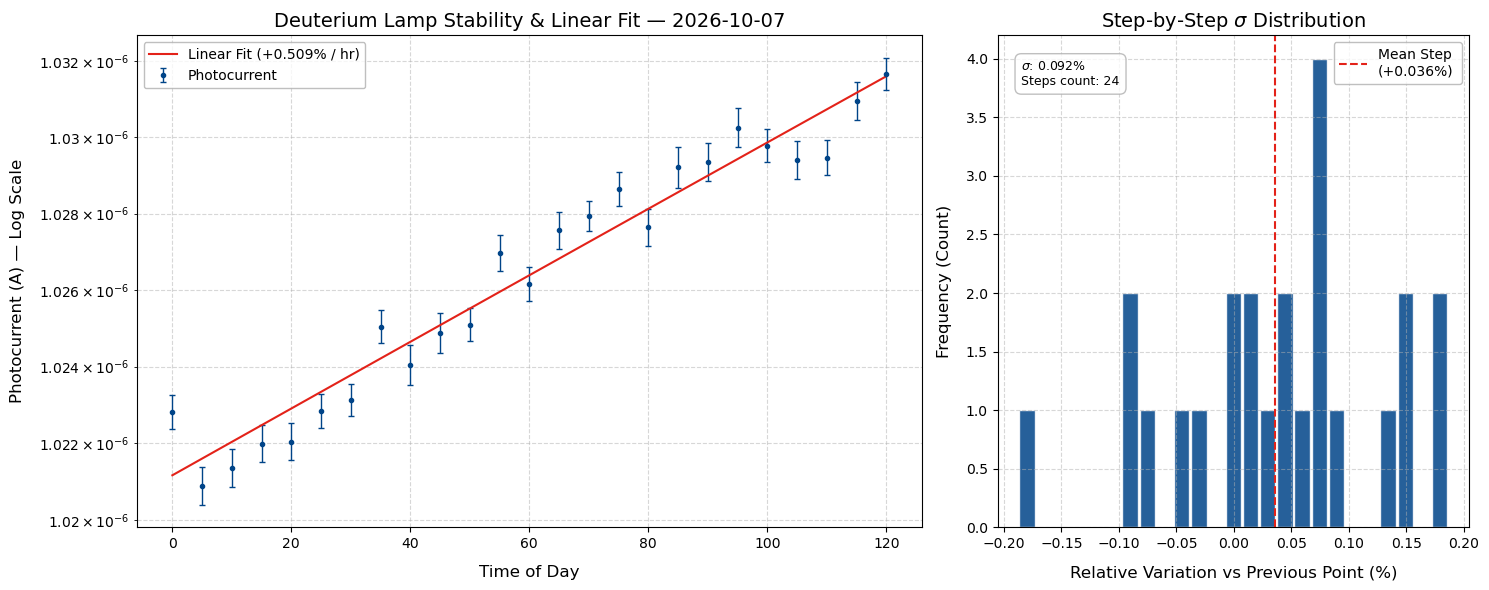

In [8]:
# STABILITY ANALYSIS - LINEAR FIT & VOLATILITY HISTOGRAM
# Note this has errorbars and filtered window twice... easy to change back.
import os
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# LOAD DATA
path_file = r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\Data\(2026-10-11)_Stability_data\D2lamp_128nm_stability.txt"
df = pd.read_csv(path_file)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['t_min'] = (df['timestamp'] - df['timestamp'].iloc[0]).dt.total_seconds() / 60

# FILTER DATA (Start at 10:25 AM, when lamp is "stable")
# Cannot be bothered to figure out the times... use like 30
df_filtered = df[df['t_min'] >= 30.0].copy()
df_filtered = df_filtered[df_filtered['t_min'] <= 150.0].copy() # cuts off the step seen at the end...

# CALCULATE LINEAR FIT & SLOPE IN %
# Convert filtered timestamps to numerical minutes/hours from the new start point
time_minutes = df_filtered['t_min'].values - df_filtered['t_min'].min()
time_hours = time_minutes / 60.0
current_vals = df_filtered['current_mean_A'].values
current_stds = df_filtered['current_std_A'] / np.sqrt(df_filtered['n_samples'])

# Fit a first-degree polynomial (straight line): y = mx + c
slope, intercept = np.polyfit(time_hours, current_vals, 1, w=1/current_stds)
fit_line = slope * time_hours + intercept

# Calculate relative slope percentage based on the global mean of this window
mean_current = np.mean(current_vals)
slope_pct_per_hour = (slope / mean_current) * 100
slope_pct_per_minute = slope_pct_per_hour / 60.0

# Extract info for the title
experiment_date = df_filtered['timestamp'].iloc[0].strftime('%Y-%m-%d')

print("LINEAR FIT REPORT")
print(f"New Start Time: {df_filtered['timestamp'].iloc[0].strftime('%I:%M %p')}")
print(f"New Start Time: {df_filtered['timestamp'].iloc[-1].strftime('%I:%M %p')}")
print(f"Mean Current (Filtered Window): {mean_current:.6e} A")
print(f"Absolute Slope: {slope:.6e} A/hour")
print(f"Relative Slope (%): {slope_pct_per_hour:.4f} % per hour")
print(f"Relative Slope (%): {slope_pct_per_minute:.6f} % per minute")

# COMPUTE POINT-BY-POINT RELATIVE DIFFERENCES
step_diffs = np.diff(current_vals)
relative_diffs_pct = (step_diffs / current_vals[:-1]) * 100
mean_step = np.mean(relative_diffs_pct)
std_step = np.std(relative_diffs_pct)

print("\nSTEP-TO-STEP VOLATILITY REPORT")
print(f"Number of steps analyzed: {len(relative_diffs_pct)}")
print(f"Average step variation: {mean_step:+.4f} %")
print(f"Step variation standard deviation: {std_step:.4f} %")

# PLOTTING
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [2, 1.2]})

# LEFT PLOT: Long-term Time Evolution & Drift
ax1.set_yscale('log')
ax1.errorbar(time_minutes, current_vals, yerr=current_stds, color='#004488', linestyle='None', linewidth=1, fmt='o', markersize=3, elinewidth=1, capsize=2, label='Photocurrent')
ax1.plot(time_minutes, fit_line, color='#e32219', linestyle='-', linewidth=1.5,
         label=f'Linear Fit ({slope_pct_per_hour:+.3f}% / hr)')

# ax1.set_ylim(5.3e-5, 5.4e-5)
ax1.set_title(f'Deuterium Lamp Stability & Linear Fit — {experiment_date}', fontsize=14)
ax1.set_xlabel('Time from Start of Measurement (min)', fontsize=12, labelpad=10)
ax1.set_ylabel('Photocurrent (A) — Log Scale', fontsize=12, labelpad=10)
ax1.grid(True, which="both", linestyle='--', alpha=0.5, color='#b0b0b0')

#ax1.xaxis.set_major_formatter(mdates.DateFormatter('%I:%M %p'))
#ax1.xaxis.set_major_locator(mdates.MinuteLocator(byminute=[0, 30]))
#ax1.xaxis.set_major_locator(mdates.MinuteLocator(interval=10))
#ax1.tick_params(axis='x', rotation=30)
ax1.legend(loc='upper left', frameon=True, edgecolor='#b0b0b0')

# RIGHT PLOT: Short-term Step Volatility Histogram
counts, bins, patches = ax2.hist(relative_diffs_pct, bins=25, color='#004488',
                                 edgecolor='white', alpha=0.85, rwidth=0.9)
ax2.axvline(mean_step, color='#e32219', linestyle='--', linewidth=1.5,
           label=f'Mean Step \n({mean_step:+.3f}%)')

ax2.set_title('Step-by-Step $\\sigma$ Distribution', fontsize=14)
ax2.set_xlabel('Relative Variation vs Previous Point (%)', fontsize=12, labelpad=10)
ax2.set_ylabel('Frequency (Count)', fontsize=12, labelpad=10)
ax2.grid(True, linestyle='--', alpha=0.5, color='#b0b0b0')
ax2.legend(loc='upper right', frameon=True, edgecolor='#b0b0b0')

stats_box = f"$\\sigma$: {std_step:.3f}% \nSteps count: {len(relative_diffs_pct)}"
ax2.text(0.05, 0.95, stats_box, transform=ax2.transAxes, fontsize=9,
         verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#b0b0b0', alpha=0.8))

plt.tight_layout()

#save_path = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Stability\stability_5.65deg_5min_intervals_20260721.png"
#os.makedirs(os.path.dirname(save_path), exist_ok=True)
#plt.savefig("Stability_and_volatility_report_hour_2_hole_3_(09-11-2026).png", dpi=600, bbox_inches='tight')

plt.show()

### Stability - Rewritten to give plots with all data...
* Plot all three holes on one graph
* Get errors for the relative slope
* **Look at fitting sinusoid**

C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-09)_Data\hour_3to4_spectrum_hole_num_1.txt
STABILITY REPORT - Hole 1
Total Duration: 1.90 hours
Global Mean Photocurrent: 6.434931e-05 ± 2.253289e-07 A
Lamp Err: 5.063827074009089e-14
C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-09)_Data\hour_3to4_spectrum_hole_num_2.txt
STABILITY REPORT - Hole 2
Total Duration: 1.94 hours
Global Mean Photocurrent: 6.436188e-05 ± 1.525556e-07 A
Lamp Err: 2.3150476637242405e-14
C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-09)_Data\hour_3to4_spectrum_hole_num_3.txt
STABILITY REPORT - Hole 3
Total Duration: 1.90 hours
Global Mean Photocurrent: 6.318647e-05 ± 1.472669e-07 A
Lamp Err: 2.1576378840782588e-14


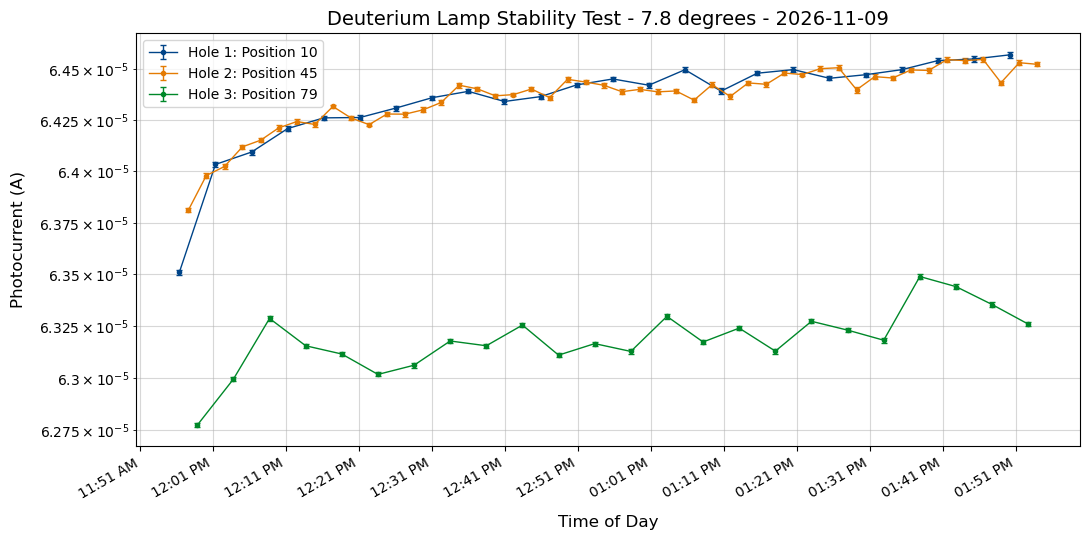

In [88]:
# Stability Test - plot all three hole positions, assumuming the data has been separated beforehand

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import numpy as np
import os

# LOAD DATA
#path_file = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Stability\test_stability_20260721.txt"
path_files = [r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-09)_Data\hour_3to4_spectrum_hole_num_1.txt",
              r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-09)_Data\hour_3to4_spectrum_hole_num_2.txt",
              r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-09)_Data\hour_3to4_spectrum_hole_num_3.txt"
]

colors = ['#004488',"#E47B03","#008829"]
color_idx = 0
fig, ax = plt.subplots(figsize=(11, 5.5))

for path_file in path_files:
    print(path_file)
    df = pd.read_csv(path_file)

    # Convert timestamps to datetime objects
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df['t_min'] = (df['timestamp'] - df['timestamp'].iloc[0]).dt.total_seconds() / 60

    # EXTRACT STATS & DATE FOR THE TITLE
    experiment_date = df['timestamp'].iloc[0].strftime('%Y-%m-%d')

    duration_hours = df['t_min'].max() / 60
    current_mean_total = df['current_mean_A'].mean()
    current_std_total = df['current_mean_A'].std()
    position = df['position'][0]

    current_sem = df['current_std_A']/np.sqrt(df['n_samples']) # Standard error on the mean
    lamp_err = current_std_total**2 - (current_sem**2).mean() # Compare the std on the meaned current to the average sem
    
    print(f"STABILITY REPORT - Hole {color_idx+1}")
    print(f"Total Duration: {duration_hours:.2f} hours")
    print(f"Global Mean Photocurrent: {current_mean_total:.6e} ± {current_std_total:.6e} A")
    print(f"Lamp Err: {lamp_err}")

    ax.errorbar(df['timestamp'], df['current_mean_A'], yerr=df['current_std_A'] / np.sqrt(df['n_samples']), color=colors[color_idx], linestyle='-', linewidth=1, fmt='o', markersize=3, elinewidth=1, capsize=2, label=f'Hole {color_idx + 1}: Position {position}')
    color_idx += 1

# PLOTTING
# fig, ax = plt.subplots(figsize=(11, 5.5))

# ax.errorbar(df['timestamp'], df['current_mean_A'], yerr=df['current_std_A'] / np.sqrt(df['n_samples']), color='#004488', linestyle='-', linewidth=1, fmt='o', markersize=3, elinewidth=1, capsize=2, label='Photocurrent (mean ± std)')

ax.set_title(f'Deuterium Lamp Stability Test - 7.8 degrees - {experiment_date}', fontsize=14)
ax.set_xlabel('Time of Day', fontsize=12, labelpad=10)
ax.set_ylabel('Photocurrent (A)', fontsize=12, labelpad=10)
ax.set_yscale('log')

ax.grid(True, which='Both', linestyle='-', alpha=0.5, color='#b0b0b0')

# TIME AXIS FORMATTING (12-hour system, hour & half-hour ticks)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%I:%M %p'))
#ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=[0, 30]))
ax.xaxis.set_major_locator(mdates.MinuteLocator(interval=10))
fig.autofmt_xdate(rotation=30, ha='right')

#save_path = os.path.join(r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Stability\stability_at_5.65deg_plot_data_5min_intervals_20260721.png")
#plt.savefig(save_path, dpi=300, bbox_inches='tight')
#plt.savefig("stability_report_hour_3to4_all_holes_(09-11-2026).png", dpi=600, bbox_inches='tight')

plt.legend()
plt.tight_layout()
plt.show()

### Lin fit and volatility - rewritten
* see prev cell

C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\Data\(2026-10-11)_Stability_data\D2lamp_128nm_stability.txt
LINEAR FIT REPORT
New Start Time: 11:21 AM
New Start Time: 01:21 PM
Mean Current (Filtered Window): 1.026363e-06 A
Absolute Slope: 5.220462e-09 A/hour
Relative Slope (%): 0.5086 ± 0.0252 % per hour
Relative Slope (%): 0.008477 ± 0.0004 % per minute

STEP-TO-STEP VOLATILITY REPORT
Number of steps analyzed: 24
Average step variation: +0.0360 %
Step variation standard deviation: 0.0920 %


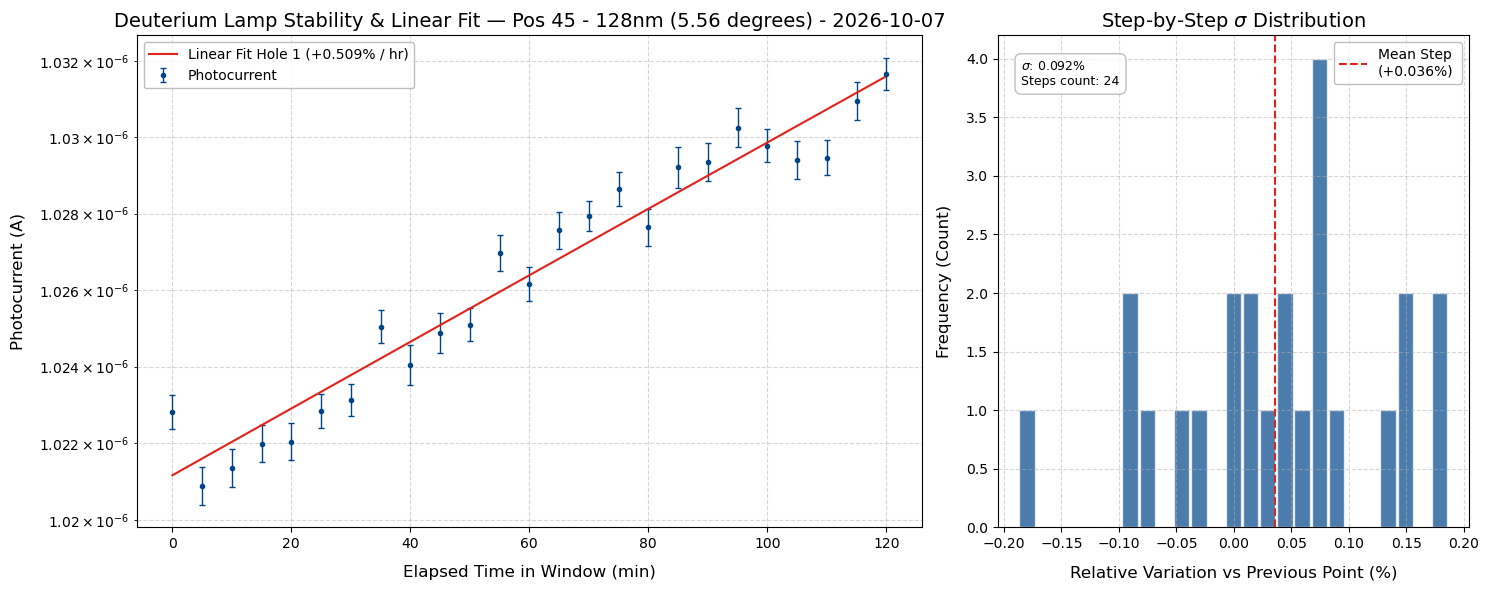

In [4]:
# STABILITY ANALYSIS - LINEAR FIT & VOLATILITY HISTOGRAM 
# plot all three hole positions, assumuming the data has been separated beforehand
# Note this has errorbars and filtered window twice... easy to change back.

import os
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# LOAD DATA
path_files = [r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-09)_Data\hour_1_spectrum_hole_num_1.txt",
              r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-09)_Data\hour_1_spectrum_hole_num_2.txt",
              r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\(2026-11-09)_Data\hour_1_spectrum_hole_num_3.txt"
]


path_files = [r"C:\Users\laugh\lea-summer-2026-internship-forked\lea-summer_2026_Internship\2. Deuterium Lamp\Data\(2026-10-11)_Stability_data\D2lamp_128nm_stability.txt"]

colors = ['#004488',"#E47B03","#008829"]
lin_fit_colors = ['#e32219',"#E47B03","#008829"]
color_idx = 0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [2, 1.2]})

for path_file in path_files:
    print(path_file)
    df = pd.read_csv(path_file)

    #df = pd.read_csv(path_file)
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df['t_min'] = (df['timestamp'] - df['timestamp'].iloc[0]).dt.total_seconds() / 60

    # FILTER DATA (Start at 10:25 AM, when lamp is "stable")
    # Cannot be bothered to figure out the times... use like 30
    df_filtered = df[df['t_min'] >= 30.0].copy()
    df_filtered = df_filtered[df_filtered['t_min'] <= 150.0].copy() # cuts off the step seen at the end...

    # CALCULATE LINEAR FIT & SLOPE IN %
    # Convert filtered timestamps to numerical minutes/hours from the new start point
    time_minutes = df_filtered['t_min'].values - df_filtered['t_min'].min()
    time_hours = time_minutes / 60.0
    current_vals = df_filtered['current_mean_A'].values
    current_sem = df_filtered['current_std_A'] / np.sqrt(df_filtered['n_samples']) # sem
    position = df['position'][0]

    # Fit a first-degree polynomial (straight line): y = mx + c
    coeff, cov = np.polyfit(time_hours, current_vals, 1, w=1/current_sem, cov=True)
    slope, intercept = coeff
    param_errors = np.sqrt(np.diag(cov))
    slope_error = param_errors[0]
    fit_line = slope * time_hours + intercept

    # Calculate relative slope percentage based on the global mean of this window
    mean_current = current_vals.mean()
    current_std_total = current_vals.std()
    slope_pct_per_hour = (slope / mean_current) * 100
    slope_pct_per_hour_err = slope_pct_per_hour * np.sqrt((slope_error / slope)**2 + (current_std_total/mean_current)**2)
    slope_pct_per_minute = slope_pct_per_hour / 60.0
    slope_pct_per_minute_err = slope_pct_per_hour_err / 60.0

    # Extract info for the title
    experiment_date = df_filtered['timestamp'].iloc[0].strftime('%Y-%m-%d')

    print("LINEAR FIT REPORT")
    print(f"New Start Time: {df_filtered['timestamp'].iloc[0].strftime('%I:%M %p')}")
    print(f"New Start Time: {df_filtered['timestamp'].iloc[-1].strftime('%I:%M %p')}")
    print(f"Mean Current (Filtered Window): {mean_current:.6e} A")
    print(f"Absolute Slope: {slope:.6e} A/hour")
    print(f"Relative Slope (%): {slope_pct_per_hour:.4f} ± {slope_pct_per_hour_err:.4f} % per hour")
    print(f"Relative Slope (%): {slope_pct_per_minute:.6f} ± {slope_pct_per_minute_err:.4f} % per minute")

    # COMPUTE POINT-BY-POINT RELATIVE DIFFERENCES
    step_diffs = np.diff(current_vals)
    relative_diffs_pct = (step_diffs / current_vals[:-1]) * 100
    mean_step = np.mean(relative_diffs_pct)
    std_step = np.std(relative_diffs_pct)

    print("\nSTEP-TO-STEP VOLATILITY REPORT")
    print(f"Number of steps analyzed: {len(relative_diffs_pct)}")
    print(f"Average step variation: {mean_step:+.4f} %")
    print(f"Step variation standard deviation: {std_step:.4f} %")

    # PLOTTING
    # fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [2, 1.2]})

    # LEFT PLOT: Long-term Time Evolution & Drift
    
    ax1.errorbar(time_minutes, current_vals, yerr=current_sem, color=colors[color_idx], linewidth=1, fmt='o', markersize=3, elinewidth=1, capsize=2, label='Photocurrent')
    ax1.plot(time_minutes, fit_line, color=lin_fit_colors[color_idx], linestyle='-', linewidth=1.5,
            label=f'Linear Fit Hole {color_idx + 1} ({slope_pct_per_hour:+.3f}% / hr)')

    # RIGHT PLOT: Short-term Step Volatility Histogram
    counts, bins, patches = ax2.hist(relative_diffs_pct, bins=25, color=colors[color_idx],
                                 edgecolor='white', alpha=0.7, rwidth=0.9)
    ax2.axvline(mean_step, color=lin_fit_colors[color_idx], linestyle='--', linewidth=1.5,
           label=f'Mean Step \n({mean_step:+.3f}%)')
    stats_box = f"$\\sigma$: {std_step:.3f}% \nSteps count: {len(relative_diffs_pct)}"
    ax2.text(0.05, 0.95, stats_box, transform=ax2.transAxes, fontsize=9,
         verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#b0b0b0', alpha=0.8))
    color_idx += 1

    
# ax1.set_ylim(5.3e-5, 5.4e-5)
ax1.set_yscale('log')
ax1.set_title(f'Deuterium Lamp Stability & Linear Fit — Pos 45 - 128nm (5.56 degrees) - {experiment_date}', fontsize=14)
ax1.set_xlabel('Elapsed Time in Window (min)', fontsize=12, labelpad=10)
ax1.set_ylabel('Photocurrent (A)', fontsize=12, labelpad=10)
ax1.grid(True, which="both", linestyle='--', alpha=0.5, color='#b0b0b0')

#ax1.xaxis.set_major_formatter(mdates.DateFormatter('%I:%M %p'))
#ax1.xaxis.set_major_locator(mdates.MinuteLocator(byminute=[0, 30]))
#ax1.xaxis.set_major_locator(mdates.MinuteLocator(interval=5))
#ax1.tick_params(axis='x', rotation=30)
ax1.legend(loc='upper left', frameon=True, edgecolor='#b0b0b0')

# RIGHT PLOT: Short-term Step Volatility Histogram
#counts, bins, patches = ax2.hist(relative_diffs_pct, bins=25, color='#004488',
#                                edgecolor='white', alpha=0.85, rwidth=0.9)
#ax2.axvline(mean_step, color='#e32219', linestyle='--', linewidth=1.5,
#           label=f'Mean Step \n({mean_step:+.3f}%)')

ax2.set_title('Step-by-Step $\\sigma$ Distribution', fontsize=14)
ax2.set_xlabel('Relative Variation vs Previous Point (%)', fontsize=12, labelpad=10)
ax2.set_ylabel('Frequency (Count)', fontsize=12, labelpad=10)
ax2.grid(True, linestyle='--', alpha=0.5, color='#b0b0b0')
ax2.legend(loc='upper right', frameon=True, edgecolor='#b0b0b0')

#stats_box = f"$\\sigma$: {std_step:.3f}% \nSteps count: {len(relative_diffs_pct)}"
#ax2.text(0.05, 0.95, stats_box, transform=ax2.transAxes, fontsize=9,
#         verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#b0b0b0', alpha=0.8))

plt.tight_layout()

#save_path = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Stability\stability_5.65deg_5min_intervals_20260721.png"
#os.makedirs(os.path.dirname(save_path), exist_ok=True)
#plt.savefig("stability_and_volatility_report_hour_1_all_holes_(09-11-2026).png", dpi=600, bbox_inches='tight')

plt.show()

## Done before me - Not used yet - Same thing as above but for different data?

In [ ]:
""" # SAME THING - DATA TAKEN 2026/07/22

import os
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# LOAD DATA
path_file = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Stability\test_stability_20260722_no3_long.txt"
df = pd.read_csv(path_file)
df['timestamp'] = pd.to_datetime(df['timestamp'])

# FILTER DATA (Start at 10:25 AM,when lamp is "stable")
df_filtered = df[df['t_min'] >= 15.0].copy()

# CALCULATE LINEAR FIT & SLOPE IN %
# Convert filtered timestamps to numerical minutes/hours from the new start point
time_minutes = df_filtered['t_min'].values - df_filtered['t_min'].min()
time_hours = time_minutes / 60.0
current_vals = df_filtered['current_mean_A'].values

# Fit a first-degree polynomial (straight line): y = mx + c
slope, intercept = np.polyfit(time_hours, current_vals, 1)
fit_line = slope * time_hours + intercept

# Calculate relative slope percentage based on the global mean of this window
mean_current = np.mean(current_vals)
slope_pct_per_hour = (slope / mean_current) * 100
slope_pct_per_minute = slope_pct_per_hour / 60.0

# Extract info for the title
experiment_date = df_filtered['timestamp'].iloc[0].strftime('%Y-%m-%d')

print("LINEAR FIT REPORT")
print(f"New Start Time: {df_filtered['timestamp'].iloc[0].strftime('%I:%M %p')}")
print(f"Mean Current (Filtered Window): {mean_current:.6e} A")
print(f"Absolute Slope: {slope:.6e} A/hour")
print(f"Relative Slope (%): {slope_pct_per_hour:.4f} % per hour")
print(f"Relative Slope (%): {slope_pct_per_minute:.6f} % per minute")

# COMPUTE POINT-BY-POINT RELATIVE DIFFERENCES
step_diffs = np.diff(current_vals)
relative_diffs_pct = (step_diffs / current_vals[:-1]) * 100
mean_step = np.mean(relative_diffs_pct)
std_step = np.std(relative_diffs_pct)

print("\nSTEP-TO-STEP VOLATILITY REPORT")
print(f"Number of steps analyzed: {len(relative_diffs_pct)}")
print(f"Average step variation: {mean_step:+.4f} %")
print(f"Step variation standard deviation: {std_step:.4f} %")

# PLOTTING
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [2, 1.2]})

# LEFT PLOT: Long-term Time Evolution & Drift
ax1.set_yscale('log')
ax1.plot(df_filtered['timestamp'], current_vals, color='#004488', linewidth=2, label='Photocurrent')
ax1.plot(df_filtered['timestamp'], fit_line, color='#e32219', linestyle='--', linewidth=1.5,
         label=f'Linear Fit ({slope_pct_per_hour:+.3f}% / hr)')

if (df_filtered['current_std_A'] > 0).any():
    ax1.fill_between(
        df_filtered['timestamp'],
        current_vals - df_filtered['current_std_A'],
        current_vals + df_filtered['current_std_A'],
        color='#004488', alpha=0.12, label='Uncertainty ($\\pm\\sigma$)'
    )

ax1.set_title(f'Deuterium Lamp Stability & Linear Fit — {experiment_date}', fontsize=14)
ax1.set_xlabel('Time of Day', fontsize=12, labelpad=10)
ax1.set_ylabel('Photocurrent (A) — Log Scale', fontsize=12, labelpad=10)
ax1.grid(True, which="both", linestyle='--', alpha=0.5, color='#b0b0b0')

ax1.xaxis.set_major_formatter(mdates.DateFormatter('%I:%M %p'))
ax1.xaxis.set_major_locator(mdates.MinuteLocator(byminute=[0, 30]))
ax1.tick_params(axis='x', rotation=30)
ax1.legend(loc='upper left', frameon=True, edgecolor='#b0b0b0')

# RIGHT PLOT: Short-term Step Volatility Histogram
counts, bins, patches = ax2.hist(relative_diffs_pct, bins=25, color='#004488',
                                 edgecolor='white', alpha=0.85, rwidth=0.9)
ax2.axvline(mean_step, color='#e32219', linestyle='--', linewidth=1.5,
           label=f'Mean Step \n({mean_step:+.3f}%)')

ax2.set_title('Step-by-Step $\\sigma$ Distribution', fontsize=14)
ax2.set_xlabel('Relative Variation vs Previous Point (%)', fontsize=12, labelpad=10)
ax2.set_ylabel('Frequency (Count)', fontsize=12, labelpad=10)
ax2.grid(True, linestyle='--', alpha=0.5, color='#b0b0b0')
ax2.legend(loc='upper right', frameon=True, edgecolor='#b0b0b0')

stats_box = f"$\\sigma$: {std_step:.3f}% \nSteps count: {len(relative_diffs_pct)}"
ax2.text(0.05, 0.95, stats_box, transform=ax2.transAxes, fontsize=9,
         verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#b0b0b0', alpha=0.8))

plt.tight_layout()

save_path = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Stability\stability_5.65deg_2min_intervals_20260722.png"
os.makedirs(os.path.dirname(save_path), exist_ok=True)
plt.savefig(save_path, dpi=300, bbox_inches='tight')

plt.show() """

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\leaga\\OneDrive\\Desktop\\Internship UoM\\VUV Monochromator\\2. Deuterium Lamp\\Stability\\test_stability_20260722_no3_long.txt'

DAY-TO-DAY DRIFT ANALYSIS
At t = 99 min  -> Yesterday: 4.376111e-04 A | Today (no1): 2.126128e-05 A | Shift: -95.14 %
At t = 163 min -> Yesterday: 4.408625e-04 A | Today (no2): 2.134300e-05 A | Shift: -95.16 %
At t = 261 min -> Yesterday: 4.409228e-04 A | Today (no3): 1.538342e-03 A | Shift: +248.89 %


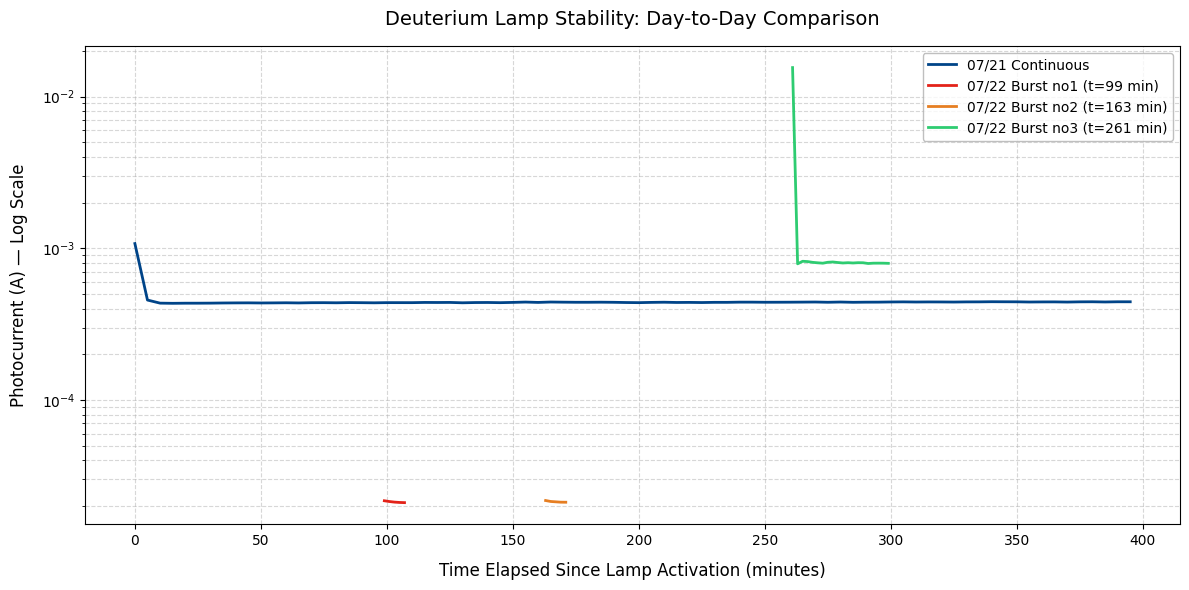

In [ ]:
""" # DATA COMPARISON - 2026/07/21 & 2026/07/22 - OBVIOUSLY WE DID NOT USE THE SAME APERTURE

import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# LOAD 2026/07/21 DATA
path_yesterday = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Stability\test_stability_20260721.txt"
df_yesterday = pd.read_csv(path_yesterday)

# LOAD 2026/07/22 DATA
base_dir = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Stability"

path_today_1 = os.path.join(base_dir, "test_stability_20260722_no1.txt")
path_today_2 = os.path.join(base_dir, "test_stability_20260722_no2.txt")
path_today_3 = os.path.join(base_dir, "test_stability_20260722_no3_long.txt")

df_today_1 = pd.read_csv(path_today_1)
df_today_2 = pd.read_csv(path_today_2)
df_today_3 = pd.read_csv(path_today_3)

# RECONSTRUCT TIME AXIS FOR 2026/07/22 DATA (2 min intervals)
# Burst 1: Starts at t = 99 min (5 points)
n_points_1 = len(df_today_1)
time_burst_1 = 99.0 + np.arange(n_points_1) * 2.0

# Burst 2: Starts at t = 163 min (5 points)
n_points_2 = len(df_today_2)
time_burst_2 = 163.0 + np.arange(n_points_2) * 2.0

# Burst 3: Starts at t = 261 min (20 points)
n_points_3 = len(df_today_3)
time_burst_3 = 261.0 + np.arange(n_points_3) * 2.0

# TENDENCY & VALUE COMPARISON
# Interpolate 2026/07/21 baseline value at exactly t = 99, 163 and 261 min
val_yes_at_99 = np.interp(99.0, df_yesterday['t_min'], df_yesterday['current_mean_A'])
val_yes_at_163 = np.interp(163.0, df_yesterday['t_min'], df_yesterday['current_mean_A'])
val_yes_at_261 = np.interp(261.0, df_yesterday['t_min'], df_yesterday['current_mean_A'])

mean_today_1 = df_today_1['current_mean_A'].mean()
mean_today_2 = df_today_2['current_mean_A'].mean()
mean_today_3 = df_today_3['current_mean_A'].mean()

# Calculate relative shifts (%)
shift_99_pct = ((mean_today_1 - val_yes_at_99) / val_yes_at_99) * 100
shift_163_pct = ((mean_today_2 - val_yes_at_163) / val_yes_at_163) * 100
shift_261_pct = ((mean_today_3 - val_yes_at_261) / val_yes_at_261) * 100

print("DAY-TO-DAY DRIFT ANALYSIS")
print(f"At t = 99 min  -> Yesterday: {val_yes_at_99:.6e} A | Today (no1): {mean_today_1:.6e} A | Shift: {shift_99_pct:+.2f} %")
print(f"At t = 163 min -> Yesterday: {val_yes_at_163:.6e} A | Today (no2): {mean_today_2:.6e} A | Shift: {shift_163_pct:+.2f} %")
print(f"At t = 261 min -> Yesterday: {val_yes_at_261:.6e} A | Today (no3): {mean_today_3:.6e} A | Shift: {shift_261_pct:+.2f} %")

# PLOTTING THE OVERLAY
fig, ax = plt.subplots(figsize=(12, 6))

ax.set_yscale('log')

ax.plot(df_yesterday['t_min'], df_yesterday['current_mean_A'], color='#004488', linewidth=2, label='07/21 Continuous')
ax.plot(time_burst_1, df_today_1['current_mean_A'], color='#e32219', linewidth=2, markersize=4, label='07/22 Burst no1 (t=99 min)')
ax.plot(time_burst_2, df_today_2['current_mean_A'], color='#e67e22', linewidth=2, markersize=4, label='07/22 Burst no2 (t=163 min)')
ax.plot(time_burst_3, df_today_3['current_mean_A'], color='#2ecc71', linewidth=2, markersize=4, label='07/22 Burst no3 (t=261 min)')

ax.set_title('Deuterium Lamp Stability: Day-to-Day Comparison', fontsize=14, pad=15)
ax.set_xlabel('Time Elapsed Since Lamp Activation (minutes)', fontsize=12, labelpad=10)
ax.set_ylabel('Photocurrent (A) — Log Scale', fontsize=12, labelpad=10)

ax.grid(True, which="both", linestyle='--', alpha=0.5, color='#b0b0b0')
ax.legend(loc='upper right', frameon=True, edgecolor='#b0b0b0')

save_path = os.path.join(base_dir, "day_to_day_stability_overlay.png")
os.makedirs(os.path.dirname(save_path), exist_ok=True)
plt.savefig(save_path, dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show() """

## Done before me - Analysing affect of the slit and angle on the recorded photocurrent

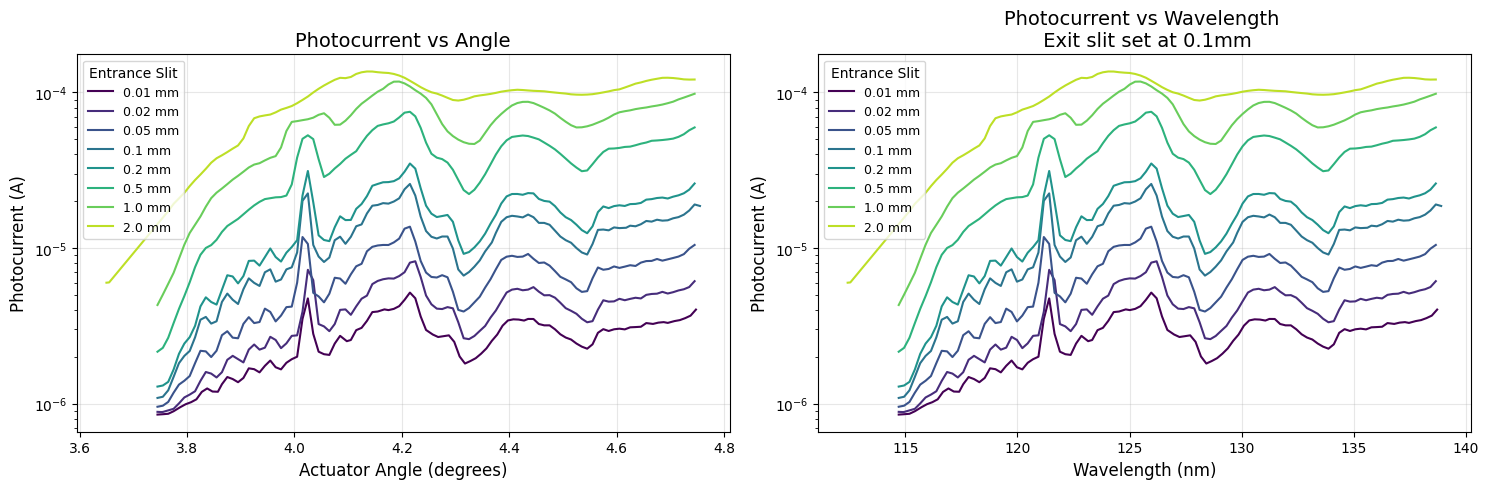

In [ ]:
""" # 1ST RESOLUTION TEST - FIXED EXIT SLIT AND CHANGING THE ENTRANCE SLIT

import matplotlib.pyplot as plt
import numpy as np
import os

def actuator_angle_to_wavelength(theta_deg):
    d = 835.5          # nm (1 / 1200 lines/mm)
    phi = 35           # degrees (half deviation angle)
    gamma = 1.00694    # actuator scaling factor
    theta0 = -1.02898  # degrees (angular offset)
    m = 1              # first diffraction order

    theta_rad = np.radians(theta_deg)
    theta0_rad = np.radians(theta0)
    phi_rad = np.radians(phi)

    C = 2 * d * np.cos(phi_rad)
    wavelength = (C * np.sin(gamma * (theta_rad - theta0_rad))) / m

    return wavelength

base_path = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Resolution"

filenames = [
    "resolution_3.75_4.75_0.01_0.01_0.1.txt",
    "resolution_3.75_4.75_0.01_0.02_0.1.txt",
    "resolution_3.75_4.75_0.01_0.05_0.1.txt",
    "resolution_3.75_4.75_0.01_0.1_0.1.txt",
    "resolution_3.75_4.75_0.01_0.2_0.1.txt",
    "resolution_3.75_4.75_0.01_0.5_0.1.txt",
    "resolution_3.75_4.75_0.01_1_0.1.txt",
    "resolution_3.75_4.75_0.01_2_0.1.txt",
]

def extract_slit(filename):
    match = re.search(r'0\.01_+([\d.]+)_0\.1\.txt', filename)
    return float(match.group(1)) if match else None

colors = plt.cm.viridis(np.linspace(0, 0.9, len(filenames)))

# PLOTTING
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

for i, filename in enumerate(filenames):
    filepath = os.path.join(base_path, filename)
    slit = extract_slit(filename)

    try:
        data = np.loadtxt(filepath, delimiter=',', usecols=(0, 1))
        angle = data[:, 0]
        photocurrent = data[:, 1]
        wavelength = actuator_angle_to_wavelength(angle)

        # Label with aperture value
        label = f"{slit} mm" if slit is not None else filename

        # Plot 1: Angle
        ax1.plot(angle, photocurrent, color=colors[i], linewidth=1.5, label=label)

        # Plot 2: Wavelength
        ax2.plot(wavelength, photocurrent, color=colors[i], linewidth=1.5, label=label)

    except Exception as e:
        print(f"Erreur: {filename} - {e}")

# Plot 1 config
ax1.set_xlabel('Actuator Angle (degrees)', fontsize=12)
ax1.set_ylabel('Photocurrent (A)', fontsize=12)
ax1.set_title('Photocurrent vs Angle', fontsize=14)
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3)
ax1.legend(title="Entrance Slit", fontsize=9)

# Plot 2 config
ax2.set_xlabel('Wavelength (nm)', fontsize=12)
ax2.set_ylabel('Photocurrent (A)', fontsize=12)
ax2.set_title('Photocurrent vs Wavelength \n Exit slit set at 0.1mm', fontsize=14)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)
ax2.legend(title="Entrance Slit", fontsize=9)

save_path = os.path.join(base_path, "resolution_comparison_aperture_entrance_slit.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show() """

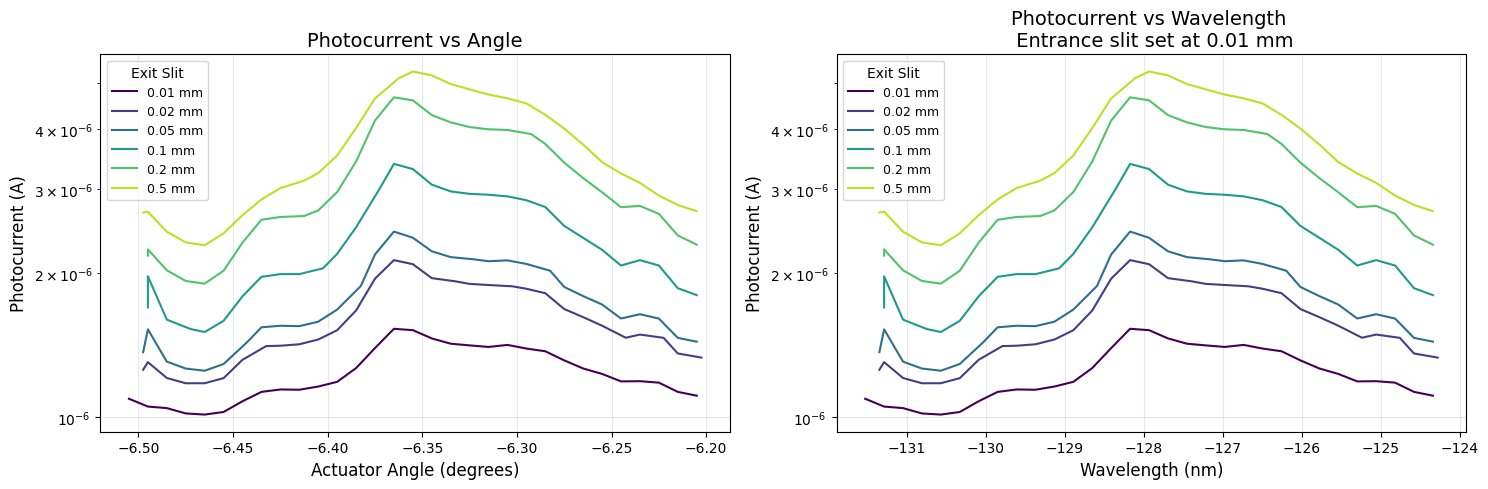

In [ ]:
""" # 2ND RESOLUTION TEST - FIXED ENTRANCE SLIT AND CHANGING THE EXIT SLIT

import matplotlib.pyplot as plt
import numpy as np
import os

def actuator_angle_to_wavelength(theta_deg):
    d = 835.5          # nm (1 / 1200 lines/mm)
    phi = 35           # degrees (half deviation angle)
    gamma = 1.00694    # actuator scaling factor
    theta0 = -1.02898  # degrees (angular offset)
    m = 1              # first diffraction order

    theta_rad = np.radians(theta_deg)
    theta0_rad = np.radians(theta0)
    phi_rad = np.radians(phi)

    C = 2 * d * np.cos(phi_rad)
    wavelength = (C * np.sin(gamma * (theta_rad - theta0_rad))) / m

    return wavelength

base_path = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Resolution"

filenames = ["resolution_-6.5_-6.2_0.01_0.01_0.01.txt",
             "resolution_-6.5_-6.2_0.01_0.01_0.02.txt",
             "resolution_-6.5_-6.2_0.01_0.01_0.05.txt",
             "resolution_-6.5_-6.2_0.01_0.01_0.1.txt",
             "resolution_-6.5_-6.2_0.01_0.01_0.2.txt",
             "resolution_-6.5_-6.2_0.01_0.01_0.5.txt"
             ]

def extract_slit(filename):
    # Capture le dernier nombre avant .txt
    match = re.search(r'_([\d.]+)\.txt$', filename)
    return float(match.group(1)) if match else None


colors = plt.cm.viridis(np.linspace(0, 0.9, len(filenames)))

# PLOTTING
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

for i, filename in enumerate(filenames):
    filepath = os.path.join(base_path, filename)
    slit = extract_slit(filename)

    try:
        data = np.loadtxt(filepath, delimiter=',', usecols=(0, 1))
        angle = data[:, 0]
        photocurrent = data[:, 1]
        wavelength = actuator_angle_to_wavelength(angle)

        # Label with aperture value
        label = f"{slit} mm" if slit is not None else filename

        # Plot 1: Angle
        ax1.plot(angle, photocurrent, color=colors[i], linewidth=1.5, label=label)

        # Plot 2: Wavelength
        ax2.plot(wavelength, photocurrent, color=colors[i], linewidth=1.5, label=label)

    except Exception as e:
        print(f"Erreur: {filename} - {e}")

# Plot 1 config
ax1.set_xlabel('Actuator Angle (degrees)', fontsize=12)
ax1.set_ylabel('Photocurrent (A)', fontsize=12)
ax1.set_title('Photocurrent vs Angle', fontsize=14)
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3)
ax1.legend(title="Exit Slit", fontsize=9)

# Plot 2 config
ax2.set_xlabel('Wavelength (nm)', fontsize=12)
ax2.set_ylabel('Photocurrent (A)', fontsize=12)
ax2.set_title('Photocurrent vs Wavelength \n Entrance slit set at 0.01 mm', fontsize=14)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)
ax2.legend(title="Exit Slit", fontsize=9)

save_path = os.path.join(base_path, "resolution_comparison_aperture_exit_slit.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show() """

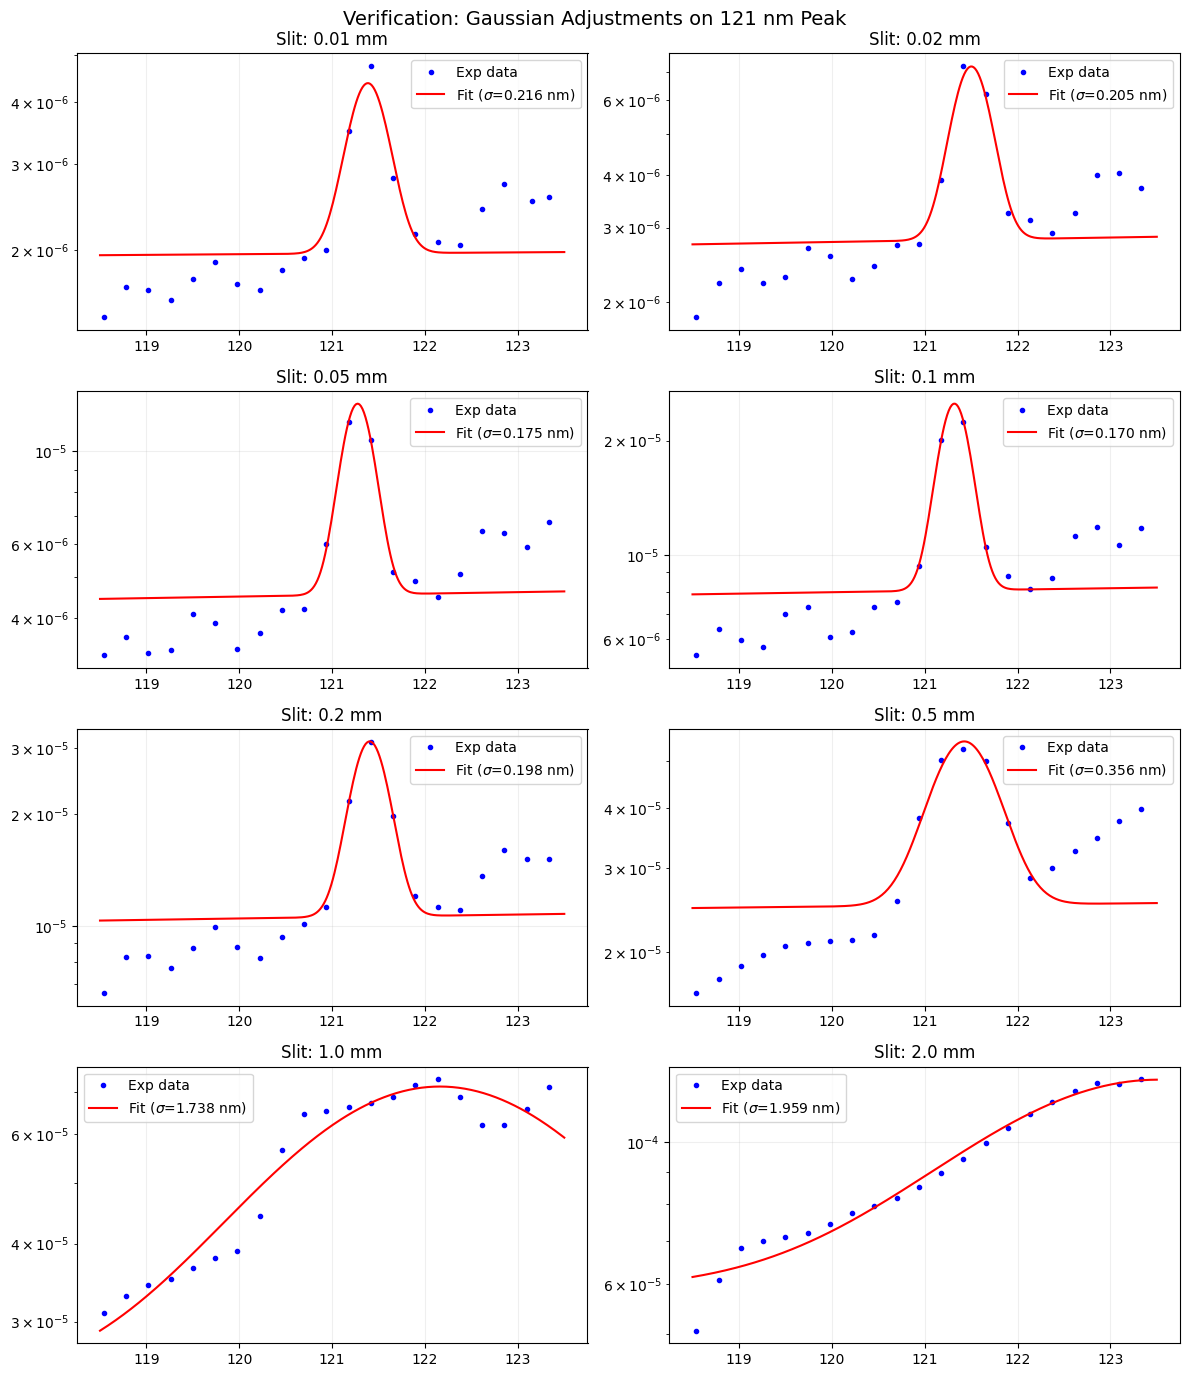

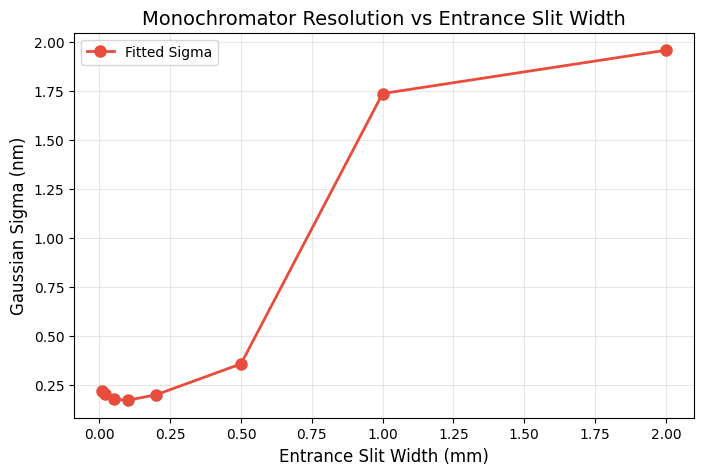

In [ ]:
""" # RESOLUTION TEST ANALYSIS - ENTRANCE SLIT VARIATION, EXIT SLIT FIXED - INITIAL CHECK, DIFFERENT PEAK THAN THE 2 NEXT CELLS

import matplotlib.pyplot as plt
import numpy as np
import os
from scipy.optimize import curve_fit

def actuator_angle_to_wavelength(theta_deg):
    d = 835.5          # nm
    phi = 35           # degrees
    gamma = 1.00694    # actuator scaling factor
    theta0 = -1.02898  # degrees (angular offset)
    m = 1
    C = 2 * d * np.cos(np.radians(phi))
    return (C * np.sin(gamma * (np.radians(theta_deg) - np.radians(theta0)))) / m

def gaussian_with_background(x, amp, xo, sigma, slope, intercept):
    return amp * np.exp(-((x - xo) ** 2) / (2 * sigma ** 2)) + (slope * x + intercept)

base_path = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Resolution"

filenames = [
    "resolution_3.75_4.75_0.01_0.01_0.1.txt",
    "resolution_3.75_4.75_0.01_0.02_0.1.txt",
    "resolution_3.75_4.75_0.01_0.05_0.1.txt",
    "resolution_3.75_4.75_0.01_0.1_0.1.txt",
    "resolution_3.75_4.75_0.01_0.2_0.1.txt",
    "resolution_3.75_4.75_0.01_0.5_0.1.txt",
    "resolution_3.75_4.75_0.01_1_0.1.txt",
    "resolution_3.75_4.75_0.01_2_0.1.txt"
]

def extract_slit(filename):
    match = re.search(r'0\.01_+([\d.]+)_0\.1\.txt', filename)
    return float(match.group(1)) if match else None

WL_MIN = 118.5
WL_MAX = 123.5

slit_sizes = []
sigmas = []

fig_check, axes_check = plt.subplots(4, 2, figsize=(12, 14))
axes_flat = axes_check.flatten()

for i, filename in enumerate(filenames):
    filepath = os.path.join(base_path, filename)
    slit = extract_slit(filename)
    if slit is None:
        continue

    try:
        data = np.loadtxt(filepath, delimiter=',', usecols=(0, 1))
        wavelength = actuator_angle_to_wavelength(data[:, 0])
        photocurrent = data[:, 1]

        mask = (wavelength >= WL_MIN) & (wavelength <= WL_MAX)
        w_cut = wavelength[mask]
        p_cut = photocurrent[mask]

        if len(w_cut) < 5:
            print(f"Attention : aucun point dans la zone [{WL_MIN}-{WL_MAX} nm] pour {filename}")
            continue

        xo_init = w_cut[np.argmax(p_cut)]
        initial_guess = [np.max(p_cut) - np.min(p_cut), xo_init, 0.4, 0.0, np.min(p_cut)]

        bounds = ([0, WL_MIN, 0.01, -1e-3, 0], [np.max(p_cut)*2, WL_MAX, 5.0, 1e-3, np.max(p_cut)])

        popt, _ = curve_fit(gaussian_with_background, w_cut, p_cut, p0=initial_guess, bounds=bounds)

        slit_sizes.append(slit)
        sigmas.append(popt[2])

        ax = axes_flat[i]
        ax.plot(w_cut, p_cut, 'b.', label='Exp data')

        w_fine = np.linspace(WL_MIN, WL_MAX, 300)
        ax.plot(w_fine, gaussian_with_background(w_fine, *popt), 'r-', linewidth=1.5,
                label=f'Fit ($\\sigma$={popt[2]:.3f} nm)')

        ax.set_title(f"Slit: {slit} mm", fontsize=12)
        ax.set_yscale('log')
        ax.grid(True, alpha=0.2)
        ax.legend(fontsize=10)

    except Exception as e:
        print(f"Erreur sur {filename}: {e}")

fig_check.suptitle("Verification: Gaussian Adjustments on 121 nm Peak", fontsize=14, y=0.98)
fig_check.tight_layout()
fig_check.savefig(os.path.join(base_path, "verification_fits_121nm.png"), dpi=200)


# FINAL PLOT
if len(slit_sizes) > 0:
    sort_idx = np.argsort(slit_sizes)
    slit_sizes = np.array(slit_sizes)[sort_idx]
    sigmas = np.array(sigmas)[sort_idx]

    plt.figure(figsize=(8, 5))

    plt.plot(slit_sizes, sigmas, 'o-', color='#e74c3c', linewidth=2, markersize=8, label="Fitted Sigma")

    plt.xlabel('Entrance Slit Width (mm)', fontsize=12)
    plt.ylabel('Gaussian Sigma (nm)', fontsize=12)

    plt.title("Monochromator Resolution vs Entrance Slit Width", fontsize=14)

    plt.grid(True, which="both", alpha=0.3)
    plt.legend(loc="upper left")

    save_path_final = os.path.join(base_path, "resolution_sigma_vs_entrance_slit_121nm.png")
    plt.savefig(save_path_final, dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("\n[ERREUR] Aucun fichier n'a pu être traité.") """

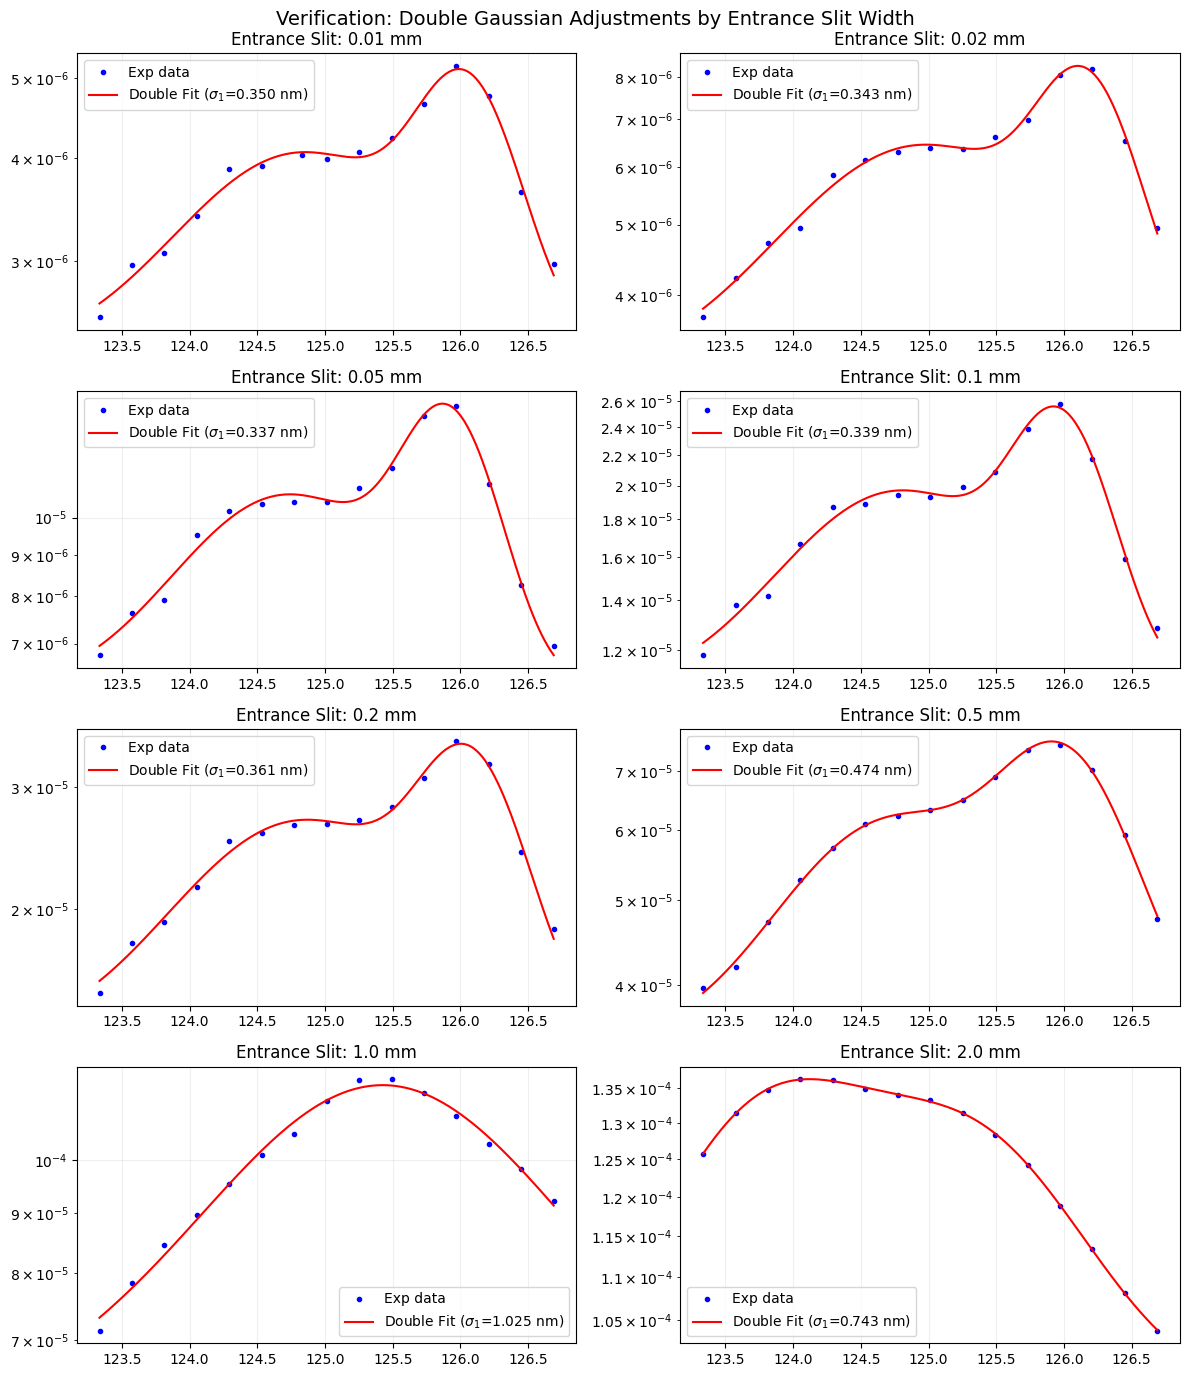

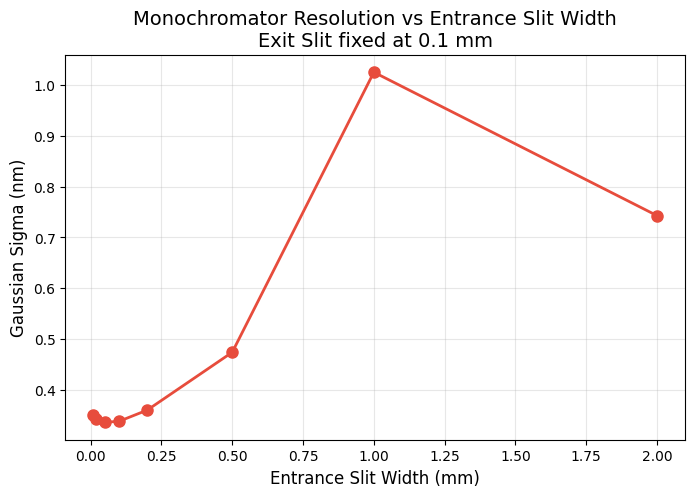

In [ ]:
""" # RESOLUTION TEST ANALYSIS - ENTRANCE SLIT VARIATION, EXIT SLIT FIXED

import matplotlib.pyplot as plt
import numpy as np
import os
from scipy.optimize import curve_fit

def actuator_angle_to_wavelength(theta_deg):
    d = 835.5          # nm
    phi = 35           # degrees
    gamma = 1.00694    # actuator scaling factor
    theta0 = -1.02898  # degrees (angular offset)
    m = 1
    C = 2 * d * np.cos(np.radians(phi))
    return (C * np.sin(gamma * (np.radians(theta_deg) - np.radians(theta0)))) / m

def double_gaussian_with_background(x, amp1, xo1, sigma1, amp2, xo2, sigma2, slope, intercept):
    g1 = amp1 * np.exp(-((x - xo1) ** 2) / (2 * sigma1 ** 2))
    g2 = amp2 * np.exp(-((x - xo2) ** 2) / (2 * sigma2 ** 2))
    return g1 + g2 + (slope * x + intercept)

base_path = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Resolution"

filenames = [
    "resolution_3.75_4.75_0.01_0.01_0.1.txt",
    "resolution_3.75_4.75_0.01_0.02_0.1.txt",
    "resolution_3.75_4.75_0.01_0.05_0.1.txt",
    "resolution_3.75_4.75_0.01_0.1_0.1.txt",
    "resolution_3.75_4.75_0.01_0.2_0.1.txt",
    "resolution_3.75_4.75_0.01_0.5_0.1.txt",
    "resolution_3.75_4.75_0.01_1_0.1.txt",
    "resolution_3.75_4.75_0.01_2_0.1.txt"
]

def extract_slit(filename):
    match = re.search(r'0\.01_+([\d.]+)_0\.1\.txt', filename)
    return float(match.group(1)) if match else None

# STRICT TARGET IN ANGLE (+ CONVERSION IN WAVELENGTH FOR THE MASK AND FIT)
ANGLE_MIN = 4.10
ANGLE_MAX = 4.25

WL_MIN = actuator_angle_to_wavelength(ANGLE_MIN)
WL_MAX = actuator_angle_to_wavelength(ANGLE_MAX)

slit_sizes = []
sigmas_main = []

# 4x2 grid for 8 files
fig_check, axes_check = plt.subplots(4, 2, figsize=(12, 14))
axes_flat = axes_check.flatten()

for i, filename in enumerate(filenames):
    filepath = os.path.join(base_path, filename)
    slit = extract_slit(filename)
    if slit is None:
        continue

    try:
        data = np.loadtxt(filepath, delimiter=',', usecols=(0, 1))
        angles = data[:, 0]
        wavelength = actuator_angle_to_wavelength(angles)
        photocurrent = data[:, 1]

        # Mask for the RoI
        mask = (angles >= ANGLE_MIN) & (angles <= ANGLE_MAX)
        w_cut = wavelength[mask]
        p_cut = photocurrent[mask]

        if len(w_cut) < 8:
            print(f"Warning: Not enough points in the target area to {filename}")
            continue

        # Finding the position of the vertex within the cropped area
        idx_max = np.argmax(p_cut)
        xo_max_wl = w_cut[idx_max]

        wl_lower = min(w_cut.min(), w_cut.max())
        wl_upper = max(w_cut.min(), w_cut.max())

        xo1_init = xo_max_wl
        xo2_init = (wl_lower + wl_upper) / 2.0

        amp1_init = np.max(p_cut) - np.min(p_cut)
        amp2_init = amp1_init * 0.5

        initial_guess = [
            amp1_init, xo1_init, 0.4,  # Pic 1
            amp2_init, xo2_init, 0.5,  # Pic 2
            0.0, np.min(p_cut)         # Fond linéaire
        ]

        bounds = (
            [0, wl_lower - 1.0, 0.02,  0, wl_lower - 1.0, 0.02, -1e-2, 0],
            [amp1_init * 3, wl_upper + 1.0, 4.0,  amp1_init * 3, wl_upper + 1.0, 4.0,  1e-2, np.max(p_cut)]
        )

        popt, _ = curve_fit(double_gaussian_with_background, w_cut, p_cut, p0=initial_guess, bounds=bounds)

        wl_lower = min(WL_MIN, WL_MAX)
        wl_upper = max(WL_MIN, WL_MAX)

        bounds = (
            [0, wl_lower, 0.02,  0, wl_lower, 0.02, -1e-3, 0],
            [amp1_init * 2, wl_upper, 4.0,  amp1_init * 2, wl_upper, 4.0,  1e-3, np.max(p_cut)]
        )

        popt, _ = curve_fit(double_gaussian_with_background, w_cut, p_cut, p0=initial_guess, bounds=bounds)

        # Extraction of the sigma value from the main peak
        slit_sizes.append(slit)
        sigmas_main.append(popt[2])

        # Interim Control Plot
        ax = axes_flat[i]
        ax.plot(w_cut, p_cut, 'b.', label='Exp data')

        w_fine = np.linspace(w_cut.min(), w_cut.max(), 300)
        ax.plot(w_fine, double_gaussian_with_background(w_fine, *popt), 'r-', linewidth=1.5,
                label=f'Double Fit ($\\sigma_1$={popt[2]:.3f} nm)')

        ax.set_title(f"Entrance Slit: {slit} mm", fontsize=12)
        ax.set_yscale('log')
        ax.grid(True, alpha=0.2)
        ax.legend(fontsize=10)

    except Exception as e:
        print(f"Error on {filename}: {e}")

fig_check.suptitle("Verification: Double Gaussian Adjustments by Entrance Slit Width", fontsize=14, y=0.98)
fig_check.tight_layout()
fig_check.savefig(os.path.join(base_path, "verification_fits_entrance_slits_double_gauss.png"), dpi=200)

# FINAL PLOT
if len(slit_sizes) > 0:
    sort_idx = np.argsort(slit_sizes)
    slit_sizes = np.array(slit_sizes)[sort_idx]
    sigmas_main = np.array(sigmas_main)[sort_idx]

    plt.figure(figsize=(8, 5))
    plt.plot(slit_sizes, sigmas_main, 'o-', color='#e74c3c', linewidth=2, markersize=8, label="Main Peak Sigma")

    plt.xlabel('Entrance Slit Width (mm)', fontsize=12)
    plt.ylabel('Gaussian Sigma (nm)', fontsize=12)
    plt.title("Monochromator Resolution vs Entrance Slit Width\nExit Slit fixed at 0.1 mm", fontsize=14)

    plt.grid(True, which="both", alpha=0.3)

    save_path_final = os.path.join(base_path, "resolution_sigma_vs_entrance_slit_double_gauss.png")
    plt.savefig(save_path_final, dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("\n[ERROR] No files could be processed. Check the angles or the conversion to WL.") """

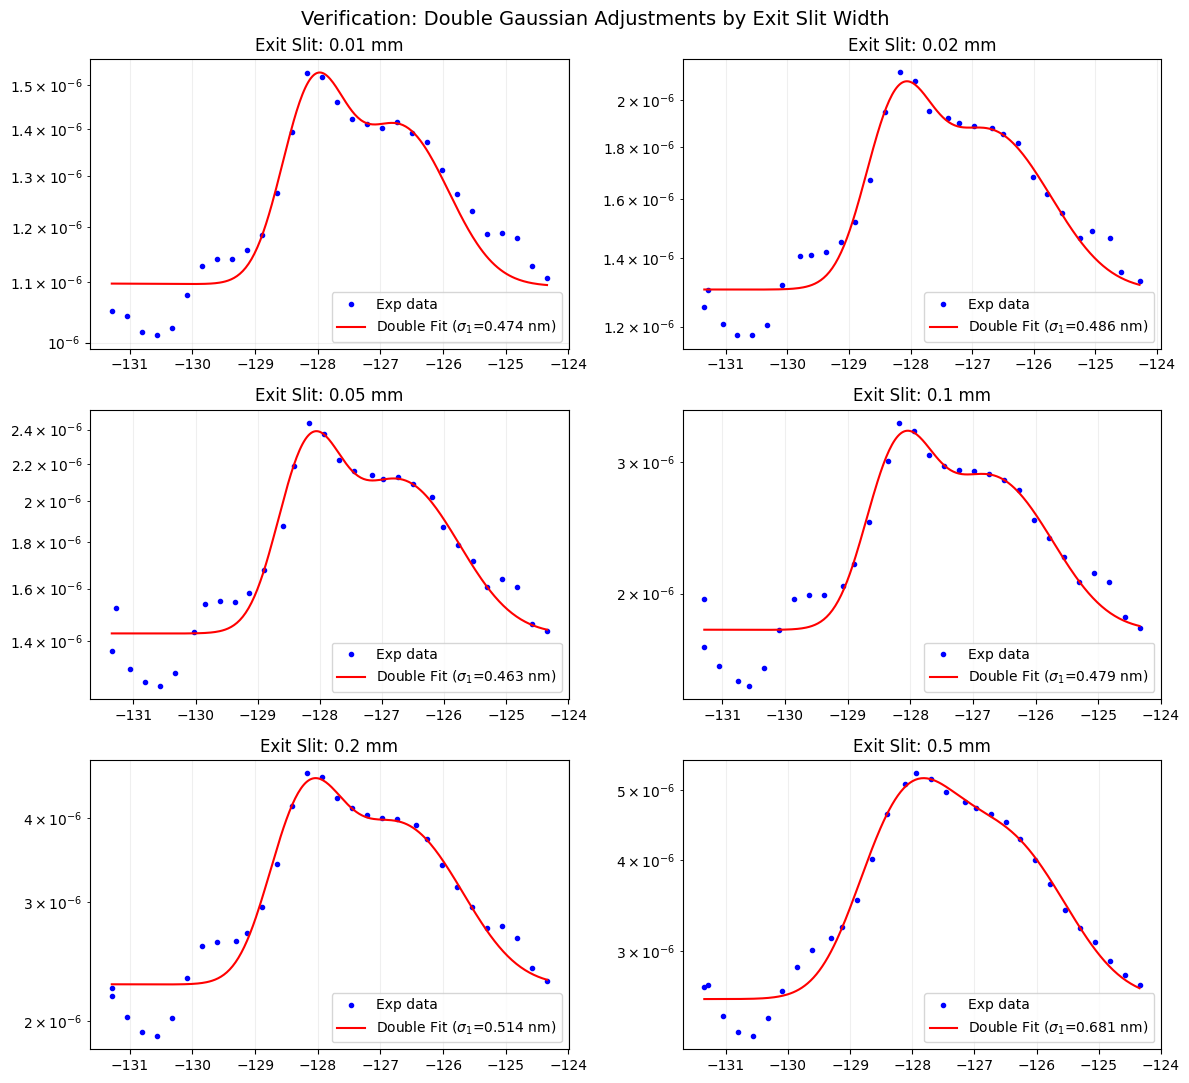

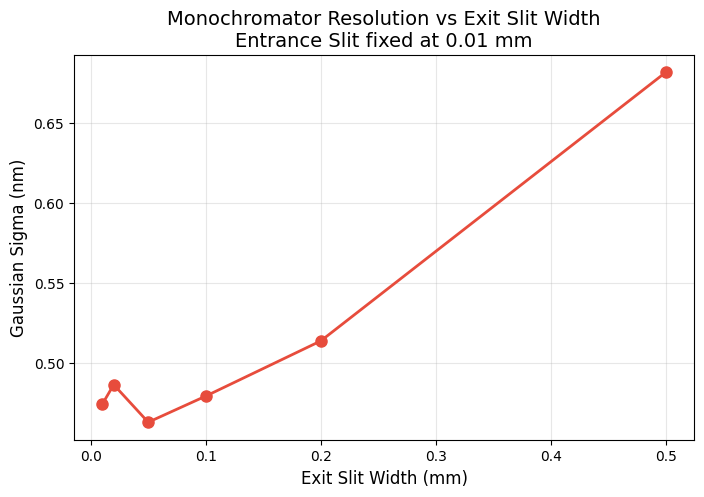

In [ ]:
""" # RESOLUTION TEST ANALYSIS - EXIT SLIT VARIATION, ENTRANCE SLIT FIXED

import matplotlib.pyplot as plt
import numpy as np
import os
import re
from scipy.optimize import curve_fit

def actuator_angle_to_wavelength(theta_deg):
    d = 835.5          # nm
    phi = 35           # degrees
    gamma = 1.00694    # actuator scaling factor
    theta0 = -1.02898  # degrees (angular offset)
    m = 1
    C = 2 * d * np.cos(np.radians(phi))
    return (C * np.sin(gamma * (np.radians(theta_deg) - np.radians(theta0)))) / m

def double_gaussian_with_background(x, amp1, xo1, sigma1, amp2, xo2, sigma2, slope, intercept):
    g1 = amp1 * np.exp(-((x - xo1) ** 2) / (2 * sigma1 ** 2))
    g2 = amp2 * np.exp(-((x - xo2) ** 2) / (2 * sigma2 ** 2))
    return g1 + g2 + (slope * x + intercept)

base_path = r"C:\Users\leaga\OneDrive\Desktop\Internship UoM\VUV Monochromator\2. Deuterium Lamp\Resolution"

filenames = [
    "resolution_-6.5_-6.2_0.01_0.01_0.01.txt",
    "resolution_-6.5_-6.2_0.01_0.01_0.02.txt",
    "resolution_-6.5_-6.2_0.01_0.01_0.05.txt",
    "resolution_-6.5_-6.2_0.01_0.01_0.1.txt",
    "resolution_-6.5_-6.2_0.01_0.01_0.2.txt",
    "resolution_-6.5_-6.2_0.01_0.01_0.5.txt"
]

def extract_slit(filename):
    match = re.search(r'0\.01_([\d.]+)\.txt$', filename)
    return float(match.group(1)) if match else None

WL_MIN = -131.5
WL_MAX = -124.0

slit_sizes = []
sigmas_main = []

fig_check, axes_check = plt.subplots(3, 2, figsize=(12, 11))
axes_flat = axes_check.flatten()

for i, filename in enumerate(filenames):
    filepath = os.path.join(base_path, filename)
    slit = extract_slit(filename)
    if slit is None:
        continue

    try:
        data = np.loadtxt(filepath, delimiter=',', usecols=(0, 1))
        wavelength = actuator_angle_to_wavelength(data[:, 0])
        photocurrent = data[:, 1]

        mask = (wavelength >= WL_MIN) & (wavelength <= WL_MAX)
        w_cut = wavelength[mask]
        p_cut = photocurrent[mask]

        if len(w_cut) < 8:
            continue

        xo1_init = -128.0
        xo2_init = -126.8

        amp1_init = np.max(p_cut) - np.min(p_cut)
        amp2_init = amp1_init * 0.7

        initial_guess = [
            amp1_init, xo1_init, 0.5,  # Peak 1
            amp2_init, xo2_init, 0.6,  # Peak 2
            0.0, np.min(p_cut)         # Background
        ]

        bounds = (
            [0, -129.5, 0.05,  0, -127.5, 0.05, -1e-3, 0],
            [amp1_init*2, -127.5, 3.0,  amp1_init*2, -125.0, 3.0,  1e-3, np.max(p_cut)]
        )

        popt, _ = curve_fit(double_gaussian_with_background, w_cut, p_cut, p0=initial_guess, bounds=bounds)

        # Extract sigma from the main peak
        slit_sizes.append(slit)
        sigmas_main.append(popt[2])

        # Interim Control Plots
        ax = axes_flat[i]
        ax.plot(w_cut, p_cut, 'b.', label='Exp data')

        w_fine = np.linspace(w_cut.min(), w_cut.max(), 300)
        ax.plot(w_fine, double_gaussian_with_background(w_fine, *popt), 'r-', linewidth=1.5,
                label=f'Double Fit ($\\sigma_1$={popt[2]:.3f} nm)')

        ax.set_title(f"Exit Slit: {slit} mm", fontsize=12)
        ax.set_yscale('log')
        ax.grid(True, alpha=0.2)
        ax.legend(fontsize=10)

    except Exception as e:
        print(f"Erreur sur {filename}: {e}")

fig_check.suptitle("Verification: Double Gaussian Adjustments by Exit Slit Width", fontsize=14, y=0.98)
fig_check.tight_layout()
fig_check.savefig(os.path.join(base_path, "verification_fits_exit_slit_double_gauss.png"), dpi=200)

# FINAL PLOT
if len(slit_sizes) > 0:
    sort_idx = np.argsort(slit_sizes)
    slit_sizes = np.array(slit_sizes)[sort_idx]
    sigmas_main = np.array(sigmas_main)[sort_idx]

    plt.figure(figsize=(8, 5))
    plt.plot(slit_sizes, sigmas_main, 'o-', color='#e74c3c', linewidth=2, markersize=8, label="Main Peak Sigma")

    plt.xlabel('Exit Slit Width (mm)', fontsize=12)
    plt.ylabel('Gaussian Sigma (nm)', fontsize=12)
    plt.title("Monochromator Resolution vs Exit Slit Width\nEntrance Slit fixed at 0.01 mm", fontsize=14)

    plt.grid(True, which="both", alpha=0.3)

    save_path_final = os.path.join(base_path, "resolution_sigma_vs_exit_slit_double_gauss.png")
    plt.savefig(save_path_final, dpi=300, bbox_inches='tight')
    plt.show() """